# 1. Human Activity Recognition Using Smartphones

## Project map: where each review lives in this notebook

| Review | Units | What it contains | Sections |
|---|---|---|---|
| **Review 1** | Unit 1 | Problem statement, dataset, statistical analysis (probability, mean/variance, quantiles, covariance, conditional probability, outliers) | §2 EDA + **§2.10 Unit 1 Statistical Analysis** |
| **Review 2** | Units 2 and 3 | Mathematical models and **from-scratch NumPy code**: Bayesian logistic regression (Laplace), linear SVM, ridge regression, PCA, K-means, Gaussian mixture (EM), hierarchical clustering; plus the library classifiers LR / SVM / RF | §3-§5 + **§R2 From-Scratch Models** |
| **Review 3** | Units 4 and 5 | CART, boosting, feature importance, Markov chain, HMM (Forward/Backward/Viterbi), HAPT validation, comparative analysis | Unit 5 Extension, Module 2 (§6-§11), Review 3 summary |


## Problem statement and objectives

**Problem.** Recognise six everyday activities (walking, walking upstairs, walking downstairs, sitting, standing, laying) from
smartphone accelerometer and gyroscope signals. Each row is one 2.56 s window described by 561 engineered features
(UCI HAR dataset: 30 volunteers, 10,299 windows; 21 subjects for training, 9 held-out subjects for testing).

**Objectives.**
1. *(Unit 1)* Understand the data statistically: probability of each activity, mean/variance, covariance, conditional probability.
2. *(Units 2-3)* Build the core models mathematically and from scratch: regression, Bayesian logistic regression, SVM, PCA, K-means, mixture models (EM), hierarchical clustering.
3. *(Units 4-5)* Compare classifiers (LR, SVM, Random Forest, CART, boosting) and add temporal context with a Markov chain and HMM, then validate on continuous recordings with real transitions (HAPT).

**Evaluation rule used throughout:** all fitting and hyper-parameter selection use training subjects only; test subjects are used once, for final reporting.

## 2. Exploratory Data Analysis

### 2.1 Loading the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 4)

In [2]:
DATA_DIR = "../data"  # notebook lives in notebooks/, data in data/

train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")

print("Training data loaded:", train_df.shape)
print("Test data loaded:    ", test_df.shape)

Training data loaded: (7352, 563)
Test data loaded:     (2947, 563)


In [3]:
train_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,...,"angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.2886,-0.0203,-0.1329,-0.9953,-0.9831,-0.9135,...,-0.0184,-0.8412,0.1799,-0.0586,1,STANDING
1,0.2784,-0.0164,-0.1235,-0.9982,-0.9753,-0.9603,...,0.7035,-0.8448,0.1803,-0.0543,1,STANDING
2,0.2797,-0.0195,-0.1135,-0.9954,-0.9672,-0.9789,...,0.8085,-0.8489,0.1806,-0.0491,1,STANDING
3,0.2792,-0.0262,-0.1233,-0.9961,-0.9834,-0.9907,...,-0.4854,-0.8486,0.1819,-0.0477,1,STANDING
4,0.2766,-0.0166,-0.1154,-0.9981,-0.9808,-0.9905,...,-0.6160,-0.8479,0.1852,-0.0439,1,STANDING


In [4]:
test_df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,...,"angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.2572,-0.0233,-0.0147,-0.9384,-0.9201,-0.6677,...,0.2712,-0.7200,0.2768,-0.0580,2,STANDING
1,0.2860,-0.0132,-0.1191,-0.9754,-0.9675,-0.9450,...,0.9206,-0.6981,0.2813,-0.0839,2,STANDING
2,0.2755,-0.0261,-0.1182,-0.9938,-0.9699,-0.9627,...,0.1451,-0.7028,0.2801,-0.0793,2,STANDING
3,0.2703,-0.0326,-0.1175,-0.9947,-0.9733,-0.9671,...,0.2964,-0.6990,0.2841,-0.0771,2,STANDING
4,0.2748,-0.0278,-0.1295,-0.9939,-0.9674,-0.9783,...,-0.1185,-0.6922,0.2907,-0.0739,2,STANDING


### 2.2 Dataset Dimensions

In [5]:
TARGET = "Activity"
feature_columns = [c for c in train_df.columns if c not in (TARGET, "subject")]

print(f"Train rows (windows): {train_df.shape[0]}")
print(f"Test rows (windows):  {test_df.shape[0]}")
print(f"Total columns:        {train_df.shape[1]}")
print(f"Sensor feature columns: {len(feature_columns)}  (+ 'subject' + '{TARGET}')")
print(f"Train share of all rows: {len(train_df) / (len(train_df) + len(test_df)):.2%}")
print("Same columns in train and test:", list(train_df.columns) == list(test_df.columns))

Train rows (windows): 7352
Test rows (windows):  2947
Total columns:        563
Sensor feature columns: 561  (+ 'subject' + 'Activity')
Train share of all rows: 71.39%
Same columns in train and test: True


### 2.3 Data Types and Summary Statistics

In [6]:
print("Column data types (count):")
print(train_df.dtypes.value_counts())
print()
print("Non-numeric columns:", list(train_df.select_dtypes(exclude="number").columns))

Column data types (count):
float64    561
int64        1
str          1
Name: count, dtype: int64

Non-numeric columns: ['Activity']


In [7]:
selected_features = [
    "tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X",
    "tBodyAccMag-mean()", "tBodyGyroMag-mean()", "angle(X,gravityMean)",
]
train_df[selected_features].describe().T

,count,mean,std,min,25%,50%,75%,max
tBodyAcc-mean()-X,7352.0,0.2745,0.0703,-1.0,0.2630,0.2772,0.2885,1.0000
tBodyAcc-std()-X,7352.0,-0.6054,0.4487,-1.0,-0.9928,-0.9462,-0.2428,1.0000
tGravityAcc-mean()-X,7352.0,0.6641,0.5168,-1.0,0.8049,0.9195,0.9531,0.9915
tBodyAccMag-mean(),7352.0,-0.5439,0.4777,-1.0,-0.9833,-0.8834,-0.1069,1.0000
tBodyGyroMag-mean(),7352.0,-0.6029,0.4078,-1.0,-0.9800,-0.8345,-0.2329,1.0000
"angle(X,gravityMean)",7352.0,-0.4895,0.5118,-1.0,-0.8121,-0.7094,-0.5091,1.0000


In [8]:
overall_min = train_df[feature_columns].min().min()
overall_max = train_df[feature_columns].max().max()
print(f"Minimum value across all training features: {overall_min:.4f}")
print(f"Maximum value across all training features: {overall_max:.4f}")

Minimum value across all training features: -1.0000
Maximum value across all training features: 1.0000


### 2.4 Missing Values

In [9]:
print("Missing values in train:", train_df.isnull().sum().sum())
print("Missing values in test: ", test_df.isnull().sum().sum())

Missing values in train: 0
Missing values in test:  0


### 2.5 Duplicate Analysis

In [10]:
print("Duplicate rows in train:", train_df.duplicated().sum())
print("Duplicate rows in test: ", test_df.duplicated().sum())

duplicate_feature_cols = train_df[feature_columns].T.duplicated().sum()
print("Feature columns that exactly duplicate another column:", duplicate_feature_cols)

train_subjects = set(train_df["subject"])
test_subjects = set(test_df["subject"])
print(f"\nSubjects in train: {len(train_subjects)} -> {sorted(train_subjects)}")
print(f"Subjects in test:  {len(test_subjects)} -> {sorted(test_subjects)}")
print("Subjects appearing in BOTH sets:", sorted(train_subjects & test_subjects))

Duplicate rows in train: 0
Duplicate rows in test:  0


Feature columns that exactly duplicate another column: 21

Subjects in train: 21 -> [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
Subjects in test:  9 -> [2, 4, 9, 10, 12, 13, 18, 20, 24]
Subjects appearing in BOTH sets: []


### 2.6 Activity Distribution

In [11]:
activity_classes = sorted(train_df[TARGET].unique())
print("Activity classes present in the data:", activity_classes)
print("Number of classes:", len(activity_classes))
print("Test set has the same classes:", activity_classes == sorted(test_df[TARGET].unique()))

class_distribution = pd.DataFrame({
    "Train count": train_df[TARGET].value_counts(),
    "Train %": train_df[TARGET].value_counts(normalize=True) * 100,
    "Test count": test_df[TARGET].value_counts(),
    "Test %": test_df[TARGET].value_counts(normalize=True) * 100,
}).round(2)
class_distribution

Activity classes present in the data: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']
Number of classes: 6
Test set has the same classes: True


,Train count,Train %,Test count,Test %
Activity,,,,
LAYING,1407,19.14,537,18.22
SITTING,1286,17.49,491,16.66
STANDING,1374,18.69,532,18.05
WALKING,1226,16.68,496,16.83
WALKING_DOWNSTAIRS,986,13.41,420,14.25
WALKING_UPSTAIRS,1073,14.59,471,15.98


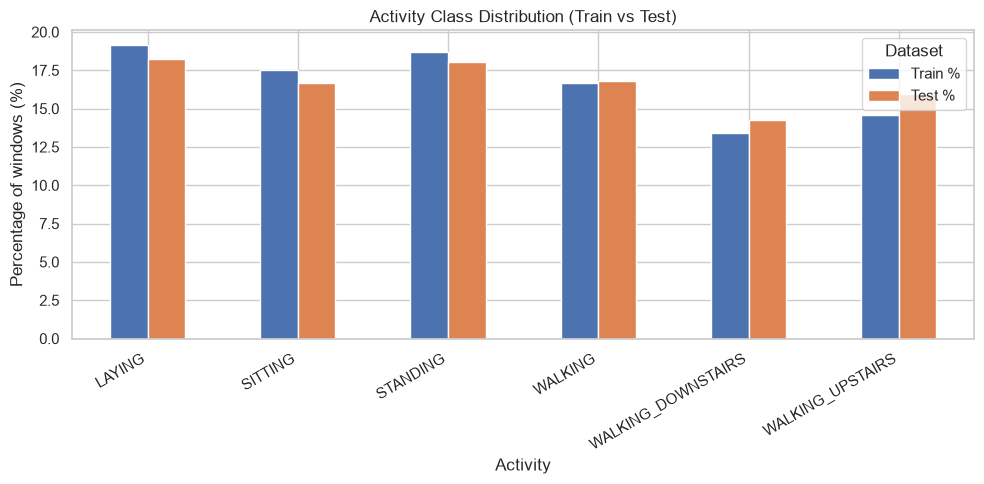

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
class_distribution[["Train %", "Test %"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("Activity Class Distribution (Train vs Test)")
ax.set_xlabel("Activity")
ax.set_ylabel("Percentage of windows (%)")
ax.legend(title="Dataset")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 2.7 Feature Distributions

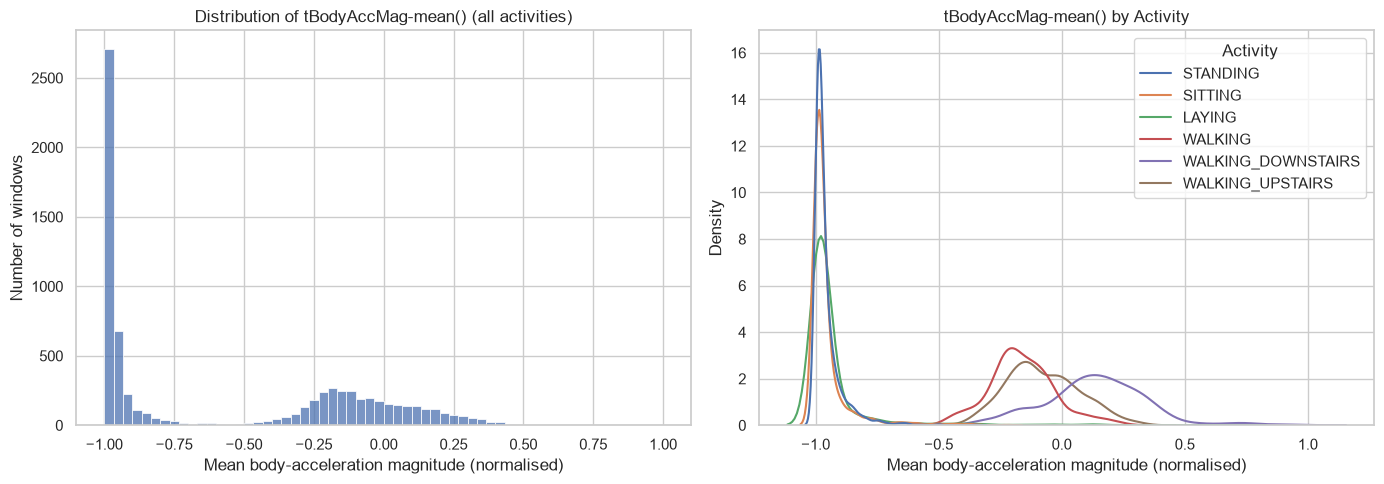

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train_df, x="tBodyAccMag-mean()", bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Distribution of tBodyAccMag-mean() (all activities)")
axes[0].set_xlabel("Mean body-acceleration magnitude (normalised)")
axes[0].set_ylabel("Number of windows")

sns.kdeplot(data=train_df, x="tBodyAccMag-mean()", hue=TARGET, common_norm=False, ax=axes[1])
axes[1].set_title("tBodyAccMag-mean() by Activity")
axes[1].set_xlabel("Mean body-acceleration magnitude (normalised)")
axes[1].set_ylabel("Density")
plt.tight_layout()
plt.show()

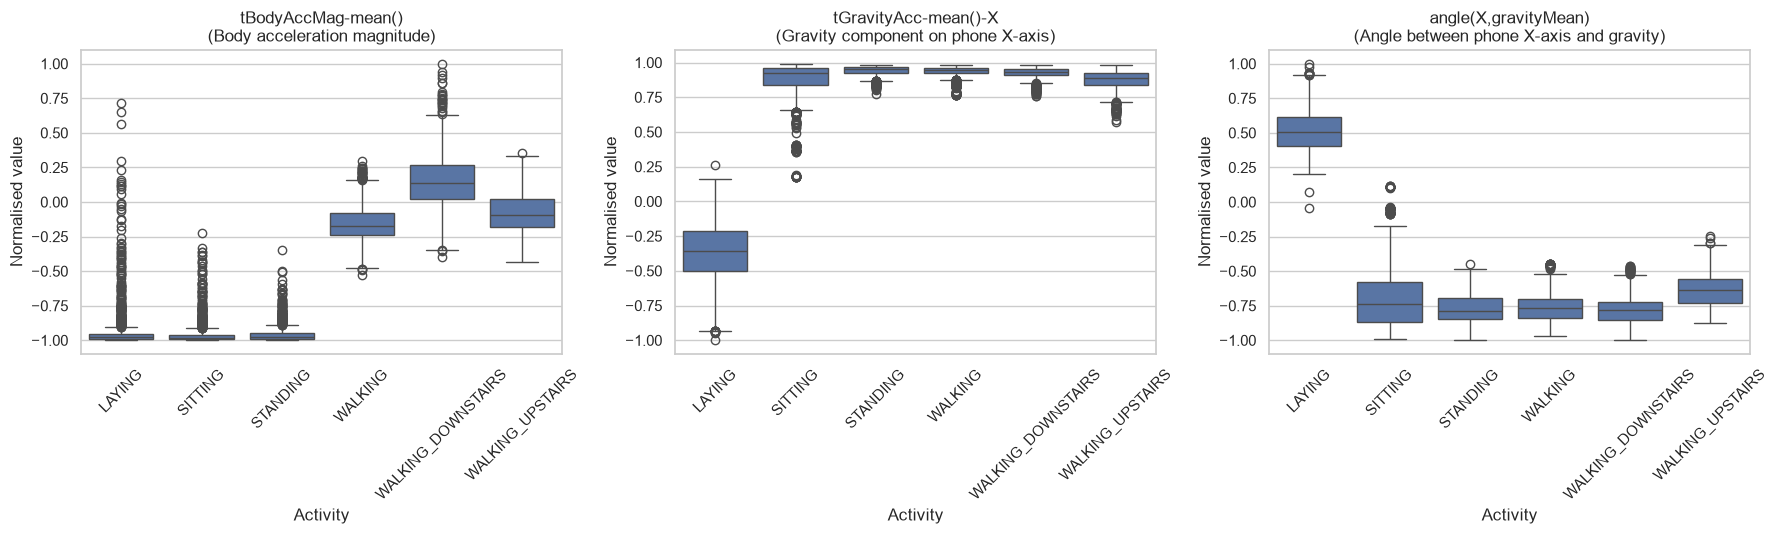

In [14]:
boxplot_features = {
    "tBodyAccMag-mean()": "Body acceleration magnitude",
    "tGravityAcc-mean()-X": "Gravity component on phone X-axis",
    "angle(X,gravityMean)": "Angle between phone X-axis and gravity",
}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (feature, description) in zip(axes, boxplot_features.items()):
    sns.boxplot(data=train_df, x=TARGET, y=feature, order=activity_classes, ax=ax)
    ax.set_title(f"{feature}\n({description})")
    ax.set_xlabel("Activity")
    ax.set_ylabel("Normalised value")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [15]:
train_df.groupby(TARGET)[list(boxplot_features)].median().round(3)

,tBodyAccMag-mean(),tGravityAcc-mean()-X,"angle(X,gravityMean)"
Activity,,,
LAYING,-0.978,-0.358,0.509
SITTING,-0.985,0.926,-0.739
STANDING,-0.979,0.953,-0.791
WALKING,-0.173,0.943,-0.765
WALKING_DOWNSTAIRS,0.139,0.932,-0.784
WALKING_UPSTAIRS,-0.094,0.891,-0.633


### 2.8 Correlation Analysis

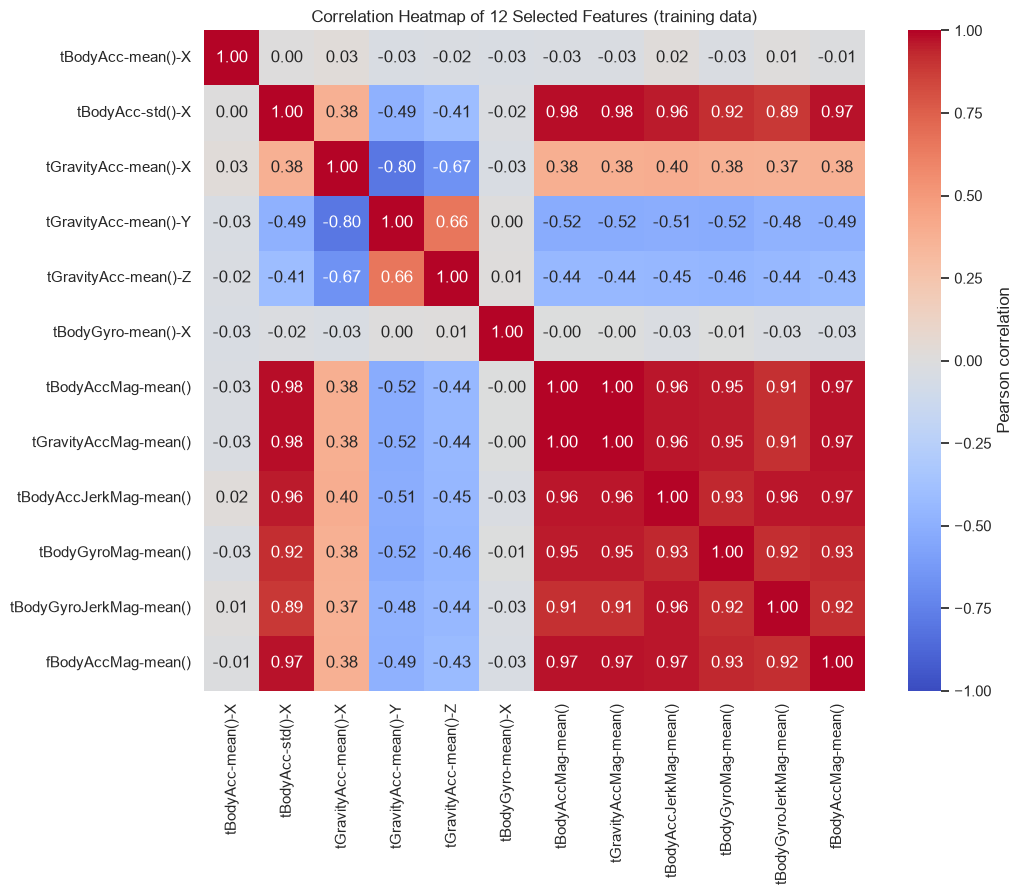

In [16]:
correlation_features = [
    "tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y",
    "tGravityAcc-mean()-Z", "tBodyGyro-mean()-X", "tBodyAccMag-mean()", "tGravityAccMag-mean()",
    "tBodyAccJerkMag-mean()", "tBodyGyroMag-mean()", "tBodyGyroJerkMag-mean()", "fBodyAccMag-mean()",
]
correlation_matrix = train_df[correlation_features].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of 12 Selected Features (training data)")
plt.tight_layout()
plt.show()

In [17]:
full_corr = train_df[feature_columns].corr().abs()
upper_triangle = full_corr.where(np.triu(np.ones(full_corr.shape, dtype=bool), k=1))
n_pairs = upper_triangle.notna().sum().sum()
n_high = (upper_triangle > 0.9).sum().sum()
print(f"Feature pairs with |correlation| > 0.9: {n_high} of {n_pairs} ({n_high / n_pairs:.2%})")

Feature pairs with |correlation| > 0.9: 8206 of 157080 (5.22%)


### 2.9 EDA Insights

### 2.10 Unit 1 Statistical Analysis (Review 1)

Treating the data probabilistically (Unit 1): the activity label is a **discrete random variable** $A$, each
sensor feature is a **continuous random variable** $X$. We use train + test together here because this is
descriptive statistics only (no model is fitted).

$$P(A=a)=\frac{n_a}{N},\quad E[X]=\frac1N\sum x_i,\quad \mathrm{Var}(X)=E[(X-E[X])^2],\quad
\mathrm{Cov}(X,Y)=E[(X-\mu_X)(Y-\mu_Y)],\quad P(A\mid E)=\frac{P(E\mid A)P(A)}{P(E)}$$

In [18]:
all_df = pd.concat([train_df, test_df], ignore_index=True)
N = len(all_df)

# --- discrete random variable: activity ---
p_act = all_df[TARGET].value_counts(normalize=True).sort_index()
entropy = -(p_act * np.log2(p_act)).sum()
print("P(A = a):"); print(p_act.round(4).to_string())
print(f"Sum of probabilities = {p_act.sum():.4f} | entropy = {entropy:.3f} bits (max for 6 classes = {np.log2(6):.3f})")

# --- continuous random variables: mean, variance, quantiles, IQR ---
rep = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "fBodyAcc-mean()-X"]
q = all_df[rep].quantile([0.25, 0.5, 0.75]).T
q.columns = ["Q1", "median", "Q3"]
q["IQR"] = q["Q3"] - q["Q1"]
stats = pd.DataFrame({"E[X] (mean)": all_df[rep].mean(), "Var(X)": all_df[rep].var(), "Std": all_df[rep].std()}).join(q)
stats

P(A = a):
Activity
LAYING                0.1888
SITTING               0.1725
STANDING              0.1851
WALKING               0.1672
WALKING_DOWNSTAIRS    0.1365
WALKING_UPSTAIRS      0.1499
Sum of probabilities = 1.0000 | entropy = 2.576 bits (max for 6 classes = 2.585)


,E[X] (mean),Var(X),Std,Q1,median,Q3,IQR
tBodyAcc-mean()-X,0.2743,0.0046,0.0676,0.2626,0.2772,0.2884,0.0257
tBodyAcc-std()-X,-0.6078,0.1925,0.4387,-0.9924,-0.9430,-0.2503,0.7421
fBodyAcc-mean()-X,-0.6228,0.1771,0.4208,-0.9913,-0.9456,-0.2646,0.7267


E[X | activity]:


,tBodyAcc-mean()-X,tBodyAcc-std()-X,fBodyAcc-mean()-X
Activity,,,
LAYING,0.269,-0.961,-0.967
SITTING,0.273,-0.983,-0.983
STANDING,0.279,-0.984,-0.982
WALKING,0.276,-0.315,-0.298
WALKING_DOWNSTAIRS,0.288,0.101,0.035
WALKING_UPSTAIRS,0.262,-0.238,-0.293


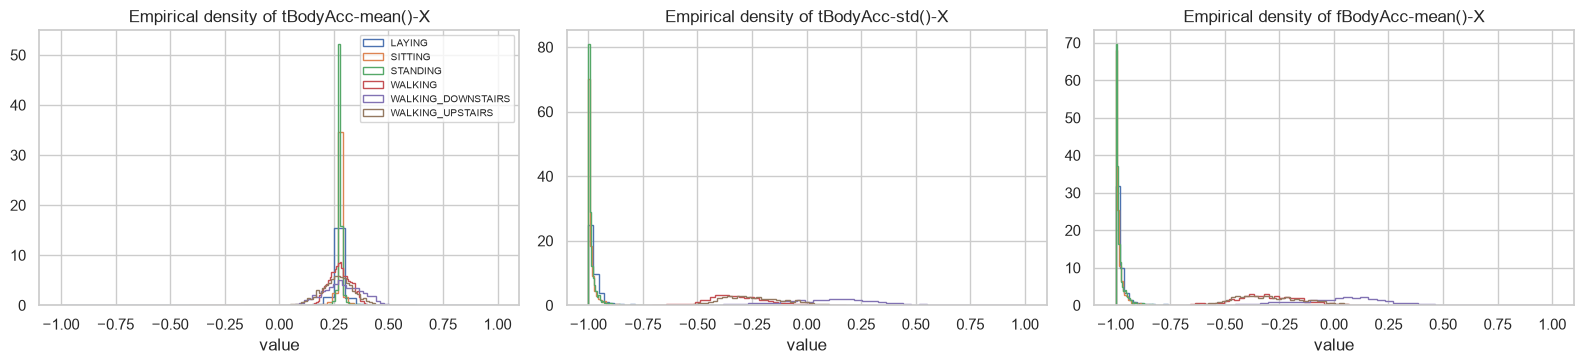

In [19]:
# --- conditional expectation E[X | A] and densities per activity ---
print("E[X | activity]:")
display(all_df.groupby(TARGET)[rep].mean().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, f in zip(axes, rep):
    for a in sorted(all_df[TARGET].unique()):
        ax.hist(all_df.loc[all_df[TARGET] == a, f], bins=40, density=True, histtype="step", label=a)
    ax.set_title(f"Empirical density of {f}"); ax.set_xlabel("value")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

Strongest positive correlation: ('tBodyAcc-std()-X', 'tBodyAccMag-mean()') 0.98
Strongest negative correlation: ('tGravityAcc-mean()-X', 'angle(X,gravityMean)') -0.989


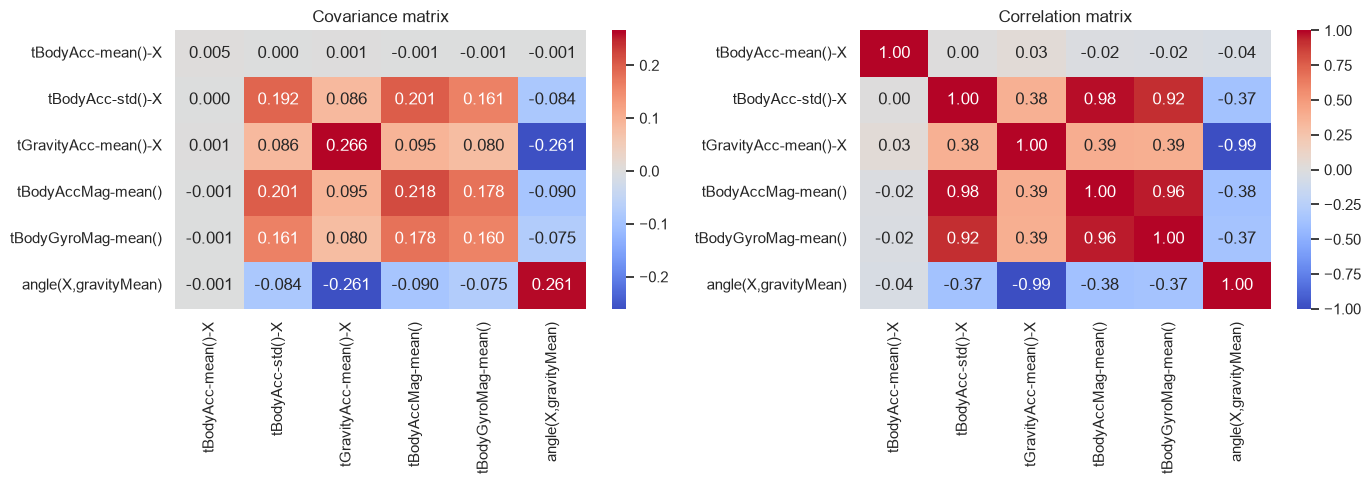

In [20]:
# --- covariance / correlation between selected random variables ---
cov_feats = ["tBodyAcc-mean()-X", "tBodyAcc-std()-X", "tGravityAcc-mean()-X",
             "tBodyAccMag-mean()", "tBodyGyroMag-mean()", "angle(X,gravityMean)"]
cov = all_df[cov_feats].cov()
corr = all_df[cov_feats].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Strongest positive correlation:", upper.idxmax(), round(upper.max(), 3))
print("Strongest negative correlation:", upper.idxmin(), round(upper.min(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cov, annot=True, fmt=".3f", cmap="coolwarm", center=0, ax=axes[0]); axes[0].set_title("Covariance matrix")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1]); axes[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

In [21]:
# --- conditional probability, Bayes rule, independence check ---
# Event E = "high body-acceleration variability" (tBodyAcc-std()-X > -0.5), a proxy for movement.
E = all_df["tBodyAcc-std()-X"] > -0.5
p_E = E.mean()
rows = []
for a in p_act.index:
    is_a = all_df[TARGET] == a
    p_E_given_A = E[is_a].mean()                       # P(E | A)
    p_A_given_E = p_E_given_A * p_act[a] / p_E         # Bayes rule
    direct = is_a[E].mean()                            # P(A | E) counted directly
    joint = (is_a & E).mean()
    rows.append([a, p_act[a], p_E_given_A, p_A_given_E, direct, joint, p_act[a] * p_E])
bayes = pd.DataFrame(rows, columns=["activity", "P(A)", "P(E|A)", "P(A|E) Bayes", "P(A|E) direct", "P(A,E)", "P(A)P(E)"]).set_index("activity")
print(f"P(E) = {p_E:.4f}")
display(bayes.round(4))
print("Bayes rule matches direct counting:", np.allclose(bayes["P(A|E) Bayes"], bayes["P(A|E) direct"]))
print("A and E independent?  P(A,E) != P(A)P(E) for every activity ->", not np.allclose(bayes["P(A,E)"], bayes["P(A)P(E)"], atol=0.01),
      "(E is strongly dependent on activity: dynamic vs static)")

P(E) = 0.4409


,P(A),P(E|A),P(A|E) Bayes,P(A|E) direct,"P(A,E)",P(A)P(E)
activity,,,,,,
LAYING,0.1888,0.0072,0.0031,0.0031,0.0014,0.0832
SITTING,0.1725,0.0000,0.0000,0.0000,0.0000,0.0761
STANDING,0.1851,0.0000,0.0000,0.0000,0.0000,0.0816
WALKING,0.1672,0.9274,0.3517,0.3517,0.1551,0.0737
WALKING_DOWNSTAIRS,0.1365,1.0000,0.3096,0.3096,0.1365,0.0602
WALKING_UPSTAIRS,0.1499,0.9870,0.3356,0.3356,0.1480,0.0661


Bayes rule matches direct counting: True
A and E independent?  P(A,E) != P(A)P(E) for every activity -> True (E is strongly dependent on activity: dynamic vs static)


             feature  n_outliers  share
   tBodyAcc-mean()-X        2437 0.2366
    tBodyAcc-std()-X           3 0.0003
   fBodyAcc-mean()-X           2 0.0002
tGravityAcc-mean()-X        2017 0.1958
  tBodyAccMag-mean()           0 0.0000


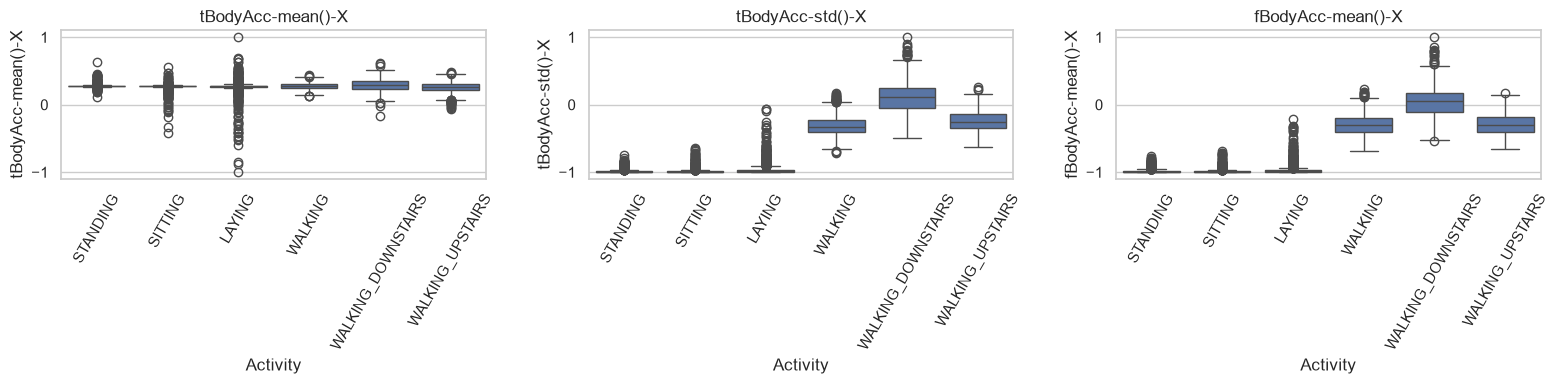

In [22]:
# --- outlier check with the 1.5 x IQR rule ---
out = []
for f in rep + ["tGravityAcc-mean()-X", "tBodyAccMag-mean()"]:
    s = all_df[f]; q1, q3 = s.quantile([.25, .75]); lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    out.append([f, int(((s < lo) | (s > hi)).sum()), ((s < lo) | (s > hi)).mean()])
print(pd.DataFrame(out, columns=["feature", "n_outliers", "share"]).round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, f in zip(axes, rep):
    sns.boxplot(data=all_df, x=TARGET, y=f, ax=ax); ax.tick_params(axis="x", rotation=60); ax.set_title(f)
plt.tight_layout(); plt.show()

**Review 1 takeaways.** The 6 classes are nearly balanced (entropy close to the maximum, so accuracy is a fair metric).
Activity strongly shifts the mean and spread of the motion features (E[X | A] differs sharply between dynamic and static
activities), the motion/magnitude features are highly correlated (redundancy, which motivates PCA in Review 2), and
$P(\text{movement}\mid A)$ separates dynamic from static activities almost perfectly. Some features are heavy-tailed (e.g. 24 % of
`tBodyAcc-mean()-X` values fall outside the 1.5 x IQR fences), but these are genuine sensor readings, not errors, so they are kept.

## 3. Data Preparation

### 3.1 Feature and Target Separation

In [23]:
X_train = train_df[feature_columns]
y_train = train_df[TARGET]

X_test = test_df[feature_columns]
y_test = test_df[TARGET]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test: ", X_test.shape, "| y_test: ", y_test.shape)
print("'subject' in features:", "subject" in feature_columns)

X_train: (7352, 561) | y_train: (7352,)
X_test:  (2947, 561) | y_test:  (2947,)
'subject' in features: False


### 3.2 Preprocessing

### 3.3 Train/Test Data

In [24]:
print(f"Training set: {len(X_train)} windows from {train_df['subject'].nunique()} subjects -> used for fitting")
print(f"Test set:     {len(X_test)} windows from {test_df['subject'].nunique()} subjects -> used ONLY for evaluation")

Training set: 7352 windows from 21 subjects -> used for fitting
Test set:     2947 windows from 9 subjects -> used ONLY for evaluation


## 4. Classification Models

In [25]:
results = {}
predictions = {}
trained_models = {}

def train_and_evaluate(model_name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    predictions[model_name] = y_pred
    trained_models[model_name] = model
    results[model_name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted"),
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
    }

    print(f"===== {model_name} =====")
    for metric, value in results[model_name].items():
        print(f"{metric:<20}: {value:.4f}")
    print()
    print(classification_report(y_test, y_pred, digits=4))

### 4.1 Logistic Regression

In [26]:
log_reg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
train_and_evaluate("Logistic Regression", log_reg_model)

===== Logistic Regression =====
Accuracy            : 0.9535
Precision (macro)   : 0.9563
Recall (macro)      : 0.9520
F1-score (macro)    : 0.9532
F1-score (weighted) : 0.9534
Train Accuracy      : 0.9963

                    precision    recall  f1-score   support

            LAYING     0.9981    0.9926    0.9953       537
           SITTING     0.9663    0.8758    0.9188       491
          STANDING     0.8898    0.9718    0.9290       532
           WALKING     0.9408    0.9940    0.9667       496
WALKING_DOWNSTAIRS     0.9899    0.9333    0.9608       420
  WALKING_UPSTAIRS     0.9529    0.9448    0.9488       471

          accuracy                         0.9535      2947
         macro avg     0.9563    0.9520    0.9532      2947
      weighted avg     0.9552    0.9535    0.9534      2947



### 4.2 Support Vector Machine

In [27]:
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
])
train_and_evaluate("Support Vector Machine", svm_model)

===== Support Vector Machine =====
Accuracy            : 0.9518
Precision (macro)   : 0.9525
Recall (macro)      : 0.9504
F1-score (macro)    : 0.9511
F1-score (weighted) : 0.9517
Train Accuracy      : 0.9867

                    precision    recall  f1-score   support

            LAYING     0.9944    1.0000    0.9972       537
           SITTING     0.9383    0.8982    0.9178       491
          STANDING     0.9162    0.9455    0.9306       532
           WALKING     0.9602    0.9718    0.9659       496
WALKING_DOWNSTAIRS     0.9772    0.9190    0.9472       420
  WALKING_UPSTAIRS     0.9287    0.9682    0.9480       471

          accuracy                         0.9518      2947
         macro avg     0.9525    0.9504    0.9511      2947
      weighted avg     0.9522    0.9518    0.9517      2947



### 4.3 Random Forest

In [28]:
random_forest_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
train_and_evaluate("Random Forest", random_forest_model)

===== Random Forest =====
Accuracy            : 0.9291
Precision (macro)   : 0.9303
Recall (macro)      : 0.9263
F1-score (macro)    : 0.9275
F1-score (weighted) : 0.9289
Train Accuracy      : 1.0000

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.9156    0.8839    0.8995       491
          STANDING     0.8962    0.9248    0.9103       532
           WALKING     0.9043    0.9718    0.9368       496
WALKING_DOWNSTAIRS     0.9680    0.8643    0.9132       420
  WALKING_UPSTAIRS     0.8977    0.9130    0.9053       471

          accuracy                         0.9291      2947
         macro avg     0.9303    0.9263    0.9275      2947
      weighted avg     0.9302    0.9291    0.9289      2947



## 5. Comparative Performance Analysis

### 5.1 Evaluation Metrics

### 5.2 Model Comparison

In [29]:
comparison_table = pd.DataFrame(results).T
comparison_table.index.name = "Model"
main_metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
comparison_table[main_metrics].round(4)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9535,0.9563,0.9520,0.9532
Support Vector Machine,0.9518,0.9525,0.9504,0.9511
Random Forest,0.9291,0.9303,0.9263,0.9275


In [30]:
print("Highest value for each metric:")
for metric in main_metrics:
    print(f"  {metric:<18}: {comparison_table[metric].idxmax():<24} ({comparison_table[metric].max():.4f})")

print("\nWeighted F1 (reference) and overfitting check (train accuracy - test accuracy):")
overfit_check = comparison_table[["F1-score (weighted)", "Train Accuracy", "Accuracy"]].copy()
overfit_check["Train-Test gap"] = overfit_check["Train Accuracy"] - overfit_check["Accuracy"]
overfit_check.round(4)

Highest value for each metric:
  Accuracy          : Logistic Regression      (0.9535)
  Precision (macro) : Logistic Regression      (0.9563)
  Recall (macro)    : Logistic Regression      (0.9520)
  F1-score (macro)  : Logistic Regression      (0.9532)

Weighted F1 (reference) and overfitting check (train accuracy - test accuracy):


,F1-score (weighted),Train Accuracy,Accuracy,Train-Test gap
Model,,,,
Logistic Regression,0.9534,0.9963,0.9535,0.0428
Support Vector Machine,0.9517,0.9867,0.9518,0.0349
Random Forest,0.9289,1.0000,0.9291,0.0709


### 5.3 Confusion Matrices

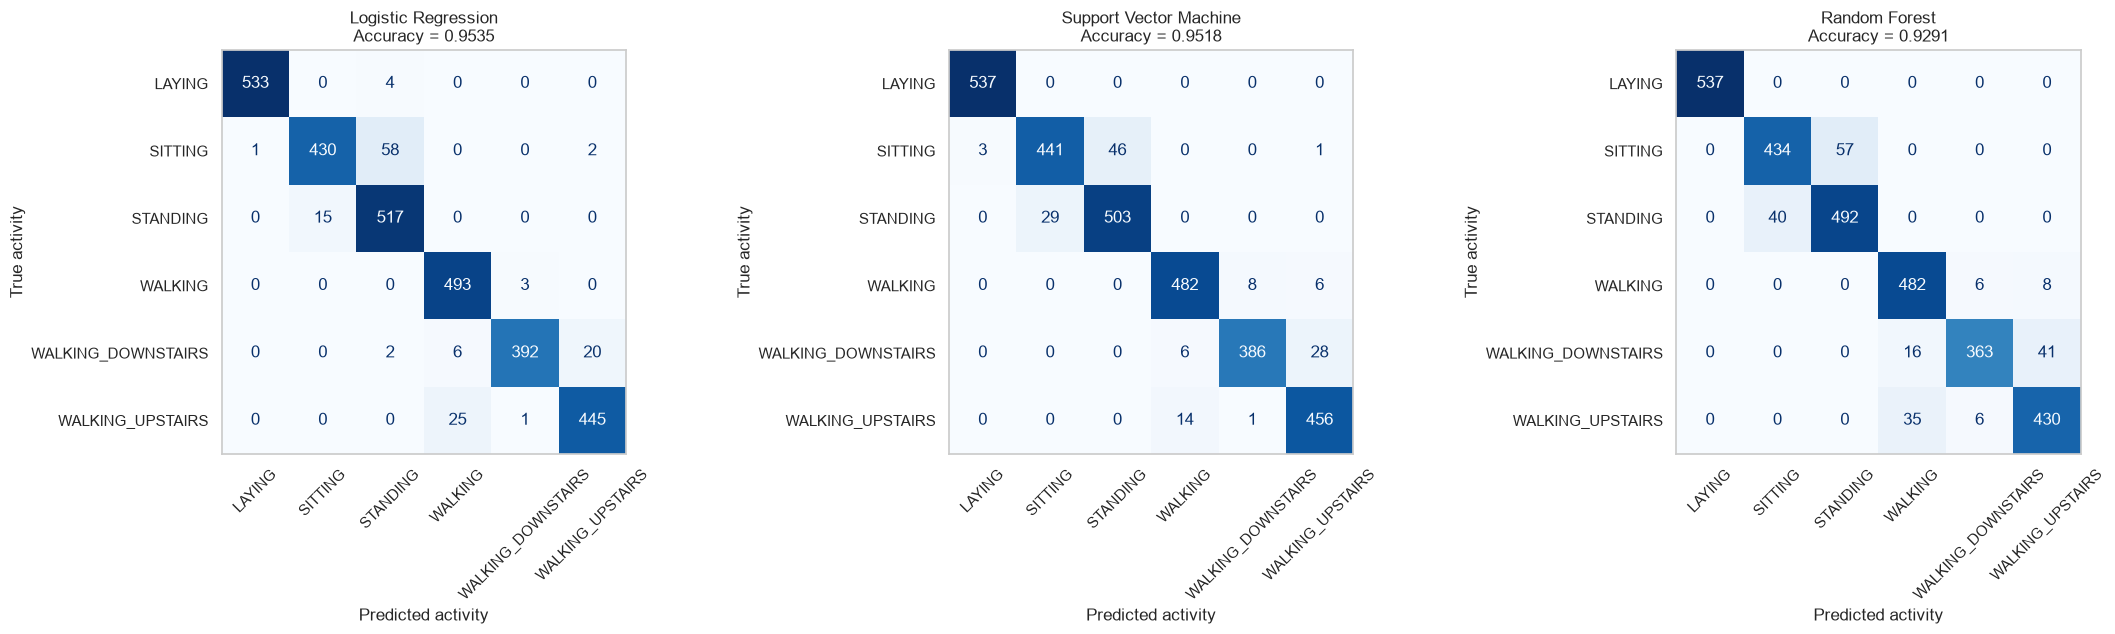

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6.5))
confusion_matrices = {}
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=activity_classes)
    confusion_matrices[model_name] = cm
    ConfusionMatrixDisplay(cm, display_labels=activity_classes).plot(
        ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
    ax.set_title(f"{model_name}\nAccuracy = {results[model_name]['Accuracy']:.4f}")
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("True activity")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [32]:
per_class_recall = pd.DataFrame(
    {name: cm.diagonal() / cm.sum(axis=1) for name, cm in confusion_matrices.items()},
    index=activity_classes,
)
per_class_recall["Mean over models"] = per_class_recall.mean(axis=1)
per_class_recall.sort_values("Mean over models").round(4)

,Logistic Regression,Support Vector Machine,Random Forest,Mean over models
SITTING,0.8758,0.8982,0.8839,0.8859
WALKING_DOWNSTAIRS,0.9333,0.9190,0.8643,0.9056
WALKING_UPSTAIRS,0.9448,0.9682,0.9130,0.9420
STANDING,0.9718,0.9455,0.9248,0.9474
WALKING,0.9940,0.9718,0.9718,0.9792
LAYING,0.9926,1.0000,1.0000,0.9975


In [33]:
for model_name, cm in confusion_matrices.items():
    errors = pd.DataFrame(cm, index=activity_classes, columns=activity_classes)
    errors = errors.stack().rename("count").reset_index()
    errors.columns = ["True activity", "Predicted as", "count"]
    errors = errors[errors["True activity"] != errors["Predicted as"]]
    top_errors = errors.sort_values("count", ascending=False).head(4)
    print(f"--- {model_name}: total errors = {errors['count'].sum()} of {cm.sum()} ---")
    print(top_errors.to_string(index=False))
    print()

--- Logistic Regression: total errors = 137 of 2947 ---
     True activity     Predicted as  count
           SITTING         STANDING     58
  WALKING_UPSTAIRS          WALKING     25
WALKING_DOWNSTAIRS WALKING_UPSTAIRS     20
          STANDING          SITTING     15

--- Support Vector Machine: total errors = 142 of 2947 ---
     True activity     Predicted as  count
           SITTING         STANDING     46
          STANDING          SITTING     29
WALKING_DOWNSTAIRS WALKING_UPSTAIRS     28
  WALKING_UPSTAIRS          WALKING     14

--- Random Forest: total errors = 209 of 2947 ---
     True activity     Predicted as  count
           SITTING         STANDING     57
WALKING_DOWNSTAIRS WALKING_UPSTAIRS     41
          STANDING          SITTING     40
  WALKING_UPSTAIRS          WALKING     35



In [34]:
static_activities = ["LAYING", "SITTING", "STANDING"]
y_test_is_static = y_test.isin(static_activities).to_numpy()
for model_name, y_pred in predictions.items():
    cross_group_errors = (y_test_is_static != np.isin(y_pred, static_activities)).sum()
    print(f"{model_name:<24}: static <-> dynamic errors = {cross_group_errors}")

lr_svm_disagreements = (predictions["Logistic Regression"] != predictions["Support Vector Machine"]).sum()
print(f"\nTest windows where Logistic Regression and SVM predict different activities: {lr_svm_disagreements}")

Logistic Regression     : static <-> dynamic errors = 4
Support Vector Machine  : static <-> dynamic errors = 1
Random Forest           : static <-> dynamic errors = 0

Test windows where Logistic Regression and SVM predict different activities: 117


### 5.4 Performance Comparison

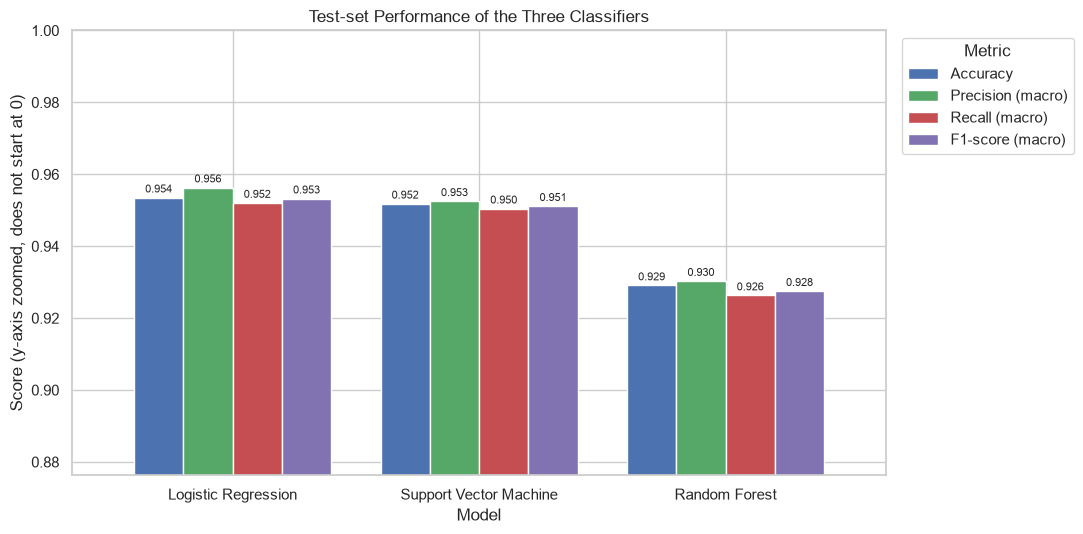

In [35]:
ax = comparison_table[main_metrics].plot(kind="bar", figsize=(11, 5.5), width=0.8,
                                          color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
lowest = comparison_table[main_metrics].min().min()
ax.set_ylim(max(0, lowest - 0.05), 1.0)
ax.set_title("Test-set Performance of the Three Classifiers")
ax.set_xlabel("Model")
ax.set_ylabel("Score (y-axis zoomed, does not start at 0)")
ax.legend(title="Metric", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

---
# REVIEW 2 – MATHEMATICAL MODELS FROM SCRATCH (Units 2 and 3)

Review 2 asks for the **mathematical model of the algorithm and a Python script written without ML libraries**.
Everything in this section is implemented with **NumPy only** (no `sklearn` model is used to fit anything).
`sklearn` appears only at the end (§R2.9) to **verify** each hand-written model against the library version.

| § | Unit | Algorithm | Task here |
|---|---|---|---|
| R2.2 | 3 | PCA (eigen-decomposition) | compress 561 features |
| R2.3 | 2 | Linear / ridge regression (MLE, MAP) | predict `tBodyAccMag-mean()` |
| R2.4 | 2 | Bayesian logistic regression (Laplace approximation) | dynamic vs static |
| R2.5 | 2 | Linear SVM (hinge loss, subgradient descent) | dynamic vs static |
| R2.6 | 3 | K-means (k-means++) | cluster activities, no labels |
| R2.7 | 3 | Gaussian mixture via EM | cluster activities, no labels |
| R2.8 | 3 | Hierarchical clustering (Ward, Lance-Williams) | cluster activities, no labels |

Rules: standardisation and PCA are fitted on the **training subjects only**; the 9 test subjects are used for final evaluation only.

### R2.1 Setup: shared standardisation

In [36]:
# ---- shared setup: standardise with TRAIN statistics only ----
Xtr_raw = train_df[feature_columns].to_numpy(float)
Xte_raw = test_df[feature_columns].to_numpy(float)
mu_tr, sd_tr = Xtr_raw.mean(0), Xtr_raw.std(0) + 1e-8
Ztr, Zte = (Xtr_raw - mu_tr) / sd_tr, (Xte_raw - mu_tr) / sd_tr

classes = sorted(train_df[TARGET].unique())
ytr = train_df[TARGET].map({c: i for i, c in enumerate(classes)}).to_numpy()
yte = test_df[TARGET].map({c: i for i, c in enumerate(classes)}).to_numpy()
dynamic = {i for i, c in enumerate(classes) if c.startswith("WALKING")}
ytr_bin = np.isin(ytr, list(dynamic)).astype(float)       # 1 = dynamic, 0 = static
yte_bin = np.isin(yte, list(dynamic)).astype(float)
rng = np.random.default_rng(42)
r2_results = {}
print("Train", Ztr.shape, "| Test", Zte.shape, "| classes:", classes)

Train (7352, 561) | Test (2947, 561) | classes: ['LAYING', 'SITTING', 'STANDING', 'WALKING', 'WALKING_DOWNSTAIRS', 'WALKING_UPSTAIRS']


### R2.2 PCA from scratch (Unit 3)

Given standardised data $Z$, the covariance is $S=\frac1{N-1}Z^\top Z$. PCA solves $S v_j=\lambda_j v_j$; the principal
components are the eigenvectors with the largest eigenvalues, and component $j$ explains $\lambda_j/\sum_i\lambda_i$
of the variance. Scores are $Z V_k$. We keep the smallest $k$ that explains 95 % of the variance.

Components for 95% variance: 102 (of 561) | first 2 PCs explain 57.4%


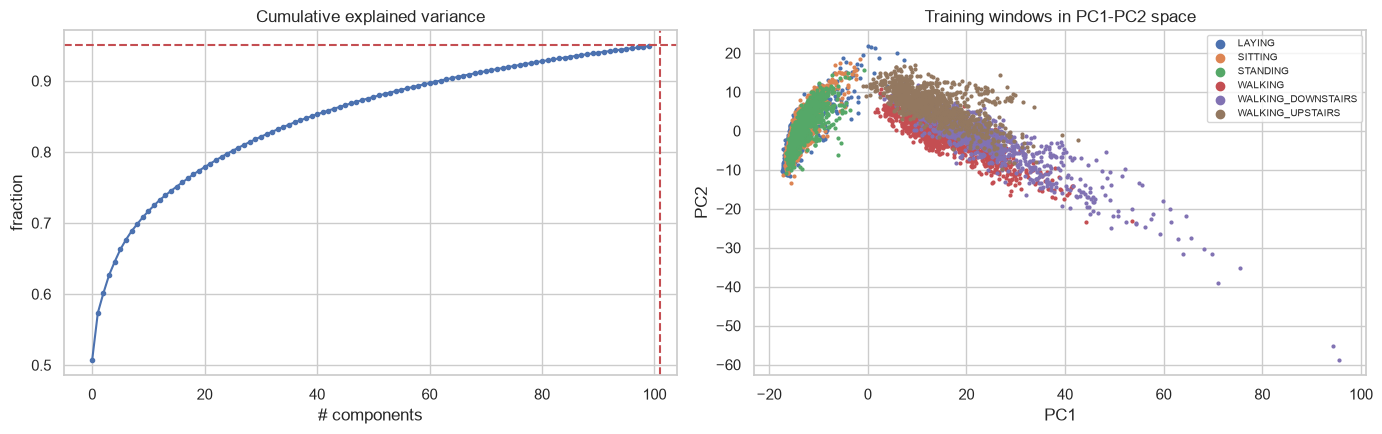

In [37]:
def pca_fit(Z):
    S = np.cov(Z, rowvar=False)                 # covariance matrix (561 x 561)
    vals, vecs = np.linalg.eigh(S)              # symmetric eigen-decomposition
    order = np.argsort(vals)[::-1]
    return vals[order], vecs[:, order]

eig_vals, eig_vecs = pca_fit(Ztr)
ratio = eig_vals / eig_vals.sum()
k95 = int(np.searchsorted(np.cumsum(ratio), 0.95) + 1)
print(f"Components for 95% variance: {k95} (of 561) | first 2 PCs explain {ratio[:2].sum():.1%}")

Ptr, Pte = Ztr @ eig_vecs[:, :k95], Zte @ eig_vecs[:, :k95]    # PCA scores
r2_results["PCA components (95%)"] = k95

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(np.cumsum(ratio[:100]), marker=".")
axes[0].axhline(0.95, color="r", ls="--"); axes[0].axvline(k95 - 1, color="r", ls="--")
axes[0].set(title="Cumulative explained variance", xlabel="# components", ylabel="fraction")
for i, c in enumerate(classes):
    axes[1].scatter(Ptr[ytr == i, 0], Ptr[ytr == i, 1], s=4, label=c)
axes[1].set(title="Training windows in PC1-PC2 space", xlabel="PC1", ylabel="PC2"); axes[1].legend(markerscale=3, fontsize=7)
plt.tight_layout(); plt.show()

### R2.3 Linear and ridge regression from scratch (Unit 2)

Model $y=w^\top\phi(x)+\varepsilon,\ \varepsilon\sim\mathcal N(0,\sigma^2)$. Maximum likelihood = least squares:
$\hat w=(\Phi^\top\Phi)^{-1}\Phi^\top y$. A Gaussian prior $w\sim\mathcal N(0,\alpha^{-1}I)$ gives the MAP / **ridge**
estimate $\hat w=(\Phi^\top\Phi+\lambda I)^{-1}\Phi^\top y$ with $\lambda=\sigma^2\alpha$. Task: predict the continuous feature
`tBodyAccMag-mean()` from five other sensor features. $\lambda$ is chosen on a subject-held-out validation split of the training set.

Validation RMSE by lambda: {0: 0.1137, 0.1: 0.1137, 1: 0.1137, 10: 0.1135, 100: 0.113, 1000: 0.1189} -> best lambda = 100
OLS (MLE)          test RMSE = 0.0561 | R^2 = 0.9837
Ridge (lambda=100) test RMSE = 0.0568 | R^2 = 0.9833


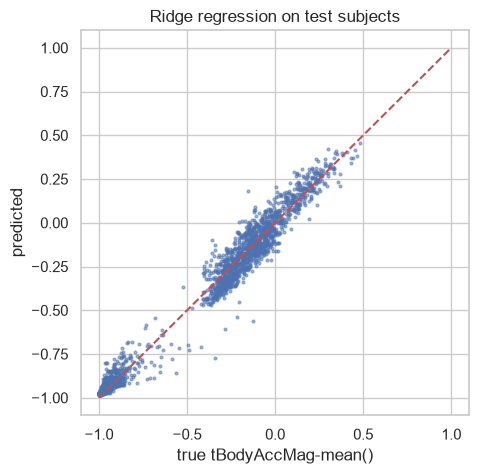

In [38]:
reg_target = "tBodyAccMag-mean()"
reg_inputs = ["tBodyAcc-std()-X", "tGravityAcc-mean()-X", "tBodyGyroMag-mean()", "angle(X,gravityMean)", "tBodyAcc-mean()-X"]
Xr_tr, yr_tr = train_df[reg_inputs].to_numpy(float), train_df[reg_target].to_numpy(float)
Xr_te, yr_te = test_df[reg_inputs].to_numpy(float), test_df[reg_target].to_numpy(float)
m_r, s_r = Xr_tr.mean(0), Xr_tr.std(0)
Xr_tr, Xr_te = (Xr_tr - m_r) / s_r, (Xr_te - m_r) / s_r
add_bias = lambda X: np.c_[np.ones(len(X)), X]

def ridge_fit(X, y, lam):
    Phi = add_bias(X); reg = lam * np.eye(Phi.shape[1]); reg[0, 0] = 0      # bias is not penalised
    return np.linalg.solve(Phi.T @ Phi + reg, Phi.T @ y)

rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
r2score = lambda y, p: 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

# subject-held-out validation split inside the TRAIN set
subj = train_df["subject"].to_numpy(); val_subj = np.unique(subj)[::5]
val = np.isin(subj, val_subj)
lams = [0, 0.1, 1, 10, 100, 1000]
val_rmse = {l: rmse(yr_tr[val], add_bias(Xr_tr[val]) @ ridge_fit(Xr_tr[~val], yr_tr[~val], l)) for l in lams}
best_lam = min(val_rmse, key=val_rmse.get)
print("Validation RMSE by lambda:", {k: round(v, 4) for k, v in val_rmse.items()}, "-> best lambda =", best_lam)

w_ols, w_ridge = ridge_fit(Xr_tr, yr_tr, 0), ridge_fit(Xr_tr, yr_tr, best_lam)
for name, w in [("OLS (MLE)", w_ols), (f"Ridge (lambda={best_lam})", w_ridge)]:
    p = add_bias(Xr_te) @ w
    print(f"{name:18s} test RMSE = {rmse(yr_te, p):.4f} | R^2 = {r2score(yr_te, p):.4f}")
r2_results["Ridge regression test R^2"] = round(r2score(yr_te, add_bias(Xr_te) @ w_ridge), 4)

plt.figure(figsize=(5, 5)); p = add_bias(Xr_te) @ w_ridge
plt.scatter(yr_te, p, s=4, alpha=.5); plt.plot([-1, 1], [-1, 1], "r--")
plt.xlabel("true tBodyAccMag-mean()"); plt.ylabel("predicted"); plt.title("Ridge regression on test subjects"); plt.show()

### R2.4 Bayesian logistic regression with Laplace approximation (Unit 2)

Likelihood $p(t\mid w)=\prod_n\sigma(w^\top x_n)^{t_n}(1-\sigma(w^\top x_n))^{1-t_n}$ with prior $w\sim\mathcal N(0,\alpha^{-1}I)$.
The posterior has no closed form, so we find its mode $w_{MAP}$ with Newton-Raphson (IRLS):
$w\leftarrow w-H^{-1}\nabla E,\ \ \nabla E=\Phi^\top(y-t)+\alpha w,\ \ H=\Phi^\top R\Phi+\alpha I,\ \ R_{nn}=y_n(1-y_n)$,
and approximate the posterior by $\mathcal N(w_{MAP},H^{-1})$ (**Laplace approximation**, Bishop §4.4-4.5).
The predictive distribution uses the probit approximation
$p(t=1\mid x)\approx\sigma\!\big(\kappa(\sigma_a^2)\,\mu_a\big)$, $\kappa=(1+\pi\sigma_a^2/8)^{-1/2}$, with $\mu_a=w_{MAP}^\top x$, $\sigma_a^2=x^\top H^{-1}x$.
Task: dynamic vs static activity on the PCA scores (first 20 components).

In [39]:
sigmoid = lambda z: 1 / (1 + np.exp(-np.clip(z, -30, 30)))

def bayes_logreg(X, t, alpha, iters=30):
    Phi = add_bias(X); w = np.zeros(Phi.shape[1])
    for _ in range(iters):
        y = sigmoid(Phi @ w)
        grad = Phi.T @ (y - t) + alpha * w
        H = Phi.T @ (Phi * (y * (1 - y))[:, None]) + alpha * np.eye(len(w))
        step = np.linalg.solve(H, grad); w -= step
        if np.abs(step).max() < 1e-8: break
    return w, np.linalg.inv(H)                      # posterior mean and covariance

def blr_predict(X, w, S, bayes=True):
    Phi = add_bias(X); a = Phi @ w
    if not bayes: return sigmoid(a)                 # plug-in MAP prediction
    var = np.einsum("ij,jk,ik->i", Phi, S, Phi)
    return sigmoid(a / np.sqrt(1 + np.pi * var / 8))  # probit approximation of the predictive

K = 20
Ptr20, Pte20 = Ptr[:, :K], Pte[:, :K]
acc = lambda p, t: float(((p > .5) == t).mean())
val_acc = {}
for alpha in [0.01, 0.1, 1, 10, 100]:
    w, S = bayes_logreg(Ptr20[~val], ytr_bin[~val], alpha)
    val_acc[alpha] = acc(blr_predict(Ptr20[val], w, S), ytr_bin[val])
best_alpha = max(val_acc, key=val_acc.get)
print("Validation accuracy by prior precision alpha:", {k: round(v, 4) for k, v in val_acc.items()}, "-> alpha =", best_alpha)

w_blr, S_blr = bayes_logreg(Ptr20, ytr_bin, best_alpha)
p_bayes, p_map = blr_predict(Pte20, w_blr, S_blr), blr_predict(Pte20, w_blr, S_blr, bayes=False)
print(f"Test accuracy  MAP plug-in: {acc(p_map, yte_bin):.4f} | Bayesian predictive: {acc(p_bayes, yte_bin):.4f}")
print(f"Mean confidence |p-0.5|: MAP {np.abs(p_map-.5).mean():.3f} vs Bayesian {np.abs(p_bayes-.5).mean():.3f} (Bayesian is less over-confident)")
r2_results["Bayesian LR (dynamic vs static) acc"] = round(acc(p_bayes, yte_bin), 4)

Validation accuracy by prior precision alpha: {0.01: 0.9966, 0.1: 0.9966, 1: 0.9966, 10: 0.9978, 100: 0.9978} -> alpha = 10
Test accuracy  MAP plug-in: 0.9997 | Bayesian predictive: 0.9997
Mean confidence |p-0.5|: MAP 0.500 vs Bayesian 0.494 (Bayesian is less over-confident)


### R2.5 Linear SVM from scratch (Unit 2)

Soft-margin SVM in primal form: minimise $\frac{\lambda}{2}\lVert w\rVert^2+\frac1N\sum_n\max(0,1-t_n(w^\top x_n+b))$ with $t_n\in\{-1,+1\}$.
The hinge loss is non-differentiable at the margin, so we use the **subgradient**: for points with $t_n(w^\top x_n+b)<1$
the gradient contribution is $-t_nx_n$, otherwise 0. Full-batch subgradient descent with step $\eta_k=\eta_0/\sqrt{k}$.
The RBF kernel SVM (kernel trick) from Module 1 is the library comparison for the non-linear case.

In [40]:
def svm_fit(X, t, lam=1e-3, iters=600, lr=0.5):
    t = 2 * t - 1; w = np.zeros(X.shape[1]); b = 0.0
    for k in range(1, iters + 1):
        viol = t * (X @ w + b) < 1                  # margin violators
        gw = lam * w - (t[viol, None] * X[viol]).sum(0) / len(X)
        gb = -t[viol].sum() / len(X)
        eta = lr / np.sqrt(k); w -= eta * gw; b -= eta * gb
    return w, b

svm_pred = lambda X, w, b: (X @ w + b > 0).astype(float)
for lam in [1e-4, 1e-3, 1e-2, 1e-1]:
    w, b = svm_fit(Ptr20[~val], ytr_bin[~val], lam)
    print(f"lambda={lam:<7} validation acc = {(svm_pred(Ptr20[val], w, b) == ytr_bin[val]).mean():.4f}")
w_svm, b_svm = svm_fit(Ptr20, ytr_bin, 1e-3)
svm_acc = (svm_pred(Pte20, w_svm, b_svm) == yte_bin).mean()
margin = 2 / np.linalg.norm(w_svm)
print(f"Linear SVM test accuracy = {svm_acc:.4f} | margin width 2/||w|| = {margin:.3f}")
r2_results["Linear SVM (dynamic vs static) acc"] = round(float(svm_acc), 4)

lambda=0.0001  validation acc = 0.9950
lambda=0.001   validation acc = 0.9950
lambda=0.01    validation acc = 0.9950
lambda=0.1     validation acc = 0.9955
Linear SVM test accuracy = 0.9997 | margin width 2/||w|| = 0.269


### R2.6 K-means from scratch (Unit 3)

Minimise the distortion $J=\sum_n\sum_k r_{nk}\lVert x_n-\mu_k\rVert^2$ by alternating the **E-like step** (assign each point to the
nearest centre, $r_{nk}=1$ for $k=\arg\min_j\lVert x_n-\mu_j\rVert^2$) and the **M-like step** ($\mu_k$ = mean of its points).
$J$ never increases, so it converges to a local minimum; we use **k-means++** seeding and keep the best of 10 restarts.
Clustering uses the first 10 PCA scores and **no labels**; labels are used only afterwards to judge cluster quality
(purity and adjusted Rand index).

K-means (k=6): inertia=622639 | purity=0.562 | ARI=0.427


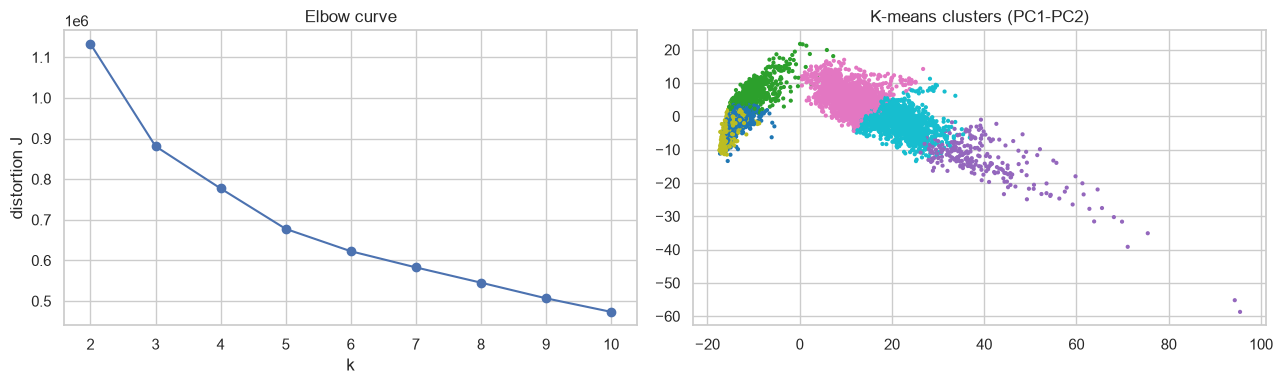

true activity  LAYING  SITTING  STANDING  WALKING  WALKING_DOWNSTAIRS  \
cluster                                                                 
0                  28      898      1076        0                   0   
1                 264      281       298        0                   0   
2                   0        0         0       68                 168   
3                   3        1         0      632                 204   
4                1112      106         0        0                   0   
5                   0        0         0      526                 614   

true activity  WALKING_UPSTAIRS  
cluster                          
0                             0  
1                             3  
2                             5  
3                           862  
4                             0  
5                           203  


In [41]:
def purity(clusters, y):
    return sum(np.bincount(y[clusters == c]).max() for c in np.unique(clusters)) / len(y)

def ari(a, b):                                       # adjusted Rand index
    ct = np.zeros((a.max() + 1, b.max() + 1))
    np.add.at(ct, (a, b), 1)
    c2 = lambda x: (x * (x - 1) / 2).sum()
    sc, sa, sb, n2 = c2(ct), c2(ct.sum(1)), c2(ct.sum(0)), len(a) * (len(a) - 1) / 2
    return (sc - sa * sb / n2) / ((sa + sb) / 2 - sa * sb / n2)

def kmeans(X, k, iters=100, seed=0):
    r = np.random.default_rng(seed)
    C = [X[r.integers(len(X))]]
    for _ in range(k - 1):                           # k-means++ seeding
        d2 = np.min(((X[:, None] - np.array(C)[None]) ** 2).sum(2), axis=1)
        C.append(X[r.choice(len(X), p=d2 / d2.sum())])
    C = np.array(C)
    for _ in range(iters):
        lab = ((X[:, None] - C[None]) ** 2).sum(2).argmin(1)
        newC = np.array([X[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(k)])
        if np.allclose(newC, C): break
        C = newC
    return lab, C, ((X - C[lab]) ** 2).sum()

Xc = Ptr[:, :10]
best = min((kmeans(Xc, 6, seed=s) for s in range(10)), key=lambda r: r[2])
km_lab, km_C, km_J = best
print(f"K-means (k=6): inertia={km_J:.0f} | purity={purity(km_lab, ytr):.3f} | ARI={ari(km_lab, ytr):.3f}")
r2_results["K-means ARI"] = round(ari(km_lab, ytr), 3)

inertia = [min(kmeans(Xc, k, seed=s)[2] for s in range(3)) for k in range(2, 11)]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(2, 11), inertia, marker="o"); axes[0].set(title="Elbow curve", xlabel="k", ylabel="distortion J")
axes[1].scatter(Xc[:, 0], Xc[:, 1], c=km_lab, s=4, cmap="tab10"); axes[1].set_title("K-means clusters (PC1-PC2)")
plt.tight_layout(); plt.show()
print(pd.crosstab(pd.Series(km_lab, name="cluster"), pd.Series([classes[i] for i in ytr], name="true activity")))

### R2.7 Mixture of Gaussians via EM from scratch (Unit 3)

$p(x)=\sum_{k}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k)$ with diagonal $\Sigma_k$. EM maximises the log-likelihood by alternating:

* **E-step** (responsibilities): $\gamma_{nk}=\dfrac{\pi_k\mathcal N(x_n\mid\mu_k,\Sigma_k)}{\sum_j\pi_j\mathcal N(x_n\mid\mu_j,\Sigma_j)}$
* **M-step**: $N_k=\sum_n\gamma_{nk},\ \ \mu_k=\frac1{N_k}\sum_n\gamma_{nk}x_n,\ \ \Sigma_k=\frac1{N_k}\sum_n\gamma_{nk}(x_n-\mu_k)^2,\ \ \pi_k=N_k/N$

The log-likelihood is guaranteed not to decrease. K-means is the special case of hard assignments with equal spherical covariances.
Computed in log-space (log-sum-exp) for numerical stability; initialised from the K-means solution.

GMM (k=6, diag covariance): 30 EM iterations | purity=0.544 | ARI=0.373
Log-likelihood non-decreasing: True


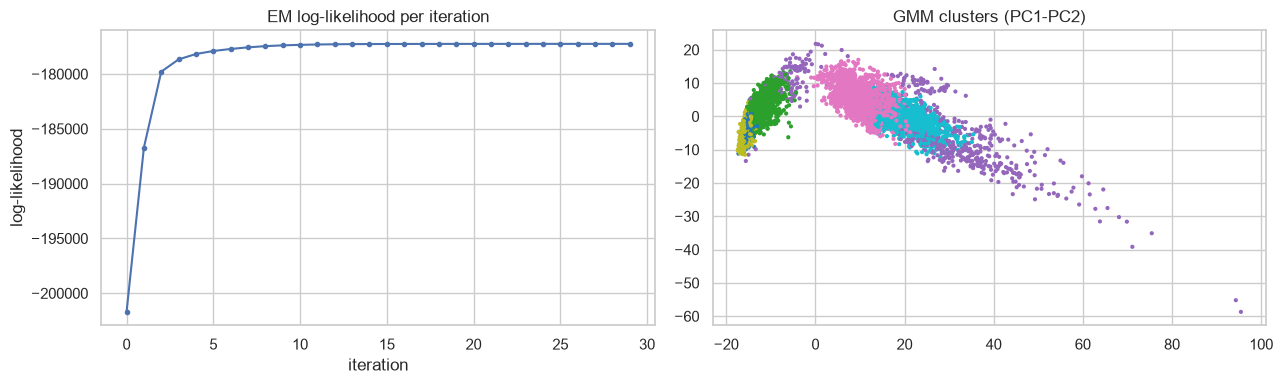

In [42]:
def logsumexp(a, axis=1):
    m = a.max(axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis, keepdims=True))).squeeze(axis)

def gmm_em(X, k, init_centres, iters=200, tol=1e-6, floor=1e-4):
    N, D = X.shape
    mu, var, pi = init_centres.copy(), np.tile(X.var(0), (k, 1)), np.full(k, 1 / k)
    ll_hist = []
    for _ in range(iters):
        logp = np.log(pi) - 0.5 * (np.log(2 * np.pi * var).sum(1) + (((X[:, None] - mu[None]) ** 2) / var[None]).sum(2))
        norm = logsumexp(logp); gamma = np.exp(logp - norm[:, None])      # E-step
        ll_hist.append(norm.sum())
        Nk = gamma.sum(0) + 1e-10                                         # M-step
        mu = (gamma.T @ X) / Nk[:, None]
        var = np.maximum((gamma.T @ X ** 2) / Nk[:, None] - mu ** 2, floor)
        pi = Nk / N
        if len(ll_hist) > 1 and abs(ll_hist[-1] - ll_hist[-2]) < tol * abs(ll_hist[-2]): break
    return gamma.argmax(1), ll_hist, (pi, mu, var)

gmm_lab, ll_hist, gmm_params = gmm_em(Xc, 6, km_C)
print(f"GMM (k=6, diag covariance): {len(ll_hist)} EM iterations | purity={purity(gmm_lab, ytr):.3f} | ARI={ari(gmm_lab, ytr):.3f}")
print("Log-likelihood non-decreasing:", bool(np.all(np.diff(ll_hist) > -1e-6)))
r2_results["GMM (EM) ARI"] = round(ari(gmm_lab, ytr), 3)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ll_hist, marker="."); axes[0].set(title="EM log-likelihood per iteration", xlabel="iteration", ylabel="log-likelihood")
axes[1].scatter(Xc[:, 0], Xc[:, 1], c=gmm_lab, s=4, cmap="tab10"); axes[1].set_title("GMM clusters (PC1-PC2)")
plt.tight_layout(); plt.show()

### R2.8 Hierarchical (agglomerative) clustering from scratch (Unit 3)

Start with every point as its own cluster and repeatedly merge the closest pair. With **Ward linkage** the merge cost is the increase in
within-cluster variance, updated cheaply with the Lance-Williams recurrence on squared distances:
$d_{(ij)k}=\dfrac{(n_i+n_k)\,d_{ik}+(n_j+n_k)\,d_{jk}-n_k\,d_{ij}}{n_i+n_j+n_k}$.
It needs the full $N\times N$ distance matrix ($O(N^2)$ memory, $O(N^2)$ per merge), so we run it on a stratified sample of 600 training windows.

In [43]:
def ward(X, k):
    n = len(X); D = ((X[:, None] - X[None]) ** 2).sum(2); np.fill_diagonal(D, np.inf)
    size = np.ones(n); active = np.ones(n, bool); lab = np.arange(n)
    for _ in range(n - k):
        i, j = np.unravel_index(np.argmin(D), D.shape)
        ni, nj, nk = size[i], size[j], size
        new = ((ni + nk) * D[i] + (nj + nk) * D[j] - nk * D[i, j]) / (ni + nj + nk)   # Lance-Williams
        D[i, :], D[:, i] = new, new; D[i, i] = np.inf
        D[j, :], D[:, j] = np.inf, np.inf
        size[i] += size[j]; active[j] = False; lab[lab == j] = i
    return np.unique(lab, return_inverse=True)[1]

idx = np.concatenate([rng.choice(np.where(ytr == c)[0], 100, replace=False) for c in range(6)])
hc_lab = ward(Ptr[idx, :10], 6)
print(f"Ward hierarchical (600-window sample, k=6): purity={purity(hc_lab, ytr[idx]):.3f} | ARI={ari(hc_lab, ytr[idx]):.3f}")
r2_results["Hierarchical (Ward) ARI"] = round(ari(hc_lab, ytr[idx]), 3)

Ward hierarchical (600-window sample, k=6): purity=0.483 | ARI=0.356


### R2.9 Verification against library implementations

A from-scratch model is only trustworthy if it reproduces a reference. Here (and only here) `sklearn` is used for comparison.

In [44]:
from sklearn.decomposition import PCA as SkPCA
from sklearn.linear_model import Ridge, LogisticRegression as SkLR
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans as SkKMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

rows = []
sk_pca = SkPCA(n_components=10).fit(Ztr)
rows.append(["PCA eigenvalues (top 10)", "max abs diff", float(np.abs(sk_pca.explained_variance_ - eig_vals[:10]).max())])

sk_ridge = Ridge(alpha=best_lam).fit(Xr_tr, yr_tr)
rows.append(["Ridge coefficients", "max abs diff", float(np.abs(sk_ridge.coef_ - w_ridge[1:]).max())])

sk_lr = SkLR(C=1 / best_alpha, max_iter=2000).fit(Ptr20, ytr_bin)
rows.append(["Bayesian LR (MAP) vs sklearn LR", "test acc: scratch / sklearn", f"{acc(p_map, yte_bin):.4f} / {sk_lr.score(Pte20, yte_bin):.4f}"])

sk_svm = LinearSVC(C=1 / (1e-3 * len(Ptr20)), max_iter=20000).fit(Ptr20, ytr_bin)
rows.append(["Linear SVM vs sklearn LinearSVC", "test acc: scratch / sklearn", f"{svm_acc:.4f} / {sk_svm.score(Pte20, yte_bin):.4f}"])

sk_km = SkKMeans(6, n_init=10, random_state=0).fit(Xc)
rows.append(["K-means vs sklearn", "ARI: scratch / sklearn", f"{ari(km_lab, ytr):.3f} / {adjusted_rand_score(ytr, sk_km.labels_):.3f}"])

sk_gmm = GaussianMixture(6, covariance_type="diag", random_state=0).fit(Xc)
rows.append(["GMM (EM) vs sklearn", "ARI: scratch / sklearn", f"{ari(gmm_lab, ytr):.3f} / {adjusted_rand_score(ytr, sk_gmm.predict(Xc)):.3f}"])

sk_hc = AgglomerativeClustering(6, linkage="ward").fit(Ptr[idx, :10])
rows.append(["Ward vs sklearn (same sample)", "ARI between the two clusterings", f"{adjusted_rand_score(hc_lab, sk_hc.labels_):.3f}"])
pd.DataFrame(rows, columns=["Algorithm", "Comparison", "Result"])

,Algorithm,Comparison,Result
0,PCA eigenvalues (top 10),max abs diff,0.0
1,Ridge coefficients,max abs diff,0.0
2,Bayesian LR (MAP) vs sklearn LR,test acc: scratch / sklearn,0.9997 / 0.9997
3,Linear SVM vs sklearn LinearSVC,test acc: scratch / sklearn,0.9997 / 0.9997
4,K-means vs sklearn,ARI: scratch / sklearn,0.427 / 0.427
5,GMM (EM) vs sklearn,ARI: scratch / sklearn,0.373 / 0.373
6,Ward vs sklearn (same sample),ARI between the two clusterings,1.000


### R2.10 Review 2 summary

* All seven Unit 2-3 algorithms are implemented with NumPy only and verified against library versions in §R2.9.
* **PCA** shows the 561 features are highly redundant (~100 components keep 95 % of the variance), which also explains the strong correlations seen in Review 1.
* **Regression, Bayesian logistic regression and the linear SVM** reach high accuracy on the dynamic/static split; the Bayesian predictive is slightly less over-confident than the plain MAP prediction (mean confidence 0.494 vs 0.500).
* **K-means, EM and Ward** recover the dynamic/static split but only moderately separate the 6 activities (ARI 0.36-0.43) and mix SITTING/STANDING (similar sensor signatures), the same pair that the supervised models confuse in §5.3.
* The supervised library classifiers (LR / SVM / RF, §4-§5) remain the best 6-class models; Review 3 then adds temporal context on top of them.

## UNIT 5 EXTENSION – TREE-BASED AND ENSEMBLE CLASSIFIERS (Module 1, continued)

This section extends Module 1 with the Unit 5 algorithms: a single **CART decision tree**, a **boosting** ensemble
(gradient boosting), and a **feature-importance** comparison against the Random Forest (a **bagging** ensemble) from
Module 1. All new numbers are stored in `unit5_results` / `unit5_predictions`, so the Module 1 tables and figures
above are not changed.

**Rules followed (no test-set leakage):**
* every hyperparameter is chosen with **GroupKFold (5 folds) grouped by subject on the training set only** or by an
  internal validation split of the training set;
* the 9 test subjects are used only once, for the final evaluation;
* every model is timed (`fit` only) so that the final table also compares training cost.

### 5.5 Reproducing the Module 1 Models (with fit time)

The helper below is the Module 1 `train_and_evaluate` logic, plus a fit timer, writing into new dictionaries.
LR, SVM and RF are refitted from `clone()` of the Module 1 models (same hyperparameters, same `random_state`), and we
check that every metric matches Module 1 exactly. Random Forest is refitted with `n_jobs=1`; with a fixed
`random_state` this does not change the trees, only the fit time.

In [45]:
import time
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import HistGradientBoostingClassifier

unit5_results, unit5_predictions, unit5_models = {}, {}, {}

def unit5_evaluate(model_name, model, verbose=True):
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    y_pred = model.predict(X_test)
    unit5_predictions[model_name] = y_pred
    unit5_models[model_name] = model
    unit5_results[model_name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Fit time (s)": fit_seconds,
    }
    if verbose:
        print(f"===== {model_name} =====")
        for metric, value in unit5_results[model_name].items():
            print(f"{metric:<20}: {value:.4f}")
        print()
        print(classification_report(y_test, y_pred, digits=4))

for name in ["Logistic Regression", "Support Vector Machine", "Random Forest"]:
    model = clone(trained_models[name])
    if name == "Random Forest":
        model.set_params(n_jobs=1)
    unit5_evaluate(name, model, verbose=False)
    for metric in ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)", "Train Accuracy"]:
        assert abs(unit5_results[name][metric] - results[name][metric]) < 1e-12, (name, metric)
    print(f"{name:<24} reproduced exactly | accuracy {unit5_results[name]['Accuracy']:.4f} | "
          f"fit time {unit5_results[name]['Fit time (s)']:.2f} s")

Logistic Regression      reproduced exactly | accuracy 0.9535 | fit time 0.34 s


Support Vector Machine   reproduced exactly | accuracy 0.9518 | fit time 0.83 s


Random Forest            reproduced exactly | accuracy 0.9291 | fit time 10.79 s


### 5.6 CART Decision Tree

**What it is.** CART (Classification And Regression Trees, Breiman et al., 1984) builds a **binary** tree: every
internal node asks one question of the form *"is feature $x_j \le t$?"* and sends the window left or right. A leaf
predicts the majority activity of the training windows that reach it.

**Gini impurity** of a node with class proportions $p_1,\dots,p_K$ ($K=6$ activities):
$$G = 1 - \sum_{k=1}^{K} p_k^2 .$$
$G=0$ for a pure node; it is largest ($1-1/K = 0.833$) when all six activities are equally mixed.

**Greedy recursive partitioning.** At each node CART tries every feature $j$ and every threshold $t$, and picks the
split with the largest impurity decrease
$$\Delta G = G(\text{parent}) - \frac{n_L}{n}G(L) - \frac{n_R}{n}G(R).$$
It then repeats on each child until nodes are pure (or too small). The choice is **greedy** (best split now, no
look-ahead), so the tree is fast to build but not globally optimal.

**Why pruning.** A fully grown tree memorises the training windows (train accuracy 100%) and overfits.
**Cost-complexity (weakest-link) pruning** chooses the subtree $T$ that minimises
$$R_\alpha(T) = R(T) + \alpha\,|T| ,$$
where $R(T)$ is the total (sample-weighted) impurity of the leaves, $|T|$ the number of leaves and $\alpha \ge 0$ the
price paid per leaf. $\alpha = 0$ keeps the full tree; a larger $\alpha$ removes branches whose impurity reduction is
worth less than $\alpha$ per extra leaf. In scikit-learn this is `ccp_alpha`.

**How we choose $\alpha$ (no test data).** 6 candidate values, each scored by **macro-F1 with GroupKFold(5) grouped by
subject** on the 21 training subjects, so every validation fold contains people the tree has never seen — the same
situation as the real test set.

,ccp_alpha,CV macro-F1 (mean),CV macro-F1 (std)
0,0.0000,0.8417,0.0326
1,0.0002,0.8434,0.0350
2,0.0005,0.8509,0.0319
3,0.0010,0.8615,0.0296
4,0.0020,0.8698,0.0240
5,0.0050,0.8607,0.0411


Chosen ccp_alpha = 0.002 (highest mean subject-wise CV macro-F1)


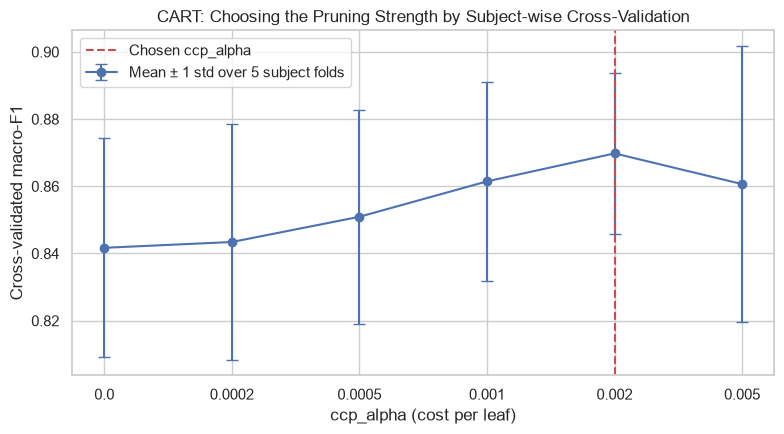

In [46]:
unit5_cv = GroupKFold(n_splits=5)
unit5_groups = train_df["subject"].to_numpy()
ccp_alpha_candidates = [0.0, 0.0002, 0.0005, 0.001, 0.002, 0.005]

cart_cv_rows = []
for alpha in ccp_alpha_candidates:
    scores = cross_val_score(DecisionTreeClassifier(criterion="gini", ccp_alpha=alpha, random_state=RANDOM_STATE),
                             X_train, y_train, groups=unit5_groups, cv=unit5_cv, scoring="f1_macro", n_jobs=1)
    cart_cv_rows.append({"ccp_alpha": alpha, "CV macro-F1 (mean)": scores.mean(), "CV macro-F1 (std)": scores.std()})
cart_cv_table = pd.DataFrame(cart_cv_rows)
best_ccp_alpha = cart_cv_table.loc[cart_cv_table["CV macro-F1 (mean)"].idxmax(), "ccp_alpha"]
display(cart_cv_table.round(4))
print(f"Chosen ccp_alpha = {best_ccp_alpha} (highest mean subject-wise CV macro-F1)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(range(len(ccp_alpha_candidates)), cart_cv_table["CV macro-F1 (mean)"],
            yerr=cart_cv_table["CV macro-F1 (std)"], marker="o", capsize=4, label="Mean ± 1 std over 5 subject folds")
ax.axvline(ccp_alpha_candidates.index(best_ccp_alpha), color="#C44E52", linestyle="--", label="Chosen ccp_alpha")
ax.set_xticks(range(len(ccp_alpha_candidates)), [str(a) for a in ccp_alpha_candidates])
ax.set_title("CART: Choosing the Pruning Strength by Subject-wise Cross-Validation")
ax.set_xlabel("ccp_alpha (cost per leaf)")
ax.set_ylabel("Cross-validated macro-F1")
ax.legend()
plt.tight_layout()
plt.show()

In [47]:
cart_model = DecisionTreeClassifier(criterion="gini", ccp_alpha=best_ccp_alpha, random_state=RANDOM_STATE)
unit5_evaluate("CART (pruned)", cart_model)

full_tree = DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Unpruned tree: depth {full_tree.get_depth()}, leaves {full_tree.get_n_leaves()}, "
      f"test accuracy {accuracy_score(y_test, full_tree.predict(X_test)):.4f}")
print(f"Pruned tree  : depth {cart_model.get_depth()}, leaves {cart_model.get_n_leaves()}, "
      f"test accuracy {unit5_results['CART (pruned)']['Accuracy']:.4f}")

===== CART (pruned) =====
Accuracy            : 0.8694
Precision (macro)   : 0.8669
Recall (macro)      : 0.8649
F1-score (macro)    : 0.8652
Train Accuracy      : 0.9543
Fit time (s)        : 2.0743

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.8649    0.7821    0.8214       491
          STANDING     0.8152    0.8872    0.8497       532
           WALKING     0.8861    0.9254    0.9053       496
WALKING_DOWNSTAIRS     0.8264    0.8048    0.8154       420
  WALKING_UPSTAIRS     0.8087    0.7898    0.7991       471

          accuracy                         0.8694      2947
         macro avg     0.8669    0.8649    0.8652      2947
      weighted avg     0.8696    0.8694    0.8688      2947



Unpruned tree: depth 18, leaves 163, test accuracy 0.8626
Pruned tree  : depth 9, leaves 32, test accuracy 0.8694


#### 5.6.1 Reading the Tree

The pruned tree is still too large to draw legibly, so we draw an **illustrative depth-3 tree** (same algorithm,
`max_depth=3`) to show how CART reasons. Each box shows the split question, the Gini impurity, the number of training
windows and the majority activity. The text dump below is the top 3 levels of the actual pruned model.

Illustrative depth-3 tree: test accuracy 0.7224


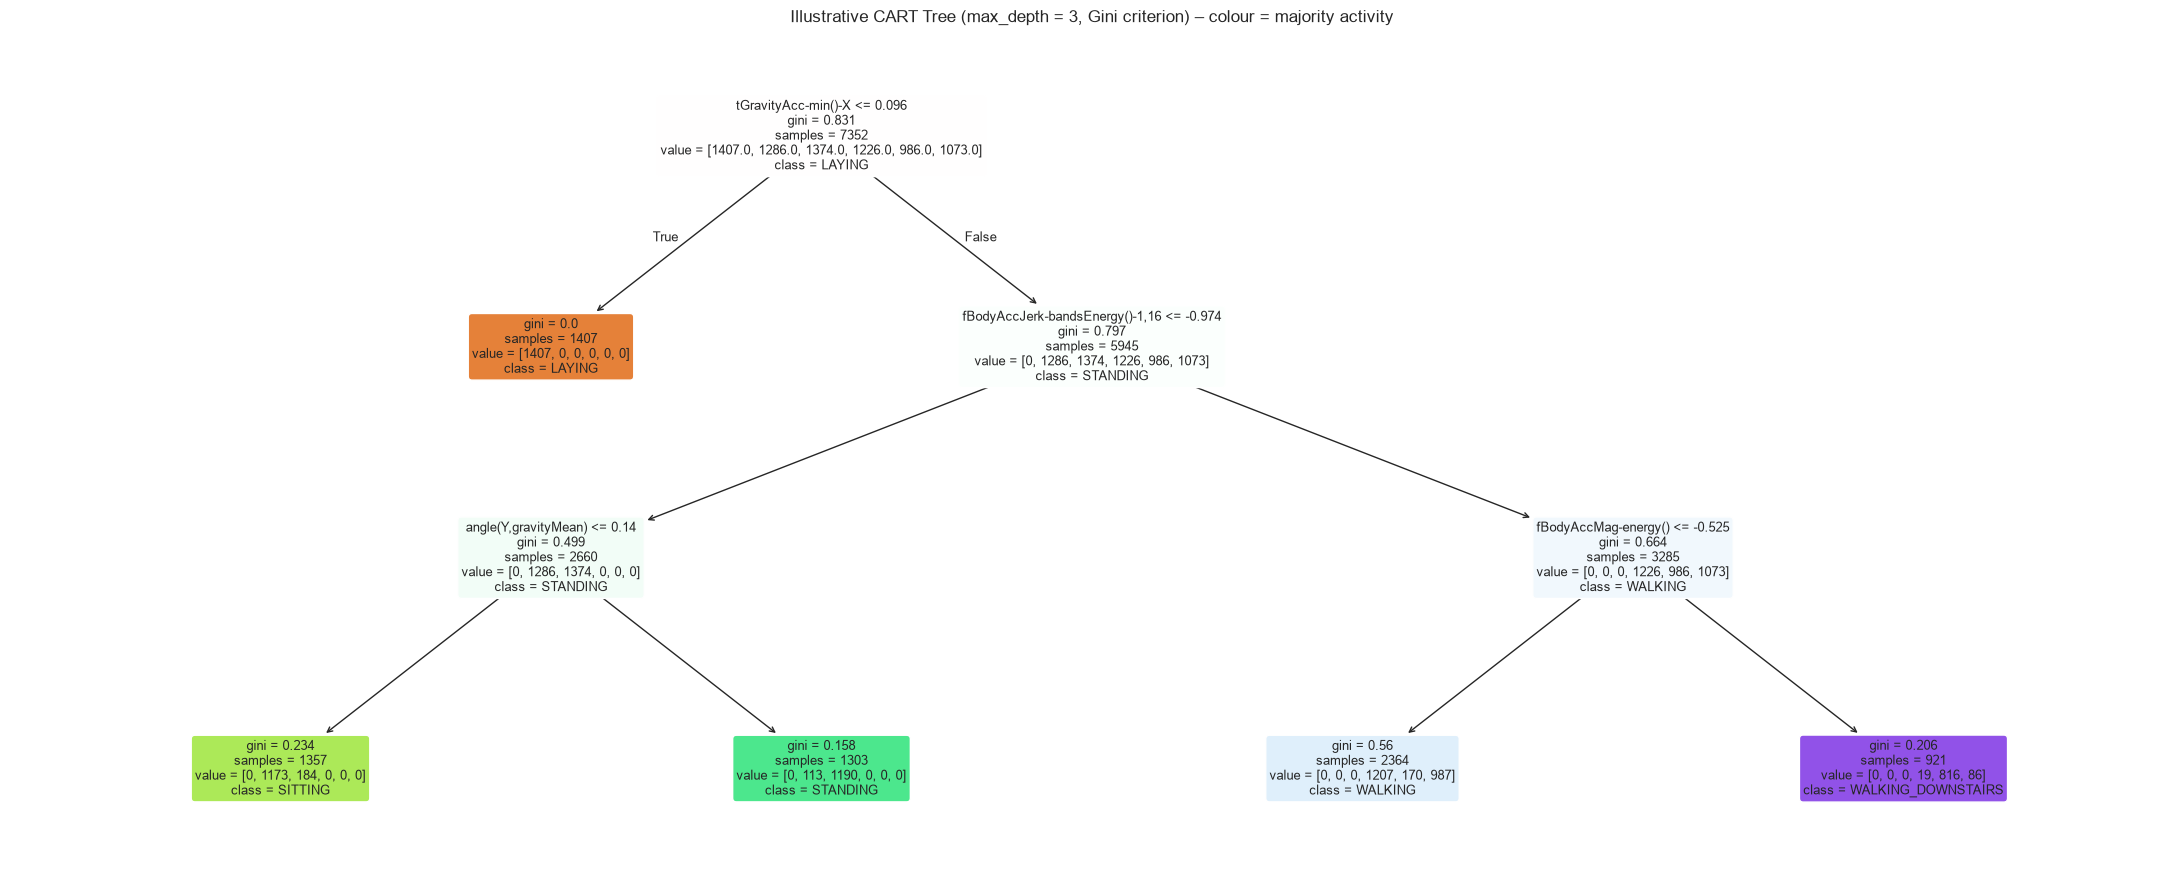

Top 3 levels of the pruned CART model:
|--- tGravityAcc-min()-X <= 0.096
|   |--- class: LAYING
|--- tGravityAcc-min()-X >  0.096
|   |--- fBodyAccJerk-bandsEnergy()-1,16 <= -0.974
|   |   |--- angle(Y,gravityMean) <= 0.140
|   |   |   |--- tGravityAcc-energy()-Y <= -1.000
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- tGravityAcc-energy()-Y >  -1.000
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- angle(Y,gravityMean) >  0.140
|   |   |   |--- tBodyGyro-min()-X <= 0.845
|   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- tBodyGyro-min()-X >  0.845
|   |   |   |   |--- class: SITTING
|   |--- fBodyAccJerk-bandsEnergy()-1,16 >  -0.974
|   |   |--- fBodyAccMag-energy() <= -0.525
|   |   |   |--- tGravityAcc-arCoeff()-Z,2 <= 0.564
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- tGravityAcc-arCoeff()-Z,2 >  0.564
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- fBodyAccMag-energy() >  -0.525
|   |   |   |--- tBod

In [48]:
illustrative_tree = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Illustrative depth-3 tree: test accuracy {accuracy_score(y_test, illustrative_tree.predict(X_test)):.4f}")

fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(illustrative_tree, feature_names=feature_columns, class_names=list(illustrative_tree.classes_),
          filled=True, rounded=True, impurity=True, proportion=False, fontsize=9, ax=ax)
ax.set_title("Illustrative CART Tree (max_depth = 3, Gini criterion) – colour = majority activity")
plt.tight_layout()
plt.show()

print("Top 3 levels of the pruned CART model:")
print(export_text(cart_model, feature_names=feature_columns, max_depth=3, decimals=3))

**Interpretation (values from the run above).**
* The **root split** `tGravityAcc-min()-X <= 0.096` isolates **LAYING** perfectly (Gini 0, 1 407 windows): when the
  phone lies flat, gravity no longer points along the phone's X-axis. Root Gini = 0.831, close to the 6-class maximum 0.833.
* The second split on a **jerk energy** feature (`fBodyAccJerk-bandsEnergy()-1,16`) separates the remaining **static**
  activities (sitting/standing) from the **walking** ones — the coarse static/dynamic split seen in the EDA box plots.
* Deeper splits handle the hard pairs: sitting vs standing (`angle(Y,gravityMean)`), and the three walking types.
* The depth-3 tree reaches only 0.722 test accuracy because with 5 leaves it can never predict WALKING_UPSTAIRS.
* Pruning with $\alpha = 0.002$ cut the tree from depth 18 / 163 leaves to depth 9 / 32 leaves, **raised** the
  subject-wise CV macro-F1 from 0.842 to 0.870 and the test accuracy from 0.863 to 0.869: the removed branches were
  fitting individual training subjects. Larger $\alpha$ (0.005) starts to underfit (CV 0.861).
* A single tree commits to one hard threshold per node, so it is very readable but clearly less accurate than the
  linear/kernel models of Module 1.

### 5.7 Boosting Ensemble: Histogram Gradient Boosting

**Bagging vs boosting (Unit 5).**

| | Bagging (Random Forest, Module 1) | Boosting (this section) |
|---|---|---|
| How trees are built | independently, in parallel, each on a bootstrap sample | **sequentially**, each tree corrects the errors of the previous ones |
| Base learner | deep, low-bias / high-variance trees | shallow, high-bias trees (weak learners) |
| Mainly reduces | variance | bias (and variance via shrinkage) |
| Combination | majority vote | weighted sum of tree outputs |

Random Forest already covers bagging, so the second ensemble is a **boosting** model, which gives the comparison the
syllabus asks for. We use gradient boosting rather than AdaBoost because it optimises the multi-class log-loss directly
and the histogram version trains in seconds on 561 features.

**Gradient boosting idea.** The model is an additive sum of trees, $F_M(x) = F_0(x) + \sum_{m=1}^{M} \nu\, h_m(x)$.
At step $m$, a small regression tree $h_m$ is fitted to the **negative gradient** of the loss (for log-loss this is
"true one-hot label − predicted probability", i.e. the residual errors), and added with learning rate $\nu$ (shrinkage).
For $K=6$ classes, one tree per class is grown at every iteration and a softmax turns the $K$ scores into
probabilities. (AdaBoost is the special case of exponential loss, which re-weights misclassified samples instead.)

**Histogram trick.** Each feature is binned into ≤ 255 bins, so split search scans bins instead of all 7 352 values.

**Settings and how chosen (no test data).** `learning_rate=0.1`, `max_iter=200` upper bound, `max_leaf_nodes=31`
(defaults). The number of boosting iterations is chosen by **early stopping**: 10% of the training windows are held
out internally and training stops when the validation log-loss has not improved for 10 iterations.

===== Gradient Boosting (HGB) =====
Accuracy            : 0.9281
Precision (macro)   : 0.9318
Recall (macro)      : 0.9263
F1-score (macro)    : 0.9275
Train Accuracy      : 0.9992
Fit time (s)        : 5.1418

                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       537
           SITTING     0.9279    0.8126    0.8664       491
          STANDING     0.8463    0.9417    0.8915       532
           WALKING     0.9088    0.9839    0.9448       496
WALKING_DOWNSTAIRS     0.9822    0.9214    0.9509       420
  WALKING_UPSTAIRS     0.9256    0.8981    0.9116       471

          accuracy                         0.9281      2947
         macro avg     0.9318    0.9263    0.9275      2947
      weighted avg     0.9305    0.9281    0.9277      2947

Boosting iterations kept by early stopping: 85 of 200 (510 trees in total, one per class per iteration)


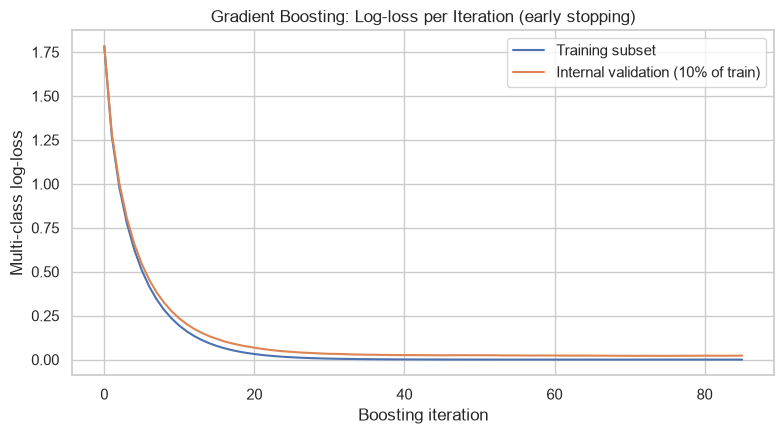

In [49]:
hgb_model = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, early_stopping=True,
                                           validation_fraction=0.1, n_iter_no_change=10,
                                           random_state=RANDOM_STATE)
unit5_evaluate("Gradient Boosting (HGB)", hgb_model)
print(f"Boosting iterations kept by early stopping: {hgb_model.n_iter_} of {hgb_model.max_iter} "
      f"({hgb_model.n_iter_ * len(hgb_model.classes_)} trees in total, one per class per iteration)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(-np.asarray(hgb_model.train_score_), label="Training subset")
ax.plot(-np.asarray(hgb_model.validation_score_), label="Internal validation (10% of train)")
ax.set_title("Gradient Boosting: Log-loss per Iteration (early stopping)")
ax.set_xlabel("Boosting iteration")
ax.set_ylabel("Multi-class log-loss")
ax.legend()
plt.tight_layout()
plt.show()

**Caveat on early stopping.** The internal validation split is a random 10% of training *windows*, not of
*subjects*, so it shares people with the fitting data. It is therefore slightly optimistic, but it still uses training
data only and never touches the test subjects.

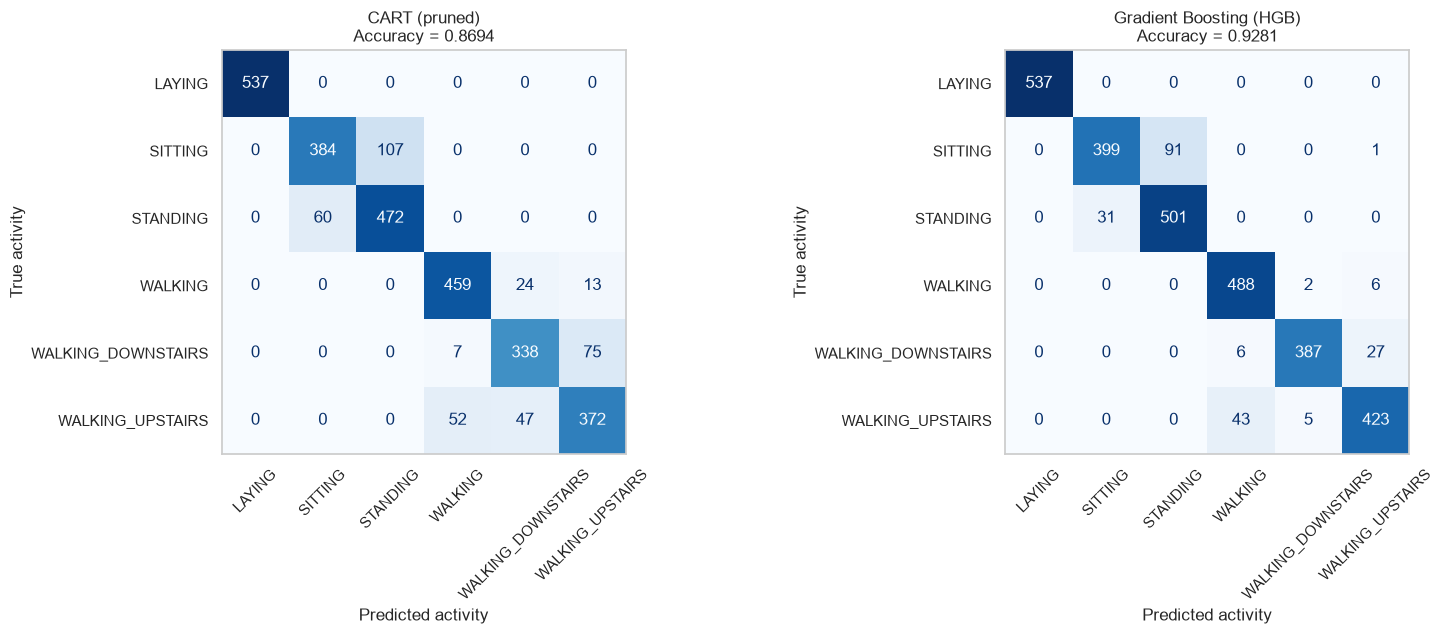

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, name in zip(axes, ["CART (pruned)", "Gradient Boosting (HGB)"]):
    cm = confusion_matrix(y_test, unit5_predictions[name], labels=activity_classes)
    ConfusionMatrixDisplay(cm, display_labels=activity_classes).plot(ax=ax, cmap="Blues", colorbar=False,
                                                                     xticks_rotation=45)
    ax.set_title(f"{name}\nAccuracy = {unit5_results[name]['Accuracy']:.4f}")
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("True activity")
    ax.grid(False)
plt.tight_layout()
plt.show()

### 5.8 Feature Importance: CART vs Random Forest

**Gini (mean decrease in impurity) importance** of feature $j$ = total $\Delta G$ (weighted by the number of samples
at the node) over all nodes that split on $j$, normalised to sum to 1. For Random Forest it is averaged over the 200
trees. It is computed from training data and is free, but it is biased toward features with many split points and
**splits credit arbitrarily between correlated features**.

Features used by the pruned CART tree: 26 of 561
Features used by the Random Forest:    561 of 561
Share of total importance in the top 15: CART 0.968 | RF 0.314
Features in both top-15 lists: ['angle(Y,gravityMean)', 'fBodyAccJerk-bandsEnergy()-1,16', 'tGravityAcc-energy()-Y', 'tGravityAcc-max()-Y', 'tGravityAcc-min()-X']


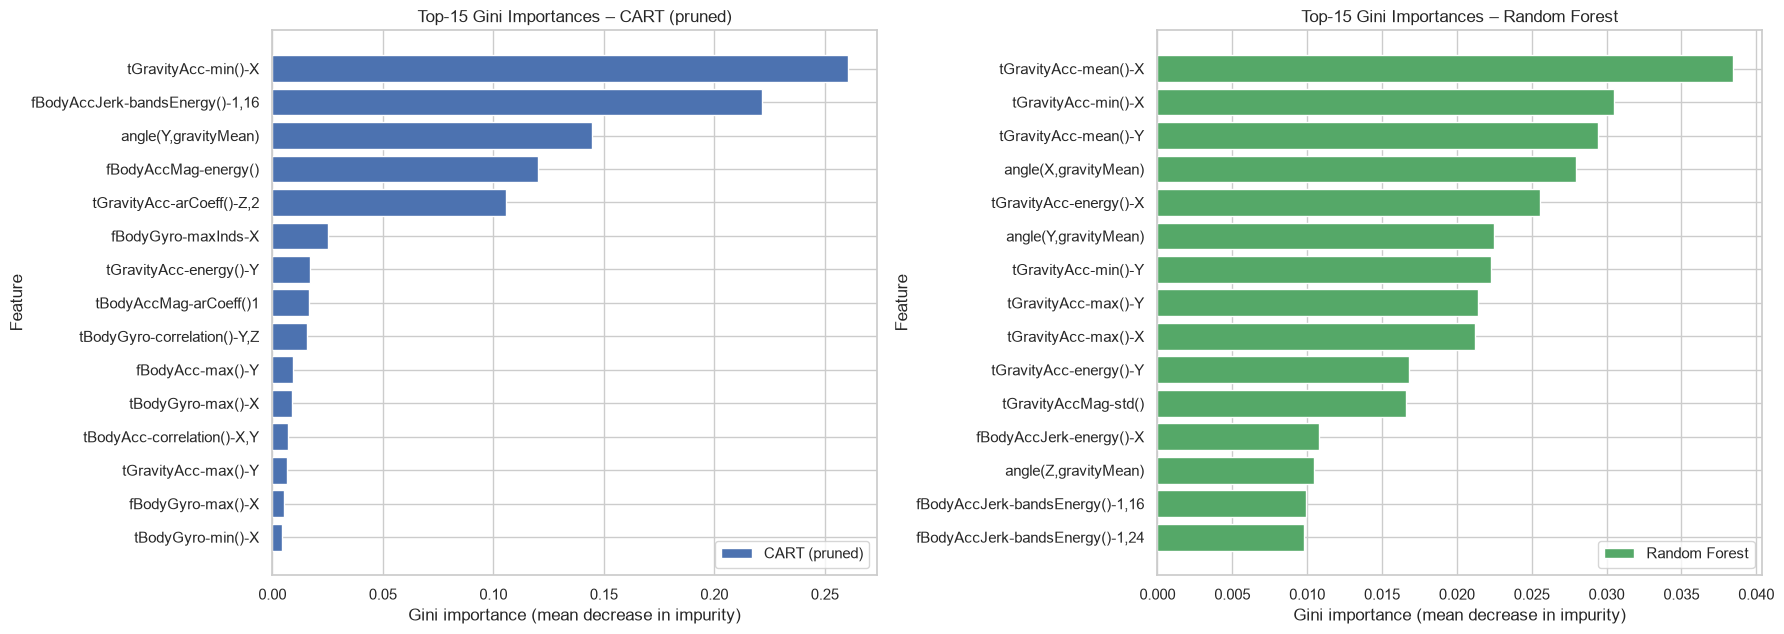

In [51]:
rf_refit = unit5_models["Random Forest"]
importance_table = pd.DataFrame({
    "CART (pruned)": cart_model.feature_importances_,
    "Random Forest": rf_refit.feature_importances_,
}, index=feature_columns)

top15_cart = importance_table["CART (pruned)"].nlargest(15)
top15_rf = importance_table["Random Forest"].nlargest(15)
print(f"Features used by the pruned CART tree: {(importance_table['CART (pruned)'] > 0).sum()} of {len(feature_columns)}")
print(f"Features used by the Random Forest:    {(importance_table['Random Forest'] > 0).sum()} of {len(feature_columns)}")
print(f"Share of total importance in the top 15: CART {top15_cart.sum():.3f} | RF {top15_rf.sum():.3f}")
print(f"Features in both top-15 lists: {sorted(set(top15_cart.index) & set(top15_rf.index))}")

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
for ax, (name, top) in zip(axes, [("CART (pruned)", top15_cart), ("Random Forest", top15_rf)]):
    ax.barh(top.index[::-1], top.values[::-1], color="#4C72B0" if name.startswith("CART") else "#55A868",
            label=name)
    ax.set_title(f"Top-15 Gini Importances – {name}")
    ax.set_xlabel("Gini importance (mean decrease in impurity)")
    ax.set_ylabel("Feature")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [52]:
correlation_abs = X_train.corr().abs().to_numpy()
high_corr_pairs = int((np.triu(correlation_abs, k=1) > 0.9).sum())
print(f"Feature pairs with |correlation| > 0.9 on the training set: {high_corr_pairs}")

Feature pairs with |correlation| > 0.9 on the training set: 8206


**Interpretation.** The pruned CART tree uses only 26 of 561 features and its top 15 hold 96.8% of the total
importance (the root feature `tGravityAcc-min()-X` alone takes the LAYING split), while the Random Forest uses all 561
features and its top 15 hold only 31.4%. Five features appear in both top-15 lists. The Random Forest spreads importance over many features, because each
tree sees random feature subsets and many of the 561 features are near-duplicates (thousands of pairs have
$|r| > 0.9$). So importances are **unstable** across models: two strongly correlated features can swap rank, or one can
take all the credit in CART and share it in RF. Both models, however, point to the same *kinds* of features —
gravity-orientation and acceleration-energy/jerk features — which match the EDA.

#### 5.8.1 Permutation Importance (test set, interpretation only)

Permutation importance = drop in test macro-F1 when one feature column is randomly shuffled (breaking its link with the
label), averaged over 5 shuffles. It is model-agnostic, so it also works for gradient boosting, which has no Gini
importance. To keep it cheap we only permute the **top-20 RF Gini features**.

**It is computed on the test set purely to interpret the final model — it is not used to select features or tune
anything.** Because correlated copies of a feature remain unshuffled, a feature's permutation importance can be close to
zero even if the concept it measures is important.

Permutation importance for: Gradient Boosting (HGB) (baseline test macro-F1 0.9275)


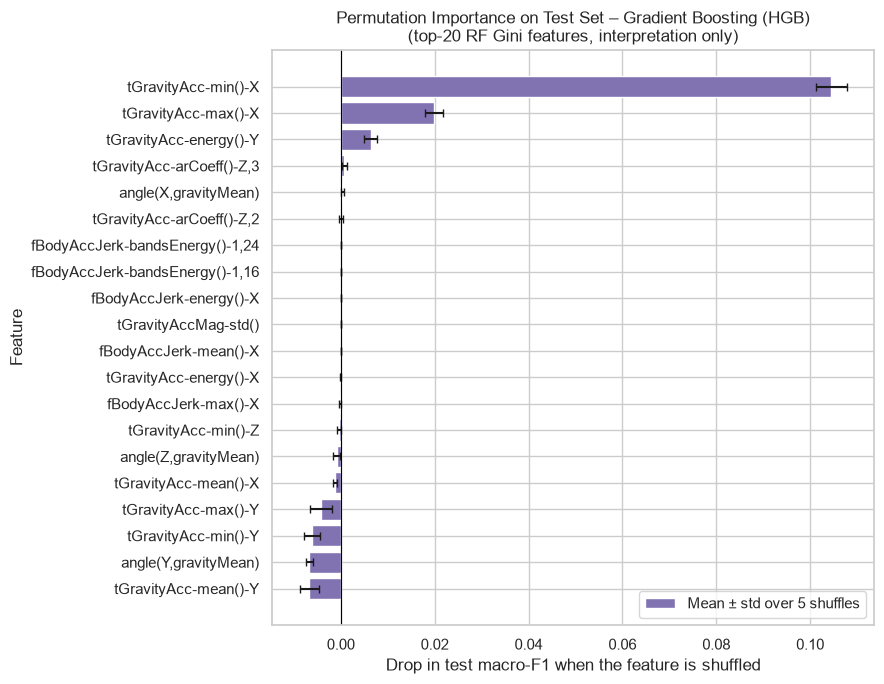

,mean drop,std
tGravityAcc-min()-X,0.1045,0.0033
tGravityAcc-max()-X,0.0199,0.0019
tGravityAcc-energy()-Y,0.0063,0.0013
"tGravityAcc-arCoeff()-Z,3",0.0007,0.0006
"angle(X,gravityMean)",0.0003,0.0003
"tGravityAcc-arCoeff()-Z,2",0.0001,0.0004
fBodyAccJerk-energy()-X,0.0000,0.0000
"fBodyAccJerk-bandsEnergy()-1,24",0.0000,0.0000
"fBodyAccJerk-bandsEnergy()-1,16",0.0000,0.0000
tGravityAccMag-std(),0.0000,0.0000


In [53]:
tree_models = ["CART (pruned)", "Random Forest", "Gradient Boosting (HGB)"]
best_tree_model_name = max(tree_models, key=lambda n: unit5_results[n]["F1-score (macro)"])
best_tree_model = unit5_models[best_tree_model_name]
top20_features = importance_table["Random Forest"].nlargest(20).index

rng = np.random.RandomState(RANDOM_STATE)
baseline_f1 = f1_score(y_test, best_tree_model.predict(X_test), average="macro")
perm_drops = {}
for feature in top20_features:
    drops = []
    for _ in range(5):
        X_shuffled = X_test.copy()
        X_shuffled[feature] = rng.permutation(X_shuffled[feature].to_numpy())
        drops.append(baseline_f1 - f1_score(y_test, best_tree_model.predict(X_shuffled), average="macro"))
    perm_drops[feature] = drops
perm_table = pd.DataFrame({"mean drop": {f: np.mean(d) for f, d in perm_drops.items()},
                           "std": {f: np.std(d) for f, d in perm_drops.items()}}).sort_values("mean drop")

print(f"Permutation importance for: {best_tree_model_name} (baseline test macro-F1 {baseline_f1:.4f})")
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(perm_table.index, perm_table["mean drop"], xerr=perm_table["std"], color="#8172B2", capsize=3,
        label="Mean ± std over 5 shuffles")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Permutation Importance on Test Set – {best_tree_model_name}\n(top-20 RF Gini features, interpretation only)")
ax.set_xlabel("Drop in test macro-F1 when the feature is shuffled")
ax.set_ylabel("Feature")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()
display(perm_table.sort_values("mean drop", ascending=False).round(4))

**Interpretation.** For HGB almost all of the measurable dependence is on one feature, `tGravityAcc-min()-X`
(shuffling it drops test macro-F1 by ≈ 0.10, since it is the LAYING detector), then `tGravityAcc-max()-X` (≈ 0.02).
Most other top-20 RF features have a drop ≈ 0 — not because they are useless, but because correlated copies left
unshuffled carry the same information. Several drops are slightly **negative** (shuffling a gravity-Y feature makes the
test score a little *better*), a sign that the model relies on subject-specific phone-orientation values that do not
transfer to the new test subjects. Gini importance (RF) and permutation importance (HGB) therefore rank features
differently; neither should be read as a stable "true" ranking with 561 correlated features.

### 5.9 Final Comparison: Module 1 Models + Unit 5 Models

All five models are evaluated on the same 2 947 windows from the 9 unseen test subjects. Train accuracy is measured on
the training windows themselves (resubstitution), so it shows how much each model memorises, not how well it
generalises.

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Train Accuracy,Fit time (s),Train-Test gap
Model,,,,,,,
Logistic Regression,0.9535,0.9563,0.9520,0.9532,0.9963,0.3420,0.0428
Support Vector Machine,0.9518,0.9525,0.9504,0.9511,0.9867,0.8327,0.0349
Gradient Boosting (HGB),0.9281,0.9318,0.9263,0.9275,0.9992,5.1418,0.0711
Random Forest,0.9291,0.9303,0.9263,0.9275,1.0000,10.7922,0.0709
CART (pruned),0.8694,0.8669,0.8649,0.8652,0.9543,2.0743,0.0849


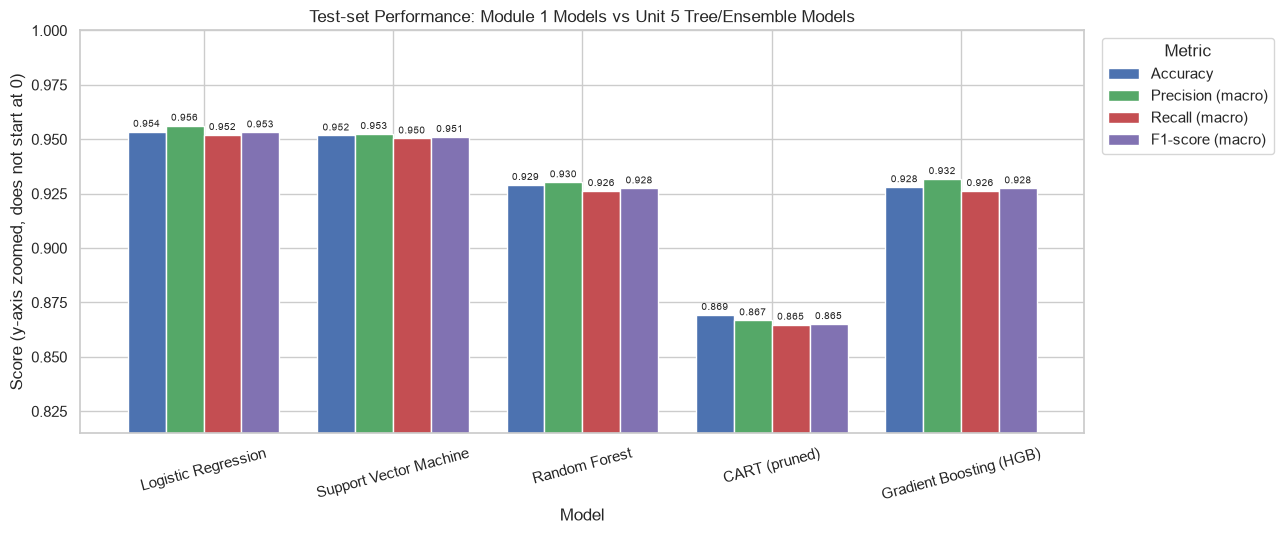

In [54]:
unit5_comparison = pd.DataFrame(unit5_results).T
unit5_comparison.index.name = "Model"
unit5_comparison["Train-Test gap"] = unit5_comparison["Train Accuracy"] - unit5_comparison["Accuracy"]
display(unit5_comparison.sort_values("F1-score (macro)", ascending=False).round(4))

ax = unit5_comparison[main_metrics].plot(kind="bar", figsize=(13, 5.5), width=0.8,
                                         color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.set_ylim(max(0, unit5_comparison[main_metrics].min().min() - 0.05), 1.0)
ax.set_title("Test-set Performance: Module 1 Models vs Unit 5 Tree/Ensemble Models")
ax.set_xlabel("Model")
ax.set_ylabel("Score (y-axis zoomed, does not start at 0)")
ax.legend(title="Metric", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout()
plt.show()

**Discussion (viva points, numbers from the table above).**
* **Single tree vs ensembles.** Pruned CART is the weakest model (accuracy 0.869, macro-F1 0.865). Both ensembles gain
  about 6 points (macro-F1 0.9275), because averaging (bagging) or sequentially correcting (boosting) many trees removes
  most of the variance of one greedy tree.
* **Bagging vs boosting.** RF and HGB tie on macro-F1 (0.9275) and differ by only 0.001 in accuracy
  (0.9291 vs 0.9281, 3 test windows). They make *different* errors: HGB is better on WALKING_DOWNSTAIRS (F1 0.951 vs 0.913), RF on
  SITTING (0.900 vs 0.866). HGB trained faster here (≈ 7 s vs ≈ 10 s single-threaded) because early stopping kept only
  85 iterations and histogram binning makes split search cheap.
* **Linear models are still best.** LR (0.9532) and SVM (0.9511) beat every tree model. The 561 features were
  hand-engineered (means, energies, angles, FFT bands), so the classes are already close to linearly separable;
  axis-parallel tree splits approximate the smooth sitting/standing boundary less well.
* **Train accuracy ≈ 1.0** for RF/HGB is expected (trees can fit training windows exactly) and is not by itself proof of
  overfitting; the test score is what matters. Part of every train–test gap is **subject shift** (new people move
  differently), not only overfitting.
* **Single split caveat.** Differences of a few thousandths (0.001 ≈ 3 test windows) are within the noise of one
  9-subject test set; LR vs SVM and RF vs HGB should be called ties.

# MODULE 2 – TEMPORAL ACTIVITY PREDICTION USING HMM

Module 1 classifies every 2.56-second sensor window **independently**. The classifier never looks at the window just before or just after. Real activities last many seconds, so neighbouring windows almost always share the same activity. Module 2 uses this temporal structure with **Markov models** and **Hidden Markov Models (HMMs)**.

**Pipeline**

```
sensor feature window ─► Module 1 classifier (Logistic Regression) ─► predicted activity  = observation o_t
                                                                              │
                                          HMM λ = (π, A, B)  +  Viterbi  ◄────┘
                                                                              │
                                                     temporally decoded activity sequence q*_1 … q*_T
```

We use **Logistic Regression** as the observation source because it was the best Module 1 model (macro F1 = 0.9532).

| Section | Content |
|---|---|
| 6 | Data audit: is there a real time order in the data? |
| 7 | Markov model: states, transitions, transition matrix |
| 8 | Hidden Markov Model: initial, transition and emission probabilities |
| 9 | Forward, Backward and Viterbi algorithms, with a hand-verifiable example |
| 10 | Applying the HMM to HAR and comparative analysis, plus soft emissions from class probabilities (§10.9) |
| 11 | Validated evaluation on HAPT continuous recordings with real transitions, including fixed-lag decoding |

## 6. Can the Dataset Be Treated as a Time Series? (Temporal Data Audit)

A Markov model needs **consecutive observations in time**. Consecutive CSV rows are *not* automatically consecutive moments, so we need evidence first.

**How we test it.** The UCI README says each window has 128 raw readings (2.56 s at 50 Hz) and **50 % overlap**. If window $t+1$ really follows window $t$ in the same recording, it must start with exactly the last 64 raw readings of window $t$:

$$\text{window}_t[64{:}128] \;=\; \text{window}_{t+1}[0{:}64]$$

The 561 engineered features cannot show this, but the raw `Inertial Signals` in the original UCI folder can. We first confirm that `train.csv` / `test.csv` have the same row order as the raw UCI files, then run the overlap test on every pair of consecutive rows.

In [55]:
from pathlib import Path

UCI_DIR = Path("../data/external") / "human+activity+recognition+using+smartphones" / "UCI HAR Dataset"
HALF_WINDOW = 64

def load_continuity(split, csv_df):
    raw_subjects = np.loadtxt(UCI_DIR / split / f"subject_{split}.txt", dtype=int)
    raw_first_features = np.loadtxt(UCI_DIR / split / f"X_{split}.txt", usecols=(0, 1, 2))
    assert (raw_subjects == csv_df["subject"].to_numpy()).all(), "subject order differs from raw UCI files"
    assert np.allclose(raw_first_features, csv_df[feature_columns[:3]].to_numpy()), "row order differs"
    signal = np.loadtxt(UCI_DIR / split / "Inertial Signals" / f"total_acc_x_{split}.txt")
    return np.abs(signal[:-1, HALF_WINDOW:] - signal[1:, :HALF_WINDOW]).max(axis=1) < 1e-6

train_subjects = train_df["subject"].to_numpy()
test_subjects = test_df["subject"].to_numpy()
train_continuous = load_continuity("train", train_df)
test_continuous = load_continuity("test", test_df)
print("CSV row order matches the raw UCI files for train and test.")

CSV row order matches the raw UCI files for train and test.


In [56]:
def continuity_summary(continuous, subjects, labels):
    labels = np.asarray(labels)
    same_subject = subjects[1:] == subjects[:-1]
    same_activity = labels[1:] == labels[:-1]
    return {
        "Consecutive row pairs": len(continuous),
        "Verified continuous (overlap matches)": continuous.sum(),
        "Continuous although subject changes": (continuous & ~same_subject).sum(),
        "Continuous although activity changes": (continuous & ~same_activity).sum(),
        "Gap inside same subject and activity": (~continuous & same_subject & same_activity).sum(),
        "Gap where activity changes": (~continuous & same_subject & ~same_activity).sum(),
        "Subject boundaries": (~same_subject).sum(),
    }

pd.DataFrame({"Train": continuity_summary(train_continuous, train_subjects, y_train),
              "Test": continuity_summary(test_continuous, test_subjects, y_test)})

,Train,Test
Consecutive row pairs,7351,2946
Verified continuous (overlap matches),6752,2690
Continuous although subject changes,0,0
Continuous although activity changes,0,0
Gap inside same subject and activity,320,137
Gap where activity changes,259,111
Subject boundaries,20,8


In [57]:
def activity_block_order(labels):
    labels = np.asarray(labels)
    return [labels[0]] + [b for a, b in zip(labels[:-1], labels[1:]) if a != b]

for subject in [train_subjects[0], test_subjects[0]]:
    labels = pd.concat([y_train[train_subjects == subject], y_test[test_subjects == subject]])
    print(f"Subject {subject}: " + " → ".join(activity_block_order(labels)) + "\n")

Subject 1: STANDING → SITTING → LAYING → WALKING → WALKING_DOWNSTAIRS → WALKING_UPSTAIRS → STANDING → SITTING → LAYING → SITTING → LAYING → WALKING → WALKING_DOWNSTAIRS → WALKING_UPSTAIRS → WALKING_DOWNSTAIRS

Subject 2: STANDING → SITTING → LAYING → WALKING → WALKING_DOWNSTAIRS → WALKING_UPSTAIRS → STANDING → SITTING → LAYING → WALKING → WALKING_DOWNSTAIRS → WALKING_UPSTAIRS



### 6.1 Audit Findings and How We Build Sequences

**What the evidence shows**

1. The CSV rows are in the original UCI order, sorted by subject. Inside each subject, the activity blocks follow the documented experiment protocol: *standing → sitting → laying → walking → walking downstairs → walking upstairs*, performed twice.
2. About 92 % of consecutive pairs are **proven continuous** (exact raw-signal overlap). No proven-continuous pair ever crosses a subject boundary **or an activity change**.
3. Every activity change therefore happens across a **gap**. The UCI authors removed the transition periods between activities (e.g. the act of standing up), so we never observe the exact moment of change. Some further gaps occur inside one activity block, where windows were dropped.

**Decision: two kinds of evaluation sequences, never joined across subjects**

| Sequence type | Definition | What it is good for | Limitation |
|---|---|---|---|
| **Subject stream** (primary) | All windows of one subject in recording order | Realistic decoding: contains real activity changes, in true chronological order | Steps across gaps are longer than 1.28 s, and transitions follow a scripted protocol |
| **Verified segment** (strict) | Maximal runs where every consecutive pair is overlap-verified | Exact 1.28 s time steps, proven continuity | Each segment contains only one activity, so it tests noise smoothing but not the detection of activity changes |

**This limitation is addressed in Section 11**, which repeats the evaluation on the HAPT dataset, where continuous recordings with labelled transitions are available.

**Effect of the 50 % overlap on interpreting transitions**
- One time step is the window hop, **1.28 s**, not the 2.56 s window length.
- Consecutive windows share half of their raw data. This makes self-transitions very likely by construction, and it makes classifier errors in neighbouring windows correlated. The HMM assumption that each observation depends only on its own state is therefore only approximately true.

In [58]:
def split_into_sequences(subjects, continuous=None):
    boundary = subjects[1:] != subjects[:-1]
    if continuous is not None:
        boundary = boundary | ~continuous
    return np.split(np.arange(len(subjects)), np.flatnonzero(boundary) + 1)

train_streams = split_into_sequences(train_subjects)
test_streams = split_into_sequences(test_subjects)
test_segments = split_into_sequences(test_subjects, test_continuous)

for sequences, subjects in [(train_streams, train_subjects), (test_streams, test_subjects), (test_segments, test_subjects)]:
    assert all(len(np.unique(subjects[idx])) == 1 for idx in sequences)
    assert (np.concatenate(sequences) == np.arange(len(subjects))).all()
assert all(test_continuous[idx[:-1]].all() for idx in test_segments)

pd.DataFrame({name: {"Sequences": len(seqs), "Min length": min(map(len, seqs)),
                     "Median length": int(np.median(list(map(len, seqs)))), "Max length": max(map(len, seqs))}
              for name, seqs in [("Train subject streams", train_streams), ("Test subject streams", test_streams),
                                 ("Test verified segments", test_segments)]}).T

,Sequences,Min length,Median length,Max length
Train subject streams,21,281,347,409
Test subject streams,9,288,320,381
Test verified segments,257,2,11,23


## 7. Markov Model (Markov Chain) of Activities

**What it does.** A Markov chain describes how a system moves between a finite set of **states** over discrete time steps.

- **State** $q_t$: the activity at time step $t$. Here there are $N = 6$ states (LAYING, SITTING, STANDING, WALKING, WALKING_DOWNSTAIRS, WALKING_UPSTAIRS).
- **Transition**: moving from the state at $t-1$ to the state at $t$. One step is 1.28 s. Staying in the same activity is also a transition (a *self-transition*).
- **Markov property**: the next state depends only on the current state, not on the full history:
$$P(q_t \mid q_{t-1}, q_{t-2}, \dots, q_1) = P(q_t \mid q_{t-1})$$
- **State transition probability**: $a_{ij} = P(q_t = j \mid q_{t-1} = i)$.
- **Transition probability matrix** $A = [a_{ij}]$ is an $N \times N$ matrix. Every row sums to 1.

**Estimation (maximum likelihood with Laplace smoothing), training subjects only.** Count transitions $n_{ij}$ between consecutive windows inside each training subject stream:
$$a_{ij} = \frac{n_{ij} + \alpha}{\sum_k n_{ik} + N\alpha}, \qquad \alpha = 1$$
Smoothing gives transitions never seen in training (e.g. LAYING → WALKING_UPSTAIRS) a small non-zero probability, so a single unusual window cannot produce a probability of exactly 0 (or $\log 0 = -\infty$).

**Initial probabilities** $\pi_i = P(q_1 = i)$ are estimated in the same way from the first window of each training stream.

**Interpretation.** The diagonal $a_{ii}$ measures how "sticky" an activity is. The expected number of steps spent in state $i$ before leaving is $1/(1-a_{ii})$.

In [59]:
N_STATES = len(activity_classes)
state_index = {activity: i for i, activity in enumerate(activity_classes)}
SHORT = {"LAYING": "LAY", "SITTING": "SIT", "STANDING": "STAND", "WALKING": "WALK",
         "WALKING_DOWNSTAIRS": "DOWN", "WALKING_UPSTAIRS": "UP"}
short_names = [SHORT[a] for a in activity_classes]
LAPLACE_ALPHA = 1.0

train_states = y_train.map(state_index).to_numpy()
test_states = y_test.map(state_index).to_numpy()

def count_transitions(state_sequences, n_states):
    counts = np.zeros((n_states, n_states))
    for states in state_sequences:
        np.add.at(counts, (states[:-1], states[1:]), 1)
    return counts

def normalise_rows(counts, alpha=LAPLACE_ALPHA):
    smoothed = counts + alpha
    return smoothed / smoothed.sum(axis=-1, keepdims=True)

transition_counts = count_transitions([train_states[idx] for idx in train_streams], N_STATES)
A = normalise_rows(transition_counts)
start_counts = np.bincount([train_states[idx[0]] for idx in train_streams], minlength=N_STATES)
pi = normalise_rows(start_counts)

print("Transition counts n_ij (rows = from, columns = to), training subjects only:")
pd.DataFrame(transition_counts.astype(int), index=short_names, columns=short_names)

Transition counts n_ij (rows = from, columns = to), training subjects only:


,LAY,SIT,STAND,WALK,DOWN,UP
LAY,1364,1,0,42,0,0
SIT,43,1243,0,0,0,0
STAND,0,42,1332,0,0,0
WALK,0,0,0,1184,42,0
DOWN,0,0,0,0,930,54
UP,0,0,21,0,14,1019


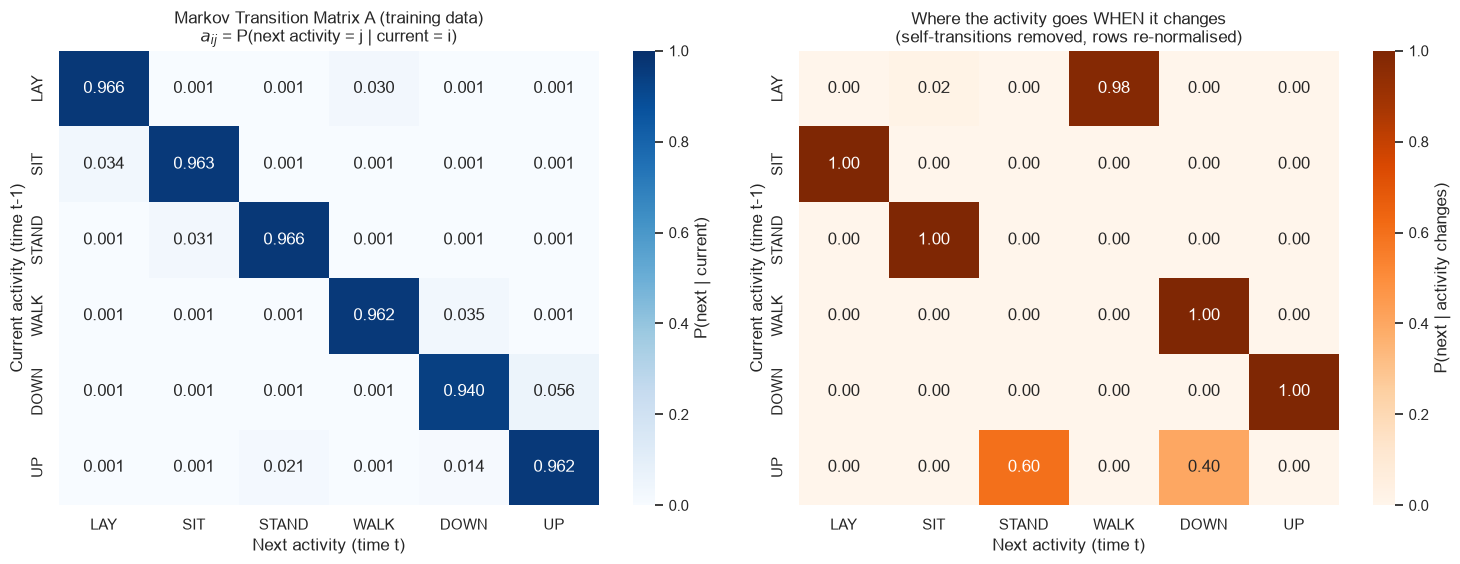

In [60]:
change_counts = transition_counts * (1 - np.eye(N_STATES))
change_probs = change_counts / change_counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
sns.heatmap(A, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=axes[0],
            xticklabels=short_names, yticklabels=short_names, cbar_kws={"label": "P(next | current)"})
axes[0].set_title("Markov Transition Matrix A (training data)\n$a_{ij}$ = P(next activity = j | current = i)")
sns.heatmap(change_probs, annot=True, fmt=".2f", cmap="Oranges", vmin=0, vmax=1, ax=axes[1],
            xticklabels=short_names, yticklabels=short_names, cbar_kws={"label": "P(next | activity changes)"})
axes[1].set_title("Where the activity goes WHEN it changes\n(self-transitions removed, rows re-normalised)")
for ax in axes:
    ax.set_xlabel("Next activity (time t)")
    ax.set_ylabel("Current activity (time t-1)")
plt.tight_layout()
plt.show()

In [61]:
WINDOW_STEP_SECONDS = 1.28
pd.DataFrame({
    "Self-transition a_ii": np.diag(A),
    "Expected run length (windows)": 1 / (1 - np.diag(A)),
    "Expected run length (seconds)": WINDOW_STEP_SECONDS / (1 - np.diag(A)),
    "Initial probability pi_i": pi,
}, index=activity_classes).round(3)

,Self-transition a_ii,Expected run length (windows),Expected run length (seconds),Initial probability pi_i
LAYING,0.966,29.438,37.680,0.037
SITTING,0.963,26.917,34.453,0.037
STANDING,0.966,29.362,37.583,0.815
WALKING,0.962,26.213,33.552,0.037
WALKING_DOWNSTAIRS,0.940,16.780,21.478,0.037
WALKING_UPSTAIRS,0.962,26.500,33.920,0.037


**Reading the transition matrix**

- The **diagonal dominates** (≈ 0.94–0.97). Once a person is in an activity, the next window is almost always the same activity. This is the main temporal knowledge the model contributes.
- The right-hand heatmap shows that activity changes are highly structured: STAND → SIT, SIT → LAY, LAY → WALK, WALK → DOWN, DOWN → UP. This is the **scripted UCI protocol**, not free-living behaviour. A model trained on this would not generalise these specific orders to daily life. Section 10.3 tests how much of the benefit comes from this protocol knowledge.
- $\pi$ puts most of its mass on STANDING because every subject began the protocol standing. With only 21 training streams, $\pi$ is a weak estimate, and it only affects the first window of each sequence.

## 8. Hidden Markov Model (HMM)

**Why an HMM?** In deployment we never see the true activity. We see only the classifier's output, which is sometimes wrong: in Module 1, LR mistook SITTING for STANDING 58 times. An HMM treats the true activity as **hidden** and the classifier output as a **noisy observation** of it. A single "STANDING" inside a long run of "SITTING" is then explained as a classifier error, because two real activity changes within about 2.5 s are very unlikely under $A$.

**Model** $\lambda = (\pi, A, B)$

| Symbol | Meaning in this project |
|---|---|
| Hidden state $q_t$ | True activity in window $t$ (6 states) |
| Observation $o_t$ | Activity predicted by Module 1 Logistic Regression for window $t$ (6 symbols) |
| $\pi_i = P(q_1 = i)$ | Initial state probabilities (Section 7) |
| $a_{ij} = P(q_t = j \mid q_{t-1} = i)$ | State transition probabilities (Section 7) |
| $b_i(k) = P(o_t = k \mid q_t = i)$ | **Emission probabilities**: how often the classifier outputs $k$ when the truth is $i$ |

**Two HMM assumptions:** (1) the Markov property for hidden states; (2) **output independence**: $o_t$ depends only on $q_t$.

**Estimating B without leakage.** Because the training labels are known, every parameter can be estimated by counting (supervised maximum likelihood). Baum–Welch is not needed. For $B$, though, we must not use:
- *test predictions*: that would be data leakage;
- *LR predictions on its own training rows*: LR scores 99.6 % there (overfitting), so $B$ would be almost the identity matrix and the HMM would trust the classifier too much.

Instead, we compute **out-of-fold predictions** with 5-fold `GroupKFold` grouped by subject. Each training subject is predicted by a model that never saw that subject, which imitates how LR behaves on unseen test subjects. This is the only cross-validation in Module 2. `GroupKFold` does not shuffle, so it is deterministic.

In [62]:
from sklearn.base import clone
from sklearn.model_selection import GroupKFold, cross_val_predict

oof_train_pred = cross_val_predict(clone(log_reg_model), X_train, y_train, groups=train_subjects,
                                   cv=GroupKFold(n_splits=5), n_jobs=1)
train_obs_oof = pd.Series(oof_train_pred).map(state_index).to_numpy()

print(f"LR accuracy on its own training rows (Module 1): {results['Logistic Regression']['Train Accuracy']:.4f}  <- too optimistic")
print(f"LR out-of-fold accuracy on training subjects:    {accuracy_score(y_train, oof_train_pred):.4f}  <- used for B")
print(f"LR accuracy on unseen test subjects (Module 1):  {results['Logistic Regression']['Accuracy']:.4f}")

LR accuracy on its own training rows (Module 1): 0.9963  <- too optimistic
LR out-of-fold accuracy on training subjects:    0.9346  <- used for B
LR accuracy on unseen test subjects (Module 1):  0.9535


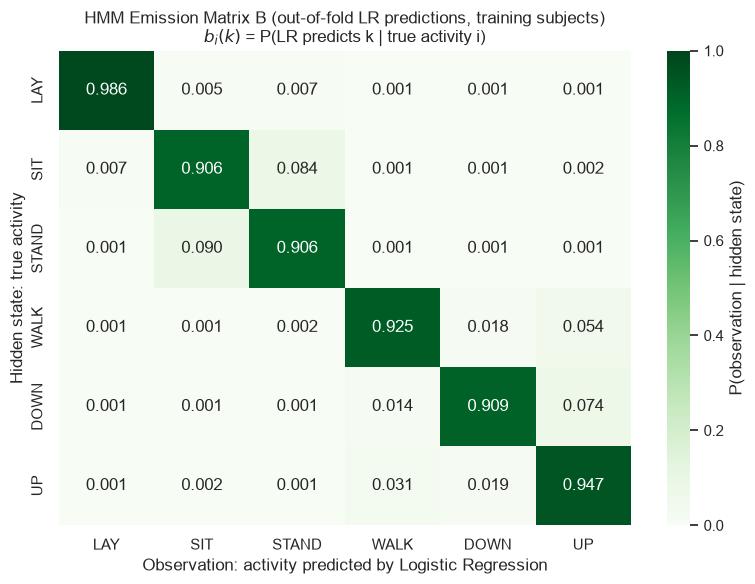

In [63]:
emission_counts = np.zeros((N_STATES, N_STATES))
np.add.at(emission_counts, (train_states, train_obs_oof), 1)
B = normalise_rows(emission_counts)
assert np.allclose(A.sum(axis=1), 1) and np.allclose(B.sum(axis=1), 1) and np.isclose(pi.sum(), 1)

plt.figure(figsize=(8, 6))
sns.heatmap(B, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1,
            xticklabels=short_names, yticklabels=short_names, cbar_kws={"label": "P(observation | hidden state)"})
plt.title("HMM Emission Matrix B (out-of-fold LR predictions, training subjects)\n$b_i(k)$ = P(LR predicts k | true activity i)")
plt.xlabel("Observation: activity predicted by Logistic Regression")
plt.ylabel("Hidden state: true activity")
plt.tight_layout()
plt.show()

**Reading B.** The diagonal is the classifier's per-class reliability. The largest off-diagonal entries are SIT ↔ STAND (≈ 0.08–0.09) and confusions between the three walking activities, the same weaknesses Module 1 found. Static and dynamic activities are almost never confused ($b \approx 0.001$), so the HMM mainly needs to fix confusions *within* the static group and *within* the dynamic group.

## 9. HMM Algorithms: Forward, Backward and Viterbi

All three algorithms use **dynamic programming**. Instead of enumerating all $N^T$ possible state paths (for $N=6$ and $T=300$ that is $6^{300}$), they reuse partial results and run in $O(T N^2)$ time.

### 9.1 Forward Algorithm: $P(O \mid \lambda)$

**Forward variable:** $\alpha_t(i) = P(o_1, \dots, o_t,\; q_t = i \mid \lambda)$, the probability of seeing the first $t$ observations and ending in state $i$.

| Step | Formula |
|---|---|
| Initialisation | $\alpha_1(i) = \pi_i \, b_i(o_1)$ |
| Recursion | $\alpha_{t+1}(j) = \Big[\sum_{i=1}^{N} \alpha_t(i)\, a_{ij}\Big]\, b_j(o_{t+1})$ |
| Termination | $P(O \mid \lambda) = \sum_{i=1}^{N} \alpha_T(i)$ |

**Numerical underflow and scaling.** $P(O\mid\lambda)$ is a product of hundreds of probabilities below 1. Even if every factor were 0.8, a 3000-step sequence would give $0.8^{3000} \approx 10^{-291}$, close to the smallest float64 value (about $10^{-308}$). Real factors are often much smaller, so unscaled $\alpha$ values become exactly 0. We therefore **normalise** $\alpha_t$ at every step by the scale factor $c_t = \sum_i \tilde\alpha_t(i)$ and recover the log-likelihood as
$$\log P(O \mid \lambda) = \sum_{t=1}^{T} \log c_t$$
The normalised $\hat\alpha_t(i)$ equals $P(q_t = i \mid o_1,\dots,o_t)$, the **filtered** probability of each activity given the observations so far. Its argmax is an *online* prediction.

In the code, `alpha[t-1] @ A` computes the bracketed sum for all $j$ at once (vectorised).

In [64]:
def forward(obs, pi, A, B):
    T, N = len(obs), len(pi)
    alpha, scale = np.zeros((T, N)), np.zeros(T)
    alpha[0] = pi * B[:, obs[0]]
    scale[0] = alpha[0].sum()
    alpha[0] /= scale[0]
    for t in range(1, T):
        alpha[t] = (alpha[t - 1] @ A) * B[:, obs[t]]
        scale[t] = alpha[t].sum()
        alpha[t] /= scale[t]
    return alpha, scale, np.log(scale).sum()

### 9.2 Backward Algorithm

**Backward variable:** $\beta_t(i) = P(o_{t+1}, \dots, o_T \mid q_t = i, \lambda)$, the probability of the **future** observations, given that we are in state $i$ at time $t$.

| Step | Formula |
|---|---|
| Initialisation | $\beta_T(i) = 1$ |
| Recursion (backwards, $t = T-1,\dots,1$) | $\beta_t(i) = \sum_{j=1}^{N} a_{ij}\, b_j(o_{t+1})\, \beta_{t+1}(j)$ |
| Termination | $P(O \mid \lambda) = \sum_{i} \pi_i\, b_i(o_1)\, \beta_1(i)$, the same value as Forward |

**Purpose.** Forward summarises the past and Backward summarises the future. Together they give the **posterior** probability of each state at each time, using the whole sequence:
$$\gamma_t(i) = P(q_t = i \mid O, \lambda) = \frac{\alpha_t(i)\,\beta_t(i)}{P(O \mid \lambda)}$$
$\arg\max_i \gamma_t(i)$ is *posterior decoding*. $\gamma$ is also the core quantity of Baum–Welch (unsupervised HMM training), which we do not need because our training labels are known.

**Scaling:** dividing $\beta_t$ by the *same* factors $c_{t+1}$ used in the Forward pass makes $\gamma_t(i) = \hat\alpha_t(i)\,\hat\beta_t(i)$ exactly.

In [65]:
def backward(obs, A, B, scale):
    T, N = len(obs), A.shape[0]
    beta = np.zeros((T, N))
    beta[-1] = 1.0
    for t in range(T - 2, -1, -1):
        beta[t] = A @ (B[:, obs[t + 1]] * beta[t + 1]) / scale[t + 1]
    return beta

def posterior(alpha, beta):
    return alpha * beta

### 9.3 Viterbi Algorithm: the Most Likely Hidden Activity Sequence

Viterbi finds the single best state path $Q^* = \arg\max_Q P(Q \mid O, \lambda)$. It has the same structure as Forward, with **max** in place of **sum**, and it records which predecessor achieved the maximum so the path can be traced back.

**Variables:** $\delta_t(j)$ is the probability of the best path that ends in state $j$ at time $t$. $\psi_t(j)$ is the best previous state on that path (a back-pointer).

| Step | Formula |
|---|---|
| Initialisation | $\delta_1(i) = \pi_i\, b_i(o_1)$, $\;\psi_1(i) = 0$ |
| Recursion | $\delta_t(j) = \max_i \big[\delta_{t-1}(i)\, a_{ij}\big]\, b_j(o_t)$, $\;\psi_t(j) = \arg\max_i \big[\delta_{t-1}(i)\, a_{ij}\big]$ |
| Termination | $P^* = \max_i \delta_T(i)$, $\;q_T^* = \arg\max_i \delta_T(i)$ |
| Backtracking | $q_t^* = \psi_{t+1}(q_{t+1}^*)$ for $t = T-1, \dots, 1$ |

To avoid underflow we work in **log space**: products become sums, and the max/argmax results are unchanged because $\log$ is monotonic.

**Viterbi vs posterior decoding.** Posterior decoding picks the best state at each time separately, so the resulting sequence can contain transitions that $A$ considers very unlikely. Viterbi picks the best *whole sequence*. The toy example below shows a case where the two disagree.

In [66]:
def viterbi(obs, pi, A, B):
    T, N = len(obs), len(pi)
    log_A, log_B = np.log(A), np.log(B)
    log_delta, psi = np.zeros((T, N)), np.zeros((T, N), dtype=int)
    log_delta[0] = np.log(pi) + log_B[:, obs[0]]
    for t in range(1, T):
        scores = log_delta[t - 1][:, None] + log_A
        psi[t] = scores.argmax(axis=0)
        log_delta[t] = scores.max(axis=0) + log_B[:, obs[t]]
    path = np.zeros(T, dtype=int)
    path[-1] = log_delta[-1].argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = psi[t, path[t]]
    return path, log_delta, psi, log_delta[-1].max()

### 9.4 Small Manually Verifiable Example

Two hidden states, **Static (S)** and **Moving (M)**. A noisy classifier outputs *still* or *moving*. Observed sequence: **O = (still, moving, still)**.

$$\pi = \begin{bmatrix}0.6 & 0.4\end{bmatrix},\quad
A = \begin{bmatrix}0.8 & 0.2\\ 0.3 & 0.7\end{bmatrix},\quad
B = \begin{bmatrix}0.9 & 0.1\\ 0.2 & 0.8\end{bmatrix}\;(\text{rows: S, M; columns: still, moving})$$

**Forward by hand**
- $t=1$: $\alpha_1(S) = 0.6 \times 0.9 = 0.54$, $\;\alpha_1(M) = 0.4 \times 0.2 = 0.08$
- $t=2$: $\alpha_2(S) = (0.54 \times 0.8 + 0.08 \times 0.3) \times 0.1 = 0.0456$, $\;\alpha_2(M) = (0.54 \times 0.2 + 0.08 \times 0.7) \times 0.8 = 0.1312$
- $t=3$: $\alpha_3(S) = (0.0456 \times 0.8 + 0.1312 \times 0.3) \times 0.9 = 0.068256$, $\;\alpha_3(M) = (0.0456 \times 0.2 + 0.1312 \times 0.7) \times 0.2 = 0.020192$
- **$P(O \mid \lambda) = 0.068256 + 0.020192 = 0.088448$**

**Backward by hand:** $\beta_3 = (1, 1)$; $\;\beta_2(S) = 0.8 \times 0.9 + 0.2 \times 0.2 = 0.76$, $\;\beta_2(M) = 0.3 \times 0.9 + 0.7 \times 0.2 = 0.41$; $\;\beta_1(S) = 0.8 \times 0.1 \times 0.76 + 0.2 \times 0.8 \times 0.41 = 0.1264$, $\;\beta_1(M) = 0.3 \times 0.1 \times 0.76 + 0.7 \times 0.8 \times 0.41 = 0.2524$. Check: $0.6 \times 0.9 \times 0.1264 + 0.4 \times 0.2 \times 0.2524 = 0.088448$ ✓

**Viterbi by hand**
- $t=1$: $\delta_1 = (0.54,\; 0.08)$
- $t=2$: $\delta_2(S) = \max(0.54 \times 0.8,\; 0.08 \times 0.3) \times 0.1 = 0.0432$ ($\psi$ = S); $\;\delta_2(M) = \max(0.54 \times 0.2,\; 0.08 \times 0.7) \times 0.8 = 0.0864$ ($\psi$ = S)
- $t=3$: $\delta_3(S) = \max(0.0432 \times 0.8,\; 0.0864 \times 0.3) \times 0.9 = 0.031104$ ($\psi$ = S); $\;\delta_3(M) = \max(0.0432 \times 0.2,\; 0.0864 \times 0.7) \times 0.2 = 0.012096$ ($\psi$ = M)
- Termination: best end state is S ($P^* = 0.031104$). Backtrack: $\psi_3(S) = S$, $\psi_2(S) = S$, giving **Q\* = (S, S, S)**

Viterbi treats the single *moving* observation as a classifier error, which is exactly the smoothing behaviour we want for HAR. The code below reproduces every number and checks Forward and Viterbi against brute-force enumeration of all $2^3 = 8$ paths.

In [67]:
from itertools import product

toy_states = ["Static", "Moving"]
toy_pi = np.array([0.6, 0.4])
toy_A = np.array([[0.8, 0.2], [0.3, 0.7]])
toy_B = np.array([[0.9, 0.1], [0.2, 0.8]])
toy_obs = np.array([0, 1, 0])

toy_alpha, toy_scale, toy_loglik = forward(toy_obs, toy_pi, toy_A, toy_B)
toy_beta = backward(toy_obs, toy_A, toy_B, toy_scale)
toy_gamma = posterior(toy_alpha, toy_beta)
toy_path, toy_log_delta, toy_psi, toy_log_best = viterbi(toy_obs, toy_pi, toy_A, toy_B)

alpha_unscaled = toy_alpha * np.cumprod(toy_scale)[:, None]
beta_unscaled = toy_beta * np.r_[np.cumprod(toy_scale[::-1])[::-1][1:], 1.0][:, None]

pd.DataFrame({
    "obs": ["still", "moving", "still"],
    "alpha(S)": alpha_unscaled[:, 0], "alpha(M)": alpha_unscaled[:, 1],
    "beta(S)": beta_unscaled[:, 0], "beta(M)": beta_unscaled[:, 1],
    "gamma(S)": toy_gamma[:, 0], "gamma(M)": toy_gamma[:, 1],
    "delta(S)": np.exp(toy_log_delta[:, 0]), "delta(M)": np.exp(toy_log_delta[:, 1]),
    "psi(S)": [None] + [toy_states[p] for p in toy_psi[1:, 0]],
    "psi(M)": [None] + [toy_states[p] for p in toy_psi[1:, 1]],
}, index=pd.Index([1, 2, 3], name="t")).round(6)

,obs,alpha(S),alpha(M),beta(S),beta(M),gamma(S),gamma(M),delta(S),delta(M),psi(S),psi(M)
t,,,,,,,,,,,
1,still,0.5400,0.0800,0.1264,0.2524,0.7717,0.2283,0.5400,0.0800,NaN,NaN
2,moving,0.0456,0.1312,0.7600,0.4100,0.3918,0.6082,0.0432,0.0864,Static,Static
3,still,0.0683,0.0202,1.0000,1.0000,0.7717,0.2283,0.0311,0.0121,Static,Moving


In [68]:
path_probs = {}
for path in product(range(2), repeat=len(toy_obs)):
    p = toy_pi[path[0]] * toy_B[path[0], toy_obs[0]]
    for t in range(1, len(toy_obs)):
        p *= toy_A[path[t - 1], path[t]] * toy_B[path[t], toy_obs[t]]
    path_probs[path] = p

assert np.isclose(np.exp(toy_loglik), 0.088448) and np.isclose(sum(path_probs.values()), np.exp(toy_loglik))
assert np.isclose((toy_pi * toy_B[:, toy_obs[0]] * beta_unscaled[0]).sum(), 0.088448)
assert tuple(toy_path) == max(path_probs, key=path_probs.get) and np.isclose(np.exp(toy_log_best), 0.031104)
assert np.allclose(toy_gamma.sum(axis=1), 1)

print(f"Forward   P(O|λ) = {np.exp(toy_loglik):.6f}  (sum over all 8 paths = {sum(path_probs.values()):.6f})")
print(f"Viterbi   best path = {[toy_states[s] for s in toy_path]}, P* = {np.exp(toy_log_best):.6f}")
print(f"Posterior decoding  = {[toy_states[s] for s in toy_gamma.argmax(axis=1)]}")
print("All hand calculations verified ✓")

Forward   P(O|λ) = 0.088448  (sum over all 8 paths = 0.088448)
Viterbi   best path = ['Static', 'Static', 'Static'], P* = 0.031104
Posterior decoding  = ['Static', 'Moving', 'Static']
All hand calculations verified ✓


**Interpretation of the toy result.** Viterbi returns (S, S, S), but posterior decoding returns (S, **M**, S), because $\gamma_2(M) = 0.608 > 0.5$. Each criterion is optimal for a different goal. Posterior decoding maximises the expected number of correct *individual* windows. Viterbi returns the most probable *whole sequence*, and (S, M, S) requires two fairly unlikely transitions. On HAR data we report both.

## 10. Applying the HMM to HAR: Comparative Analysis

**Observations:** the Module 1 Logistic Regression test predictions (`predictions["Logistic Regression"]`), unchanged.
**Parameters:** $\pi$, $A$, $B$ from Sections 7–8, estimated from training subjects only. Test labels are used **only** to score the outputs.
**Sequences:** each test subject stream (or verified segment) is decoded **separately**. Nothing is ever joined across subjects.

| # | Method | Uses | Real-time? |
|---|---|---|---|
| 1 | **Independent (LR)**, Module 1 | current window only | yes |
| 2 | **Markov chain**: $\hat q_t = \arg\max_j a_{\hat o_{t-1}, j}$ | only the previous window's LR prediction plus $A$; no current sensor evidence (first window: LR prediction) | yes |
| 3 | **HMM Forward (online filtering)**: $\arg\max_i \hat\alpha_t(i)$ | observations $o_1..o_t$ | yes |
| 4 | **HMM Forward–Backward (posterior)**: $\arg\max_i \gamma_t(i)$ | the whole sequence $o_1..o_T$ | no (offline) |
| 5 | **HMM Viterbi**: best whole path | the whole sequence $o_1..o_T$ | no (offline) |

Methods 4–5 look at *future predictions* of the same test sequence. This is not label leakage, but it means they are offline smoothers. A live system would use method 3 or a short fixed delay.

**Sequence-level metrics** in addition to the window-level metrics: *Activity changes predicted* counts how often the predicted label switches, compared with the true number of changes (fragmentation). *Errors fixed* and *new errors* count windows that the method corrected, or broke, relative to LR.

In [69]:
METHODS = ["Independent (LR)", "Markov chain", "HMM Forward (online)", "HMM Forward-Backward", "HMM Viterbi"]
test_obs = pd.Series(predictions["Logistic Regression"]).map(state_index).to_numpy()

def decode_sequences(sequences, obs, pi, A, B):
    decoded = {name: np.full(len(obs), -1) for name in METHODS}
    for idx in sequences:
        o = obs[idx]
        alpha, scale, _ = forward(o, pi, A, B)
        beta = backward(o, A, B, scale)
        decoded["Independent (LR)"][idx] = o
        decoded["Markov chain"][idx] = np.r_[o[0], A[o[:-1]].argmax(axis=1)]
        decoded["HMM Forward (online)"][idx] = alpha.argmax(axis=1)
        decoded["HMM Forward-Backward"][idx] = posterior(alpha, beta).argmax(axis=1)
        decoded["HMM Viterbi"][idx] = viterbi(o, pi, A, B)[0]
    assert all((pred >= 0).all() for pred in decoded.values())
    return decoded

def evaluate_methods(decoded, sequences, y_true, baseline):
    rows = {}
    for name, pred in decoded.items():
        rows[name] = {
            "Accuracy": accuracy_score(y_true, pred),
            "Precision (macro)": precision_score(y_true, pred, average="macro"),
            "Recall (macro)": recall_score(y_true, pred, average="macro"),
            "F1-score (macro)": f1_score(y_true, pred, average="macro"),
            "Activity changes predicted": sum(int((np.diff(pred[idx]) != 0).sum()) for idx in sequences),
            "Errors fixed vs LR": int(((pred == y_true) & (baseline != y_true)).sum()),
            "New errors vs LR": int(((pred != y_true) & (baseline == y_true)).sum()),
        }
    table = pd.DataFrame(rows).T
    count_columns = ["Activity changes predicted", "Errors fixed vs LR", "New errors vs LR"]
    return table.astype({c: int for c in count_columns})

def true_changes(sequences, y_true):
    return sum(int((np.diff(y_true[idx]) != 0).sum()) for idx in sequences)

### 10.1 Primary Evaluation: Test Subject Streams

In [70]:
stream_decoded = decode_sequences(test_streams, test_obs, pi, A, B)
stream_results = evaluate_methods(stream_decoded, test_streams, test_states, test_obs)
print(f"{len(test_streams)} test subject streams, {len(test_obs)} windows, true activity changes = {true_changes(test_streams, test_states)}")
stream_results.round(4)

9 test subject streams, 2947 windows, true activity changes = 111


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Activity changes predicted,Errors fixed vs LR,New errors vs LR
Independent (LR),0.9535,0.9563,0.9520,0.9532,240,0,0
Markov chain,0.9182,0.9202,0.9158,0.9169,239,65,169
HMM Forward (online),0.9535,0.9550,0.9515,0.9522,157,60,60
HMM Forward-Backward,0.9701,0.9725,0.9690,0.9700,121,67,18
HMM Viterbi,0.9701,0.9725,0.9690,0.9700,121,67,18


### 10.2 Strict Evaluation: Overlap-Verified Segments Only

The same parameters and observations, but each overlap-verified segment is decoded as its own sequence. Every step is a proven 1.28 s step. Because each segment contains one activity (true activity changes = 0), this measures **pure noise smoothing**: it cannot test whether real activity changes are detected.

In [71]:
segment_decoded = decode_sequences(test_segments, test_obs, pi, A, B)
segment_results = evaluate_methods(segment_decoded, test_segments, test_states, test_obs)
print(f"{len(test_segments)} verified segments, true activity changes = {true_changes(test_segments, test_states)}")
segment_results.round(4)

257 verified segments, true activity changes = 0


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Activity changes predicted,Errors fixed vs LR,New errors vs LR
Independent (LR),0.9535,0.9563,0.9520,0.9532,124,0,0
Markov chain,0.9539,0.9564,0.9522,0.9534,108,61,60
HMM Forward (online),0.9535,0.9588,0.9521,0.9534,90,50,50
HMM Forward-Backward,0.9684,0.9713,0.9673,0.9684,17,65,21
HMM Viterbi,0.9678,0.9708,0.9666,0.9677,17,64,22


### 10.3 Robustness Check: Is the Gain from Protocol Knowledge or from Persistence?

$A$ contains two kinds of knowledge: **persistence** (the diagonal) and the **scripted protocol order** (the off-diagonal pattern, e.g. SIT → LAY). Test subjects followed the same script, so the second kind could flatter the HMM. We rebuild $A$ keeping only the learned diagonal and spreading the leaving probability **uniformly** over the other 5 activities. This model knows *how long* activities last but not *which* activity comes next.

In [72]:
self_prob = np.diag(A)
A_persistence = np.where(np.eye(N_STATES, dtype=bool), self_prob[:, None], ((1 - self_prob) / (N_STATES - 1))[:, None])
pi_uniform = np.full(N_STATES, 1 / N_STATES)
assert np.allclose(A_persistence.sum(axis=1), 1)

persistence_pred = np.full(len(test_obs), -1)
for idx in test_streams:
    persistence_pred[idx] = viterbi(test_obs[idx], pi_uniform, A_persistence, B)[0]

robustness = evaluate_methods({"Independent (LR)": test_obs,
                               "HMM Viterbi (full A, learned π)": stream_decoded["HMM Viterbi"],
                               "HMM Viterbi (persistence-only A, uniform π)": persistence_pred}, test_streams,
                              test_states, test_obs)
robustness.round(4)

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Activity changes predicted,Errors fixed vs LR,New errors vs LR
Independent (LR),0.9535,0.9563,0.9520,0.9532,240,0,0
"HMM Viterbi (full A, learned π)",0.9701,0.9725,0.9690,0.9700,121,67,18
"HMM Viterbi (persistence-only A, uniform π)",0.9688,0.9711,0.9675,0.9685,120,65,20


### 10.4 Which Activities Benefit? (Per-class Results, Subject Streams)

In [73]:
lr_pred, vit_pred = stream_decoded["Independent (LR)"], stream_decoded["HMM Viterbi"]
per_class = pd.DataFrame({
    "Recall LR": recall_score(test_states, lr_pred, average=None),
    "Recall Viterbi": recall_score(test_states, vit_pred, average=None),
    "F1 LR": f1_score(test_states, lr_pred, average=None),
    "F1 Viterbi": f1_score(test_states, vit_pred, average=None),
}, index=activity_classes)
per_class["F1 change"] = per_class["F1 Viterbi"] - per_class["F1 LR"]
per_class.sort_values("F1 change", ascending=False).round(4)

,Recall LR,Recall Viterbi,F1 LR,F1 Viterbi,F1 change
SITTING,0.8758,0.9124,0.9188,0.9532,0.0344
STANDING,0.9718,0.9981,0.9290,0.9593,0.0303
WALKING_DOWNSTAIRS,0.9333,0.9667,0.9608,0.9819,0.0211
WALKING_UPSTAIRS,0.9448,0.9427,0.9488,0.9569,0.0081
WALKING,0.9940,1.0000,0.9667,0.9716,0.0049
LAYING,0.9926,0.9944,0.9953,0.9972,0.0019


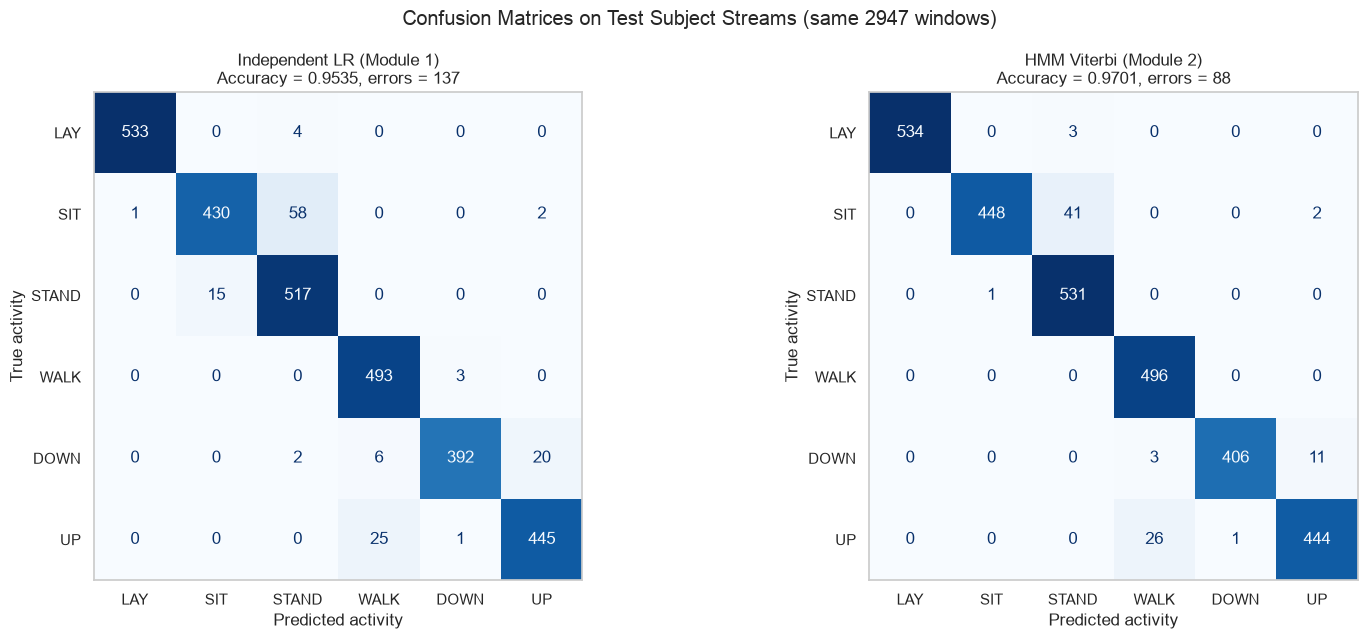

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (title, pred) in zip(axes, [("Independent LR (Module 1)", lr_pred), ("HMM Viterbi (Module 2)", vit_pred)]):
    cm = confusion_matrix(test_states, pred, labels=range(N_STATES))
    ConfusionMatrixDisplay(cm, display_labels=short_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title}\nAccuracy = {accuracy_score(test_states, pred):.4f}, errors = {(pred != test_states).sum()}")
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("True activity")
    ax.grid(False)
plt.suptitle("Confusion Matrices on Test Subject Streams (same 2947 windows)")
plt.tight_layout()
plt.show()

**Why do some errors survive?** We group LR errors into *runs* of consecutive wrong windows inside a stream and measure how many of them Viterbi corrects, by run length.

In [75]:
run_rows = []
for idx in test_streams:
    wrong = test_obs[idx] != test_states[idx]
    run_id = np.cumsum(np.r_[True, wrong[1:] != wrong[:-1]])
    for r in np.unique(run_id[wrong]):
        members = idx[run_id == r]
        run_rows.append({"Run length": len(members),
                         "Windows fixed": int((vit_pred[members] == test_states[members]).sum())})
error_runs = pd.DataFrame(run_rows)
error_runs["Run length group"] = pd.cut(error_runs["Run length"], [0, 1, 2, 4, np.inf], labels=["1", "2", "3-4", "5+"])
run_summary = error_runs.groupby("Run length group", observed=True).agg(
    Error_runs=("Run length", "size"), LR_error_windows=("Run length", "sum"), Fixed_by_Viterbi=("Windows fixed", "sum"))
run_summary["Share fixed"] = (run_summary["Fixed_by_Viterbi"] / run_summary["LR_error_windows"]).round(3)
run_summary

,Error_runs,LR_error_windows,Fixed_by_Viterbi,Share fixed
Run length group,,,,
1,46,46,39,0.848
2,14,28,22,0.786
3-4,8,28,6,0.214
5+,5,35,0,0.000


### 10.5 Actual vs Predicted Activity Sequences

We plot the test subject with the **most LR errors**. This rule is fixed in advance and does not depend on the HMM result, so the plot shows where smoothing has the most to do, whether it helps or not. Grey dotted lines mark the gaps where overlap continuity breaks. The x-axis is window position in the stream, not exact clock time.

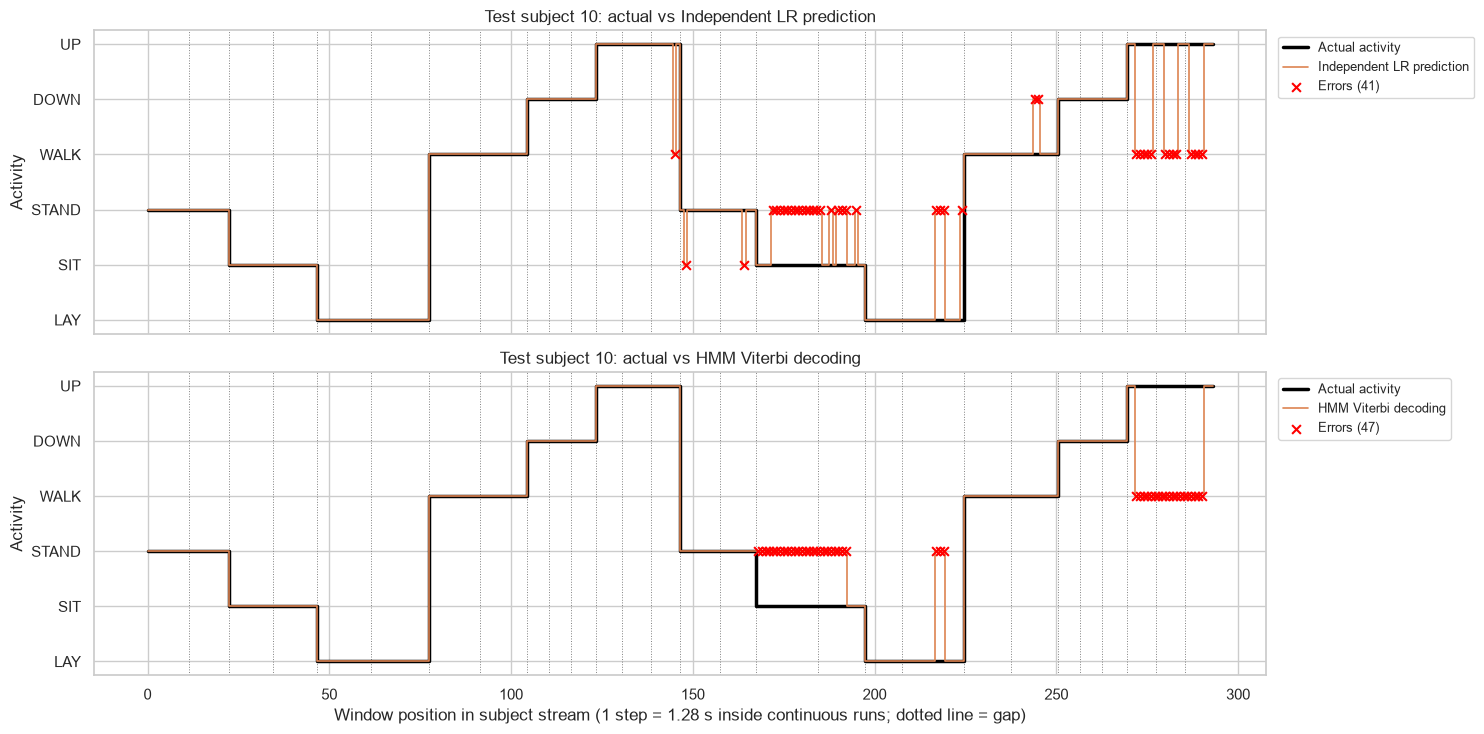

In [76]:
example_idx = max(test_streams, key=lambda idx: (test_obs[idx] != test_states[idx]).sum())
example_subject = test_subjects[example_idx[0]]
positions = np.arange(len(example_idx))
gap_positions = np.flatnonzero(~test_continuous[example_idx[:-1]]) + 0.5

fig, axes = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)
for ax, (name, pred) in zip(axes, [("Independent LR prediction", lr_pred), ("HMM Viterbi decoding", vit_pred)]):
    truth, guess = test_states[example_idx], pred[example_idx]
    for g in gap_positions:
        ax.axvline(g, color="grey", linestyle=":", linewidth=0.7)
    ax.step(positions, truth, where="mid", color="black", linewidth=2.5, label="Actual activity")
    ax.step(positions, guess, where="mid", color="#DD8452", linewidth=1.2, label=name)
    wrong = guess != truth
    ax.scatter(positions[wrong], guess[wrong], color="red", marker="x", s=40, zorder=3,
               label=f"Errors ({wrong.sum()})")
    ax.set_yticks(range(N_STATES), short_names)
    ax.set_ylabel("Activity")
    ax.set_title(f"Test subject {example_subject}: actual vs {name}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9)
axes[1].set_xlabel("Window position in subject stream (1 step = 1.28 s inside continuous runs; dotted line = gap)")
plt.tight_layout()
plt.show()

### 10.6 Model Comparison Chart

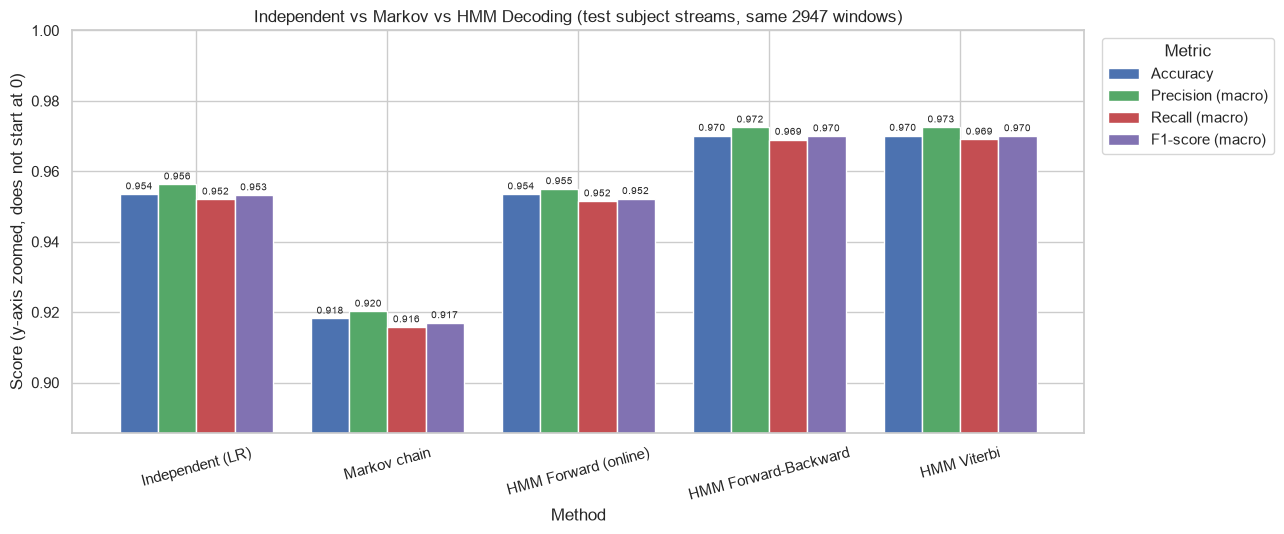

In [77]:
main_metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
ax = stream_results[main_metrics].plot(kind="bar", figsize=(13, 5.5), width=0.8,
                                       color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.set_ylim(max(0, stream_results[main_metrics].min().min() - 0.03), 1.0)
ax.set_title("Independent vs Markov vs HMM Decoding (test subject streams, same 2947 windows)")
ax.set_xlabel("Method")
ax.set_ylabel("Score (y-axis zoomed, does not start at 0)")
ax.legend(title="Metric", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2)
plt.tight_layout()
plt.show()

### 10.7 Using the Forward Probability: Does Temporal Order Matter?

$\log P(O \mid \lambda)$ from the Forward algorithm measures how well the HMM explains an observation sequence. If the model has learned real temporal structure, each test subject's real prediction sequence should be **far more likely** than the same predictions in a random order. The two versions have identical label counts, so only the order differs. The shuffle uses a fixed seed.

In [78]:
rng = np.random.default_rng(RANDOM_STATE)
likelihood_rows = []
for idx in test_streams:
    obs = test_obs[idx]
    real_ll = forward(obs, pi, A, B)[2]
    shuffled_ll = forward(rng.permutation(obs), pi, A, B)[2]
    likelihood_rows.append({"Subject": test_subjects[idx[0]], "Windows": len(obs),
                            "log P(O|λ) real order": real_ll, "log P(O|λ) shuffled": shuffled_ll,
                            "Real per window": real_ll / len(obs), "Shuffled per window": shuffled_ll / len(obs)})
pd.DataFrame(likelihood_rows).set_index("Subject").round(2)

,Windows,log P(O|λ) real order,log P(O|λ) shuffled,Real per window,Shuffled per window
Subject,,,,,
2,302,-77.05,-1059.62,-0.26,-3.51
4,317,-102.48,-1060.35,-0.32,-3.34
9,288,-150.28,-964.66,-0.52,-3.35
10,294,-151.89,-1011.68,-0.52,-3.44
12,320,-119.83,-1109.86,-0.37,-3.47
13,327,-80.50,-1119.48,-0.25,-3.42
18,364,-124.39,-1192.22,-0.34,-3.28
20,354,-108.29,-1214.50,-0.31,-3.43
24,381,-88.13,-1315.43,-0.23,-3.45


### 10.8 Discussion of the Comparative Analysis

All numbers below come from the outputs above. The same 2947 test windows and the same LR observations are used for every method.

**Does temporal smoothing help?** Yes, for the offline HMM decoders. On the subject streams, Viterbi raises accuracy from **0.9535 to 0.9701** and macro F1 from **0.9532 to 0.9700**, reducing errors from **137 to 88** (67 fixed, 18 new). It also reduces fragmentation: LR switches activity 240 times where the truth switches 111 times, and Viterbi switches 121 times. The strict verified-segment evaluation gives the same picture: accuracy 0.9678, and predicted switches fall from 124 to 17 when the true number is 0. So the gain is not caused by the gaps between segments.

**It is not uniformly better.**
- *Markov chain alone is worse* (0.9182). Every row of $A$ has its maximum on the diagonal, so it just repeats the previous LR prediction. It ignores the current sensor evidence and is wrong one window after every real change (113 of its 169 new errors are within 2 windows of a true change).
- *Online Forward filtering has no net gain* (0.9535: 60 fixed, 60 new). It removes isolated errors but, without future evidence, lags behind real activity changes (46 of its 60 new errors are next to a true change).
- *Long error runs are never fixed.* Viterbi fixes 85 % of single-window errors and 79 % of 2-window errors, but only 21 % of 3–4-window runs and **0 % of runs of 5 or more**. When the classifier is consistently wrong, the HMM has no evidence to correct it.
- *Smoothing can amplify systematic errors.* For test subject 10, Viterbi has **47 errors vs 41 for LR**. That subject's sitting block is mostly predicted as STANDING, so the HMM labels the whole block STANDING. WALKING_UPSTAIRS → WALKING errors also rose slightly (25 → 26).

**Which activities benefit?** SITTING (F1 +0.034) and STANDING (+0.030) gain the most, followed by WALKING_DOWNSTAIRS (+0.021). These are the classes LR confuses with a neighbour that has similar sensor signals. LAYING (+0.002) and WALKING (+0.005) were already near-perfect, so there was little to gain.

**Which confusions remain?** SITTING → STANDING (41 windows) and WALKING_UPSTAIRS → WALKING (26). Both mostly occur in long runs, where temporal context cannot help. Better features or a better classifier would be needed.

**Protocol knowledge vs persistence.** A persistence-only $A$ with uniform off-diagonals and uniform $\pi$ still reaches 0.9688. So about 1.5 of the 1.66 accuracy points come from the simple fact that activities persist, and only a small part from memorising the scripted activity order. This matters because the scripted order would not hold in daily life.

**Forward probability as a sanity check.** Each test subject's real prediction sequence has a log-likelihood of about −0.2 to −0.5 per window, against about −3.3 to −3.5 when the same predictions are shuffled. The HMM has captured genuine temporal structure.

**Posterior (Forward–Backward) vs Viterbi.** On HAR they give almost identical results (0.9701 vs 0.9701 on streams). Their difference shows up only in small ambiguous cases like the toy example.

### 10.9 Extension: Soft Emissions from Class Probabilities

So far the HMM observes only the **hard label** predicted by Logistic Regression, so a window predicted SITTING with
probability 0.51 counts exactly as much as one predicted with 0.99. A **hybrid HMM** keeps that confidence by using the
classifier's class probabilities as emissions. By Bayes' rule

$$b_i(x_t) = p(x_t \mid q_t = i) = \frac{P(q_t = i \mid x_t)\, p(x_t)}{P(q_t = i)} \;\propto\; \frac{P(q_t = i \mid x_t)}{P(q_t = i)},$$

where $P(q_t=i \mid x_t)$ is the LR probability and $P(q_t=i)$ the training class frequency. The factor $p(x_t)$ is the
same for every state at time $t$, so it rescales $\alpha_t$ and $\delta_t$ but never changes Forward–Backward or Viterbi
decisions.

**Tempering.** LR is over-confident (99.6 % accuracy on its own training rows), so we use
$b_i(x_t) \propto \big[P(q_t=i \mid x_t)/P(q_t=i)\big]^{\tau}$ with $0 < \tau \le 1$. A small $\tau$ trusts the
classifier less and the transition matrix more; $\tau = 1$ is the plain hybrid HMM.

**No leakage.** $\tau$ is chosen on the **training subjects** with **out-of-fold** probabilities (5-fold `GroupKFold`
by subject, as for $B$ in Section 8), by Viterbi accuracy on the training streams. $\pi$ and $A$ are the Section 7
estimates. The test probabilities come from the Module 1 LR model and are scored once.

**Implementation.** For a sequence of length $T$ we build an $N \times T$ emission matrix $E$ whose column $t$ is the
emission vector of window $t$, and pass observations $o_t = t$. The verified `forward`, `backward`, `posterior` and
`viterbi` functions of Section 9 are then reused unchanged.

> **Run note.** The outputs of this subsection come from a separate run of §1–§10 (scikit-learn 1.9.1, NumPy 2.5.3, Linux), in which the baseline Logistic Regression scored 0.9549 instead of the 0.9535 shown in §4 (platform-level numerical differences in the L-BFGS solver; scikit-learn 1.7–1.9 all give 0.9549 there). Every number inside this subsection, including the hard-label rows, comes from that same run, so the comparison is internally consistent. Re-running the notebook from the top makes all sections consistent on your machine.

In [ ]:
assert list(trained_models["Logistic Regression"].classes_) == activity_classes
oof_train_proba = cross_val_predict(clone(log_reg_model), X_train, y_train, groups=train_subjects,
                                    cv=GroupKFold(n_splits=5), method="predict_proba", n_jobs=1)
test_proba = trained_models["Logistic Regression"].predict_proba(X_test)
class_prior = np.bincount(train_states, minlength=N_STATES) / len(train_states)
assert np.allclose(oof_train_proba.sum(axis=1), 1) and np.allclose(test_proba.sum(axis=1), 1)

def soft_emissions(proba, tau):
    """N x T matrix: column t is proportional to [P(state | x_t) / P(state)] ** tau."""
    scaled = (np.clip(proba, 1e-12, 1.0) / class_prior) ** tau
    return (scaled / scaled.sum(axis=1, keepdims=True)).T   # per-window rescaling does not change decoding

SOFT_METHODS = ["HMM Forward (soft)", "HMM Forward-Backward (soft)", "HMM Viterbi (soft)"]

def decode_soft(sequences, proba, tau, pi, A):
    decoded = {name: np.full(len(proba), -1) for name in SOFT_METHODS}
    for idx in sequences:
        E, steps = soft_emissions(proba[idx], tau), np.arange(len(idx))
        alpha, scale, _ = forward(steps, pi, A, E)
        beta = backward(steps, A, E, scale)
        decoded["HMM Forward (soft)"][idx] = alpha.argmax(axis=1)
        decoded["HMM Forward-Backward (soft)"][idx] = posterior(alpha, beta).argmax(axis=1)
        decoded["HMM Viterbi (soft)"][idx] = viterbi(steps, pi, A, E)[0]
    assert all((pred >= 0).all() for pred in decoded.values())
    return decoded

# choose tau on TRAINING subjects only (out-of-fold probabilities)
TAUS = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
tau_rows = []
for tau in TAUS:
    d = decode_soft(train_streams, oof_train_proba, tau, pi, A)
    tau_rows.append({"tau": tau, **{f"Train acc. {m.replace(' (soft)', '')}": accuracy_score(train_states, d[m])
                                    for m in SOFT_METHODS}})
tau_table = pd.DataFrame(tau_rows).set_index("tau")
best_tau = float(tau_table["Train acc. HMM Viterbi"].idxmax())
print(f"Out-of-fold LR accuracy on training subjects: {accuracy_score(train_states, oof_train_proba.argmax(axis=1)):.4f}")
print(f"Chosen tau = {best_tau} (highest Viterbi accuracy on the training streams)")
tau_table.round(4)

Out-of-fold LR accuracy on training subjects: 0.9348
Chosen tau = 0.5 (highest Viterbi accuracy on the training streams)


,Train acc. HMM Forward,Train acc. HMM Forward-Backward,Train acc. HMM Viterbi
tau,,,
0.05,0.8702,0.9418,0.9452
0.10,0.9083,0.9551,0.9566
0.20,0.9376,0.9581,0.9607
0.30,0.9497,0.9595,0.9607
0.50,0.9546,0.9604,0.9611
0.70,0.9544,0.9580,0.9582
1.00,0.9539,0.9591,0.9591


In [ ]:
soft_decoded = decode_soft(test_streams, test_proba, best_tau, pi, A)
compare = {name: stream_decoded[name] for name in ["Independent (LR)", "HMM Forward (online)",
                                                    "HMM Forward-Backward", "HMM Viterbi"]}
compare = {**compare, **soft_decoded}
soft_results = evaluate_methods(compare, test_streams, test_states, test_obs)
soft_results.index = [n if "soft" in n or n.startswith("Independent") else n + " (hard)" for n in soft_results.index]
print(f"Test subject streams: {len(test_obs)} windows, true activity changes = {true_changes(test_streams, test_states)}, tau = {best_tau}")
soft_results.round(4)

Test subject streams: 2947 windows, true activity changes = 111, tau = 0.5


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Activity changes predicted,Errors fixed vs LR,New errors vs LR
Independent (LR),0.9549,0.9580,0.9536,0.9548,245,0,0
HMM Forward (online) (hard),0.9549,0.9566,0.9532,0.9539,160,62,62
HMM Forward-Backward (hard),0.9722,0.9747,0.9714,0.9723,122,69,18
HMM Viterbi (hard),0.9722,0.9747,0.9714,0.9724,119,70,19
HMM Forward (soft),0.9718,0.9729,0.9705,0.9711,122,91,41
HMM Forward-Backward (soft),0.9824,0.9839,0.9816,0.9823,113,95,14
HMM Viterbi (soft),0.9830,0.9847,0.9824,0.9831,112,94,11


In [ ]:
soft_vit = soft_decoded["HMM Viterbi (soft)"]

# which error runs of the LR classifier does each decoder fix?
run_rows = []
for idx in test_streams:
    wrong = test_obs[idx] != test_states[idx]
    run_id = np.cumsum(np.r_[True, wrong[1:] != wrong[:-1]])
    for r in np.unique(run_id[wrong]):
        members = idx[run_id == r]
        run_rows.append({"Run length": len(members),
                         "Fixed (hard Viterbi)": int((vit_pred[members] == test_states[members]).sum()),
                         "Fixed (soft Viterbi)": int((soft_vit[members] == test_states[members]).sum())})
runs = pd.DataFrame(run_rows)
runs["Run length group"] = pd.cut(runs["Run length"], [0, 1, 2, 4, np.inf], labels=["1", "2", "3-4", "5+"])
run_cmp = runs.groupby("Run length group", observed=True).agg(LR_error_windows=("Run length", "sum"),
                                                              Fixed_hard=("Fixed (hard Viterbi)", "sum"),
                                                              Fixed_soft=("Fixed (soft Viterbi)", "sum"))
display(run_cmp)

per_class_soft = pd.DataFrame({
    "F1 LR": f1_score(test_states, lr_pred, average=None),
    "F1 Viterbi (hard)": f1_score(test_states, vit_pred, average=None),
    "F1 Viterbi (soft)": f1_score(test_states, soft_vit, average=None),
}, index=activity_classes)
per_class_soft["Soft - hard"] = per_class_soft["F1 Viterbi (soft)"] - per_class_soft["F1 Viterbi (hard)"]
display(per_class_soft.round(4))

subject_rows = []
for idx in test_streams:
    subject_rows.append({"Subject": test_subjects[idx[0]],
                         "Errors LR": int((test_obs[idx] != test_states[idx]).sum()),
                         "Errors Viterbi (hard)": int((vit_pred[idx] != test_states[idx]).sum()),
                         "Errors Viterbi (soft)": int((soft_vit[idx] != test_states[idx]).sum())})
pd.DataFrame(subject_rows).set_index("Subject")

,LR_error_windows,Fixed_hard,Fixed_soft
Run length group,,,
1,46,38,41
2,34,26,30
3-4,29,6,23
5+,24,0,0


,F1 LR,F1 Viterbi (hard),F1 Viterbi (soft),Soft - hard
LAYING,0.9925,0.9925,1.0000,0.0075
SITTING,0.9208,0.9565,0.9587,0.0022
STANDING,0.9284,0.9559,0.9646,0.0087
WALKING,0.9686,0.9783,0.9970,0.0187
WALKING_DOWNSTAIRS,0.9646,0.9831,0.9867,0.0036
WALKING_UPSTAIRS,0.9541,0.9678,0.9916,0.0238


,Errors LR,Errors Viterbi (hard),Errors Viterbi (soft)
Subject,,,
2,3,2,0
4,12,0,0
9,25,12,4
10,42,45,25
12,18,5,5
13,3,3,3
18,13,7,8
20,15,7,4
24,2,1,1


**Interpretation (numbers from the tables above; same 2947 test windows, same run).**

* **$\tau$ = 0.5 was chosen on training subjects.** Training Viterbi accuracy peaks at 0.9611 for $\tau = 0.5$. Very
  small $\tau$ under-uses the classifier (0.9452 at $\tau = 0.05$), and $\tau = 1$ trusts its over-confident
  probabilities slightly too much (0.9591).
* **Soft emissions are clearly better.** Viterbi errors fall from **133 (LR) → 82 (hard HMM) → 50 (soft HMM)**:
  accuracy 0.9549 → 0.9722 → **0.9830**, macro-F1 0.9548 → 0.9724 → **0.9831**. Soft Viterbi also creates fewer new
  errors than hard Viterbi (11 vs 19) and predicts 112 activity changes against 111 true ones.
* **The online filter becomes useful.** With hard labels, Forward filtering has no net gain (62 fixed, 62 new). With
  soft emissions it reaches 0.9718 in real time, almost the hard *offline* Viterbi result, because a low-confidence
  window no longer forces a switch.
* **Medium error runs are now fixable.** Errors in runs of 3–4 windows: 23 of 29 windows fixed (hard: 6 of 29), because
  the decoder can see that those windows were predicted with low confidence. Runs of 5 or more are still never fixed
  (0 of 24): there the classifier is confidently wrong.
* **Subject 10**, where hard smoothing made things worse (42 → 45 errors), improves to 25 errors.
* **Limitations.** $\tau$ is a single global value chosen on scripted training streams; there is one 9-subject test
  set; and the HAPT version (§11) was not re-run with soft emissions because the HAPT files are not part of this
  repository.

## 11. Validated Temporal Evaluation on Continuous Recordings (HAPT Dataset)

Section 6 showed the main weakness of UCI HAR v1 for temporal modelling: the transitions between activities were removed, so every activity change crosses a gap. The **HAPT dataset** (*Smartphone-Based Recognition of Human Activities and Postural Transitions*, UCI v2.1) comes from the **same experiment**: the same 30 volunteers, the same phone, the same 2.56 s / 50 %-overlap windows and the same 561 features. It adds:

- `RawData/labels.txt`: for each of 61 continuous recordings (*experiments*), every labelled interval as `(experiment, user, activity, start_sample, end_sample)` at 50 Hz;
- six labelled **postural transitions**: STAND_TO_SIT, SIT_TO_STAND, SIT_TO_LIE, LIE_TO_SIT, STAND_TO_LIE, LIE_TO_STAND.

**Reconstructing time order.** The official `X_train.txt` / `X_test.txt` rows contain no timestamps, but they can be mapped back to the recordings exactly. Take the labelled intervals in file order. An interval of $L$ samples yields $\lfloor (L-128)/64 \rfloor + 1$ windows lying fully inside it, starting every 64 samples. The code below rebuilds this table and **asserts** that it reproduces the official activity label and subject ID of every row. A new sequence starts at each new experiment, and wherever unlabelled samples separate two intervals. Sequences therefore never cross experiments, subjects or unlabelled gaps.

**Split.** HAPT uses exactly the same 9 test subjects as Module 1 ({2, 4, 9, 10, 12, 13, 18, 20, 24}), checked below. All parameters are again estimated from training subjects only.

In [79]:
HAPT_DIR = Path("../data/external") / "smartphone+based+recognition+of+human+activities+and+postural+transitions"
WINDOW, HOP = 128, 64

hapt_intervals = pd.read_csv(HAPT_DIR / "RawData" / "labels.txt", sep=r"\s+", header=None,
                             names=["exp", "user", "act", "start", "end"])

def hapt_window_table(split):
    subjects = np.loadtxt(HAPT_DIR / split.title() / f"subject_id_{split}.txt", dtype=int)
    labels = np.loadtxt(HAPT_DIR / split.title() / f"y_{split}.txt", dtype=int)
    intervals = hapt_intervals[hapt_intervals["user"].isin(set(subjects))]
    rows = []
    for interval_id, r in intervals.iterrows():
        n_windows = max((r.end - r.start + 1 - WINDOW) // HOP + 1, 0)
        rows += [(r.exp, r.user, r.act, interval_id, r.start - 1 + k * HOP) for k in range(n_windows)]
    table = pd.DataFrame(rows, columns=["exp", "user", "act", "interval", "win_start"])
    assert len(table) == len(labels) and (table["act"].to_numpy() == labels).all(), "label mapping failed"
    assert (table["user"].to_numpy() == subjects).all() and table["exp"].is_monotonic_increasing

    prev_interval = table["interval"].shift().fillna(-1).astype(int).to_numpy()
    this_interval = table["interval"].to_numpy()
    starts_right_after = (hapt_intervals.loc[this_interval, "start"].to_numpy()
                          == hapt_intervals["end"].reindex(prev_interval).to_numpy() + 1)
    continues = (this_interval == prev_interval) | ((this_interval == prev_interval + 1) & starts_right_after)
    table["new_sequence"] = (table["exp"] != table["exp"].shift()).to_numpy() | ~continues
    return table

hapt_train_table, hapt_test_table = hapt_window_table("train"), hapt_window_table("test")
assert set(hapt_test_table["user"]) == set(test_subjects) and set(hapt_train_table["user"]) == set(train_subjects)
print("Every official HAPT row mapped to (experiment, time) and matched to its official label and subject ✓")
print(f"Train: {len(hapt_train_table)} windows, {hapt_train_table['exp'].nunique()} recordings | "
      f"Test: {len(hapt_test_table)} windows, {hapt_test_table['exp'].nunique()} recordings")

Every official HAPT row mapped to (experiment, time) and matched to its official label and subject ✓
Train: 7767 windows, 42 recordings | Test: 3162 windows, 19 recordings


In [80]:
def load_hapt_features(split):
    return pd.read_csv(HAPT_DIR / split.title() / f"X_{split}.txt", sep=r"\s+", header=None).to_numpy()

X_hapt_train, X_hapt_test = load_hapt_features("train"), load_hapt_features("test")
assert X_hapt_train.shape == (len(hapt_train_table), 561) and X_hapt_test.shape == (len(hapt_test_table), 561)
print("HAPT feature matrices:", X_hapt_train.shape, X_hapt_test.shape)

HAPT feature matrices: (7767, 561) (3162, 561)


### 11.1 State Space and Sequences

The six transitions are short (typically 1–2 windows) and rare: SIT_TO_STAND has only 23 training windows. Estimating separate rows of $A$ and $B$ for each of them would be unreliable, so we use **7 hidden states**: the six activities plus one merged **TRANSITION** state. This keeps every activity change inside the sequences, because the recordings never go directly from one posture to another without a labelled transition. (A separate 12-state prototype, built on different, simpler features, gave no clear advantage. That number is not reproduced here, so it is not used as evidence.)

**Time step caveat.** Inside an interval, consecutive windows are exactly 64 samples (1.28 s) apart. Where one labelled interval follows directly after another, the next window starts after the previous one ends. The table below measures this step at 128–191 samples (2.56–3.8 s). This is a small irregularity, and we accept it so that sequences contain real changes.

In [81]:
HAPT_STATES = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING", "TRANSITION"]
HAPT_SHORT = ["WALK", "UP", "DOWN", "SIT", "STAND", "LAY", "TRANS"]
N_HAPT = len(HAPT_STATES)

def to_hapt_states(activity_ids):
    return np.minimum(np.asarray(activity_ids), 7) - 1

def table_to_sequences(table):
    return np.split(np.arange(len(table)), np.flatnonzero(table["new_sequence"].to_numpy())[1:])

hapt_train_states, hapt_test_states = to_hapt_states(hapt_train_table["act"]), to_hapt_states(hapt_test_table["act"])
hapt_train_seqs, hapt_test_seqs = table_to_sequences(hapt_train_table), table_to_sequences(hapt_test_table)
for table, seqs in [(hapt_train_table, hapt_train_seqs), (hapt_test_table, hapt_test_seqs)]:
    assert all(table["exp"].iloc[idx].nunique() == 1 for idx in seqs)
    assert (np.concatenate(seqs) == np.arange(len(table))).all()

def step_samples(table):
    step = table["win_start"].diff().to_numpy()
    inside = ~table["new_sequence"].to_numpy()
    same = (table["interval"] == table["interval"].shift()).to_numpy()
    return step[inside & same], step[inside & ~same]

pd.DataFrame({name: {"Windows": len(states), "Sequences": len(seqs),
                     "Median length": int(np.median([len(i) for i in seqs])), "Max length": max(len(i) for i in seqs),
                     "TRANSITION windows": int((states == 6).sum()),
                     "Activity changes inside sequences": true_changes(seqs, states),
                     "Step inside interval (samples)": "{:.0f}–{:.0f}".format(*np.percentile(step_samples(table)[0], [0, 100])),
                     "Step at interval boundary (samples)": "{:.0f}–{:.0f}".format(*np.percentile(step_samples(table)[1], [0, 100]))}
              for name, states, seqs, table in [("Train", hapt_train_states, hapt_train_seqs, hapt_train_table),
                                                ("Test", hapt_test_states, hapt_test_seqs, hapt_test_table)]}).T

,Windows,Sequences,Median length,Max length,TRANSITION windows,Activity changes inside sequences,Step inside interval (samples),Step at interval boundary (samples)
Train,7767,420,9,151,352,401,64–64,128–191
Test,3162,183,9,125,166,170,64–64,128–191


### 11.2 Estimating the HAPT HMM (training subjects only)

The method is the same as Sections 7–8:
- $A$ and $\pi$ are Laplace-smoothed transition counts over the training sequences;
- the observations are predictions of the **same Logistic Regression pipeline as Module 1**, retrained on HAPT training windows with 7 classes;
- $B$ comes from 5-fold GroupKFold out-of-fold predictions on training subjects.

In [82]:
hapt_A = normalise_rows(count_transitions([hapt_train_states[idx] for idx in hapt_train_seqs], N_HAPT))
hapt_pi = normalise_rows(np.bincount([hapt_train_states[idx[0]] for idx in hapt_train_seqs], minlength=N_HAPT))

hapt_lr = clone(log_reg_model).fit(X_hapt_train, hapt_train_states)
hapt_test_obs = hapt_lr.predict(X_hapt_test)
hapt_train_oof = cross_val_predict(clone(log_reg_model), X_hapt_train, hapt_train_states,
                                   groups=hapt_train_table["user"].to_numpy(), cv=GroupKFold(n_splits=5), n_jobs=1)
hapt_emission_counts = np.zeros((N_HAPT, N_HAPT))
np.add.at(hapt_emission_counts, (hapt_train_states, hapt_train_oof), 1)
hapt_B = normalise_rows(hapt_emission_counts)
assert np.allclose(hapt_A.sum(axis=1), 1) and np.allclose(hapt_B.sum(axis=1), 1)
print(f"HAPT LR out-of-fold accuracy (train subjects): {accuracy_score(hapt_train_states, hapt_train_oof):.4f}")
print(f"HAPT LR accuracy on test subjects:             {accuracy_score(hapt_test_states, hapt_test_obs):.4f}")

HAPT LR out-of-fold accuracy (train subjects): 0.9374
HAPT LR accuracy on test subjects:             0.9551


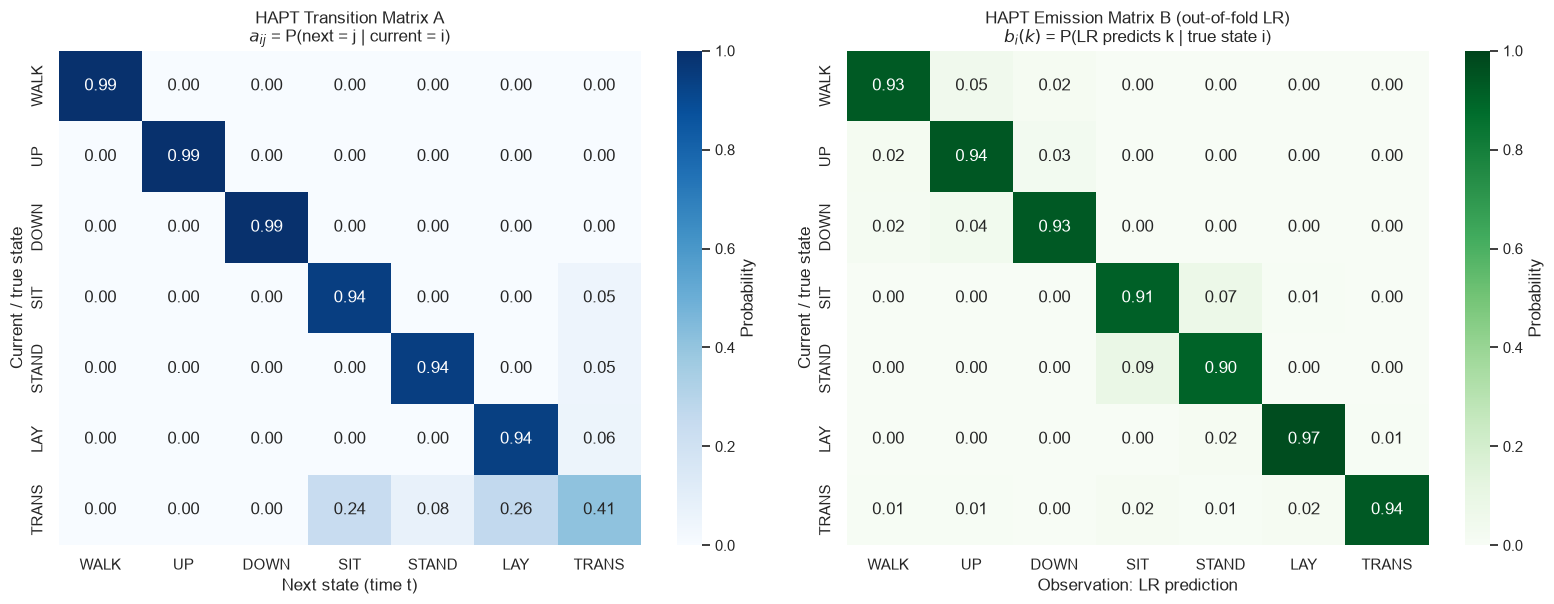

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, matrix, title, cmap, xlabel in [
        (axes[0], hapt_A, "HAPT Transition Matrix A\n$a_{ij}$ = P(next = j | current = i)", "Blues", "Next state (time t)"),
        (axes[1], hapt_B, "HAPT Emission Matrix B (out-of-fold LR)\n$b_i(k)$ = P(LR predicts k | true state i)", "Greens",
         "Observation: LR prediction")]:
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap=cmap, vmin=0, vmax=1, ax=ax,
                xticklabels=HAPT_SHORT, yticklabels=HAPT_SHORT, cbar_kws={"label": "Probability"})
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Current / true state")
plt.tight_layout()
plt.show()

**Reading the HAPT matrices.** Unlike the v1 matrix in Section 7, $A$ now contains **directly observed** activity changes. The postures (SIT, STAND, LAY) move only into TRANSITION, and TRANSITION has a low self-probability because transitions last only 1–2 windows. The walking activities have almost no off-diagonal mass, because walking activities are always separated by unlabelled gaps, which end the sequence. $B$ shows that LR detects TRANSITION windows reasonably well, while SIT ↔ STAND remains its main confusion.

### 11.3 Fixed-Lag Decoding (a Real-time Compromise)

Viterbi and Forward–Backward are offline. The Forward filter is real-time but reacts late to changes. A **fixed-lag decoder** announces the state of window $t$ after seeing $L$ more windows, a delay of $L \times 1.28$ s:
$$\gamma^{(L)}_t(i) \propto \alpha_t(i)\, \beta^{(t+L)}_t(i), \qquad \beta^{(t+L)}_t(i) = P(o_{t+1},\dots,o_{t+L} \mid q_t = i)$$
$L = 0$ is the Forward filter. When $L$ reaches the end of the sequence it becomes Forward–Backward posterior decoding. Both limits are checked with asserts below.

In [84]:
def fixed_lag_decode(obs, pi, A, B, lag):
    alpha, _, _ = forward(obs, pi, A, B)
    T = len(obs)
    decisions = np.empty(T, dtype=int)
    for t in range(T):
        beta = np.ones(len(pi))
        for s in range(min(t + lag, T - 1), t, -1):
            beta = A @ (B[:, obs[s]] * beta)
            beta /= beta.sum()
        decisions[t] = (alpha[t] * beta).argmax()
    return decisions

longest = max(hapt_test_seqs, key=len)
o = hapt_test_obs[longest]
check_alpha, check_scale, _ = forward(o, hapt_pi, hapt_A, hapt_B)
assert (fixed_lag_decode(o, hapt_pi, hapt_A, hapt_B, 0) == check_alpha.argmax(axis=1)).all()
assert (fixed_lag_decode(o, hapt_pi, hapt_A, hapt_B, len(o)) ==
        posterior(check_alpha, backward(o, hapt_A, hapt_B, check_scale)).argmax(axis=1)).all()
print("Fixed-lag decoder: lag 0 = Forward filter ✓, full lag = Forward-Backward ✓")

Fixed-lag decoder: lag 0 = Forward filter ✓, full lag = Forward-Backward ✓


### 11.4 Results on Real Sequences with Transitions (HAPT test subjects)

In [85]:
FIXED_LAGS = [1, 2, 3, 5]
hapt_decoded = decode_sequences(hapt_test_seqs, hapt_test_obs, hapt_pi, hapt_A, hapt_B)
for lag in FIXED_LAGS:
    pred = np.full(len(hapt_test_obs), -1)
    for idx in hapt_test_seqs:
        pred[idx] = fixed_lag_decode(hapt_test_obs[idx], hapt_pi, hapt_A, hapt_B, lag)
    hapt_decoded[f"HMM Fixed-lag L={lag} ({lag * WINDOW_STEP_SECONDS:.2f} s)"] = pred
method_order = METHODS[:3] + [m for m in hapt_decoded if "Fixed-lag" in m] + METHODS[3:]
hapt_decoded = {m: hapt_decoded[m] for m in method_order}

hapt_results = evaluate_methods(hapt_decoded, hapt_test_seqs, hapt_test_states, hapt_test_obs)
hapt_results["TRANSITION F1"] = [f1_score(hapt_test_states == 6, pred == 6) for pred in hapt_decoded.values()]
print(f"{len(hapt_test_seqs)} test sequences, {len(hapt_test_obs)} windows, "
      f"true activity changes = {true_changes(hapt_test_seqs, hapt_test_states)}")
hapt_results.round(4)

183 test sequences, 3162 windows, true activity changes = 170


,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Activity changes predicted,Errors fixed vs LR,New errors vs LR,TRANSITION F1
Independent (LR),0.9551,0.9572,0.9550,0.9553,298,0,0,0.9581
Markov chain,0.9042,0.8640,0.8584,0.8601,276,64,225,0.4403
HMM Forward (online),0.9649,0.9665,0.9641,0.9648,221,55,24,0.9639
HMM Fixed-lag L=1 (1.28 s),0.9674,0.9683,0.9665,0.9669,211,56,17,0.9610
HMM Fixed-lag L=2 (2.56 s),0.9703,0.9700,0.9690,0.9689,198,68,20,0.9552
HMM Fixed-lag L=3 (3.84 s),0.9709,0.9703,0.9698,0.9694,192,69,19,0.9524
HMM Fixed-lag L=5 (6.40 s),0.9722,0.9715,0.9711,0.9706,187,74,20,0.9524
HMM Forward-Backward,0.9728,0.9720,0.9717,0.9712,183,73,17,0.9524
HMM Viterbi,0.9760,0.9743,0.9745,0.9739,180,82,16,0.9524


In [86]:
hapt_lr_pred, hapt_vit_pred = hapt_decoded["Independent (LR)"], hapt_decoded["HMM Viterbi"]
hapt_per_class = pd.DataFrame({
    "Support": np.bincount(hapt_test_states, minlength=N_HAPT),
    "F1 LR": f1_score(hapt_test_states, hapt_lr_pred, average=None, labels=range(N_HAPT)),
    "F1 Viterbi": f1_score(hapt_test_states, hapt_vit_pred, average=None, labels=range(N_HAPT)),
}, index=HAPT_STATES)
hapt_per_class["F1 change"] = hapt_per_class["F1 Viterbi"] - hapt_per_class["F1 LR"]
hapt_per_class.round(4)

,Support,F1 LR,F1 Viterbi,F1 change
WALKING,496,0.9686,0.9841,0.0156
WALKING_UPSTAIRS,471,0.9498,0.9743,0.0245
WALKING_DOWNSTAIRS,420,0.9647,0.9916,0.0269
SITTING,508,0.9149,0.9519,0.0370
STANDING,556,0.9345,0.9643,0.0298
LAYING,545,0.9963,0.9991,0.0028
TRANSITION,166,0.9581,0.9524,-0.0057


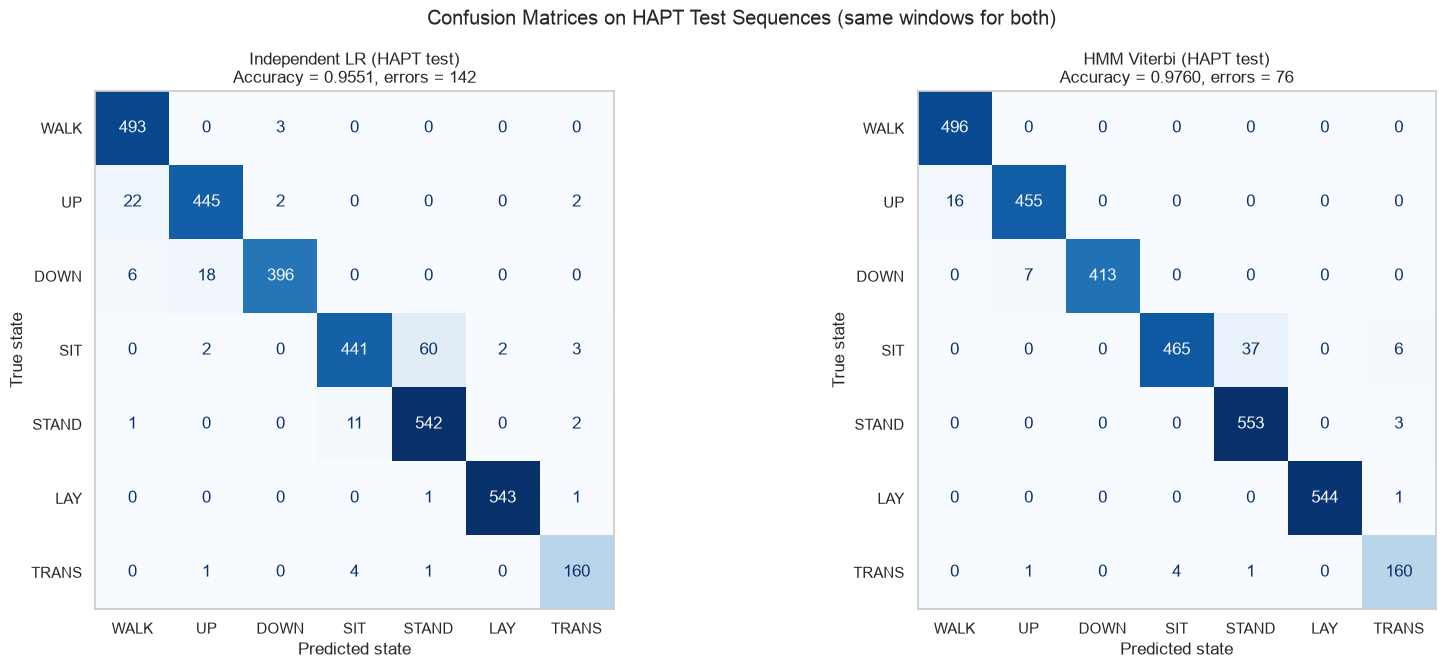

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.8))
for ax, (title, pred) in zip(axes, [("Independent LR", hapt_lr_pred), ("HMM Viterbi", hapt_vit_pred)]):
    cm = confusion_matrix(hapt_test_states, pred, labels=range(N_HAPT))
    ConfusionMatrixDisplay(cm, display_labels=HAPT_SHORT).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{title} (HAPT test)\nAccuracy = {accuracy_score(hapt_test_states, pred):.4f}, "
                 f"errors = {(pred != hapt_test_states).sum()}")
    ax.set_xlabel("Predicted state")
    ax.set_ylabel("True state")
    ax.grid(False)
plt.suptitle("Confusion Matrices on HAPT Test Sequences (same windows for both)")
plt.tight_layout()
plt.show()

**Example sequence.** We plot the HAPT test sequence with the **most true activity changes**, chosen by this rule, independent of the results. This shows how each method handles real transitions.

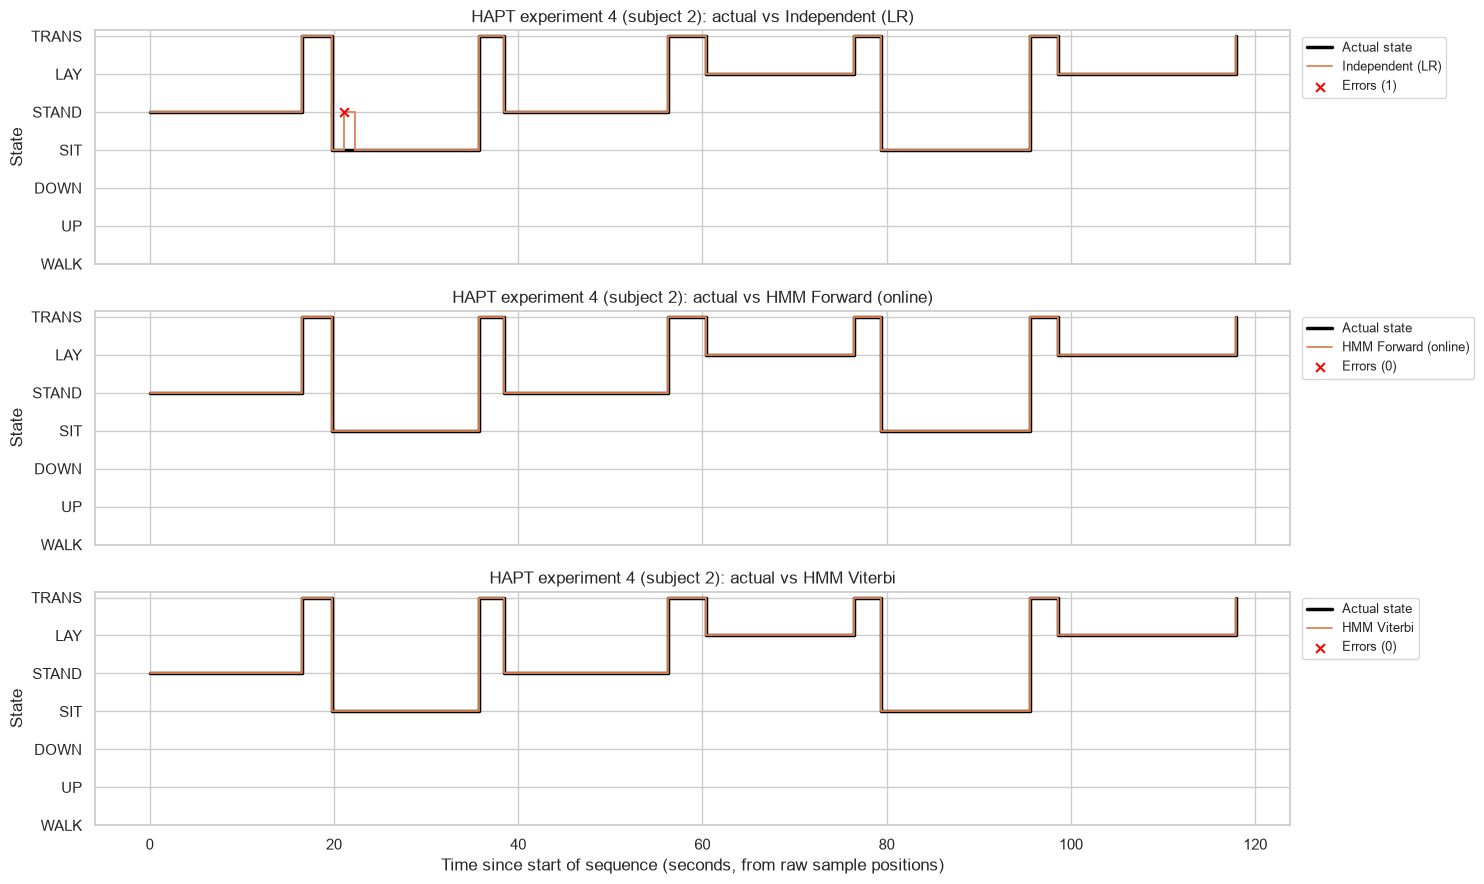

In [88]:
example = max(hapt_test_seqs, key=lambda idx: (np.diff(hapt_test_states[idx]) != 0).sum())
row = hapt_test_table.iloc[example[0]]
seconds = (hapt_test_table["win_start"].to_numpy()[example] - hapt_test_table["win_start"].iloc[example[0]]) / 50

fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)
for ax, name in zip(axes, ["Independent (LR)", "HMM Forward (online)", "HMM Viterbi"]):
    truth, guess = hapt_test_states[example], hapt_decoded[name][example]
    ax.step(seconds, truth, where="post", color="black", linewidth=2.5, label="Actual state")
    ax.step(seconds, guess, where="post", color="#DD8452", linewidth=1.3, label=name)
    wrong = guess != truth
    ax.scatter(seconds[wrong], guess[wrong], color="red", marker="x", s=40, zorder=3, label=f"Errors ({wrong.sum()})")
    ax.set_yticks(range(N_HAPT), HAPT_SHORT)
    ax.set_ylabel("State")
    ax.set_title(f"HAPT experiment {row['exp']} (subject {row['user']}): actual vs {name}")
    ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9)
axes[-1].set_xlabel("Time since start of sequence (seconds, from raw sample positions)")
plt.tight_layout()
plt.show()

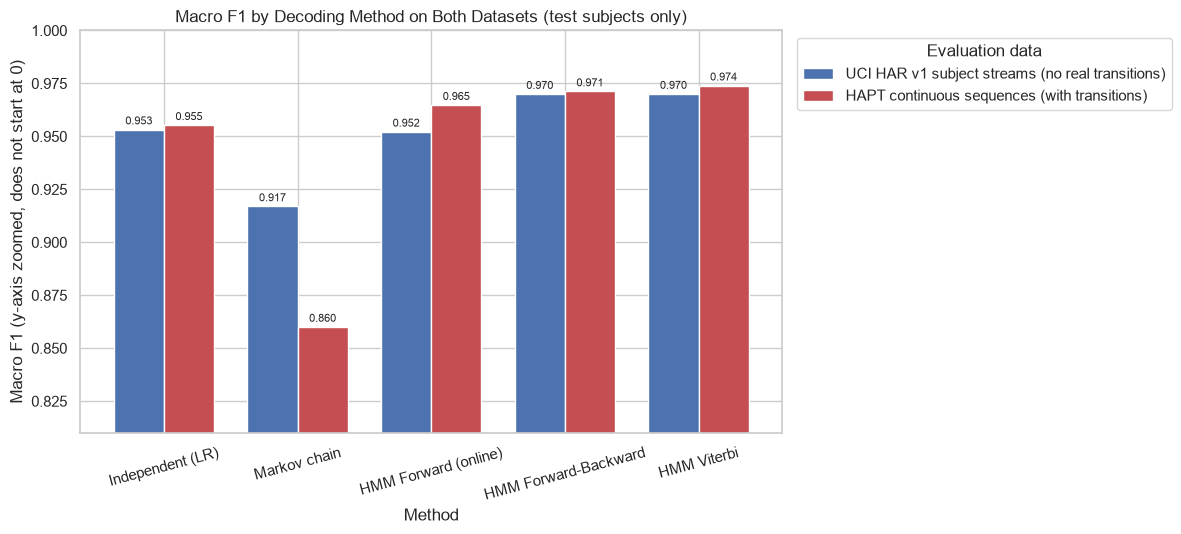

In [89]:
comparison_methods = METHODS
both = pd.DataFrame({
    "UCI HAR v1 subject streams (no real transitions)": stream_results.loc[comparison_methods, "F1-score (macro)"],
    "HAPT continuous sequences (with transitions)": hapt_results.loc[comparison_methods, "F1-score (macro)"],
})
ax = both.plot(kind="bar", figsize=(12, 5.5), width=0.75, color=["#4C72B0", "#C44E52"])
ax.set_ylim(max(0, both.min().min() - 0.05), 1.0)
ax.set_title("Macro F1 by Decoding Method on Both Datasets (test subjects only)")
ax.set_xlabel("Method")
ax.set_ylabel("Macro F1 (y-axis zoomed, does not start at 0)")
ax.legend(title="Evaluation data", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

### 11.5 Discussion of the HAPT Results

These are real chronological sequences: activity changes are observed directly, every step is measured from raw sample positions, and all parameters come from training subjects.

**Temporal decoding helps on real sequences too.** Viterbi raises accuracy from **0.9551 to 0.9760** and macro F1 from **0.9553 to 0.9739**. It fixes 82 LR errors and adds 16. The predicted number of activity changes falls from 298 to 180, against 170 true changes. The gain is similar in size to v1 (+1.7 points there, +2.1 here), so the v1 result was not an artefact of its gaps.

**Unlike v1, the online Forward filter now helps:** 0.9551 → 0.9649, with 55 errors fixed and 24 new (on v1 it was 60 fixed and 60 new). In HAPT every posture change passes through a TRANSITION state that LR detects well ($b \approx 0.94$) and that $A$ expects. The filter therefore receives early evidence of a change instead of lagging behind it.

**Fixed-lag decoding trades delay for accuracy.** Accuracy rises steadily with the lag: 0.9674 at $L=1$ (1.28 s), 0.9703 at $L=2$ (2.56 s), 0.9709 at $L=3$ and 0.9722 at $L=5$, approaching Forward–Backward (0.9728). A delay of about 2.5 s recovers roughly two-thirds of the gap between online filtering and full offline posterior decoding. This is the practical choice for a live system.

**Which classes benefit?** SITTING (F1 +0.037), STANDING (+0.030) and the three walking activities (+0.016 to +0.027) improve. LAYING was already almost perfect (+0.003).

**What gets worse?** TRANSITION F1 falls slightly with Viterbi (0.9581 → 0.9524), while the online filter improves it (0.9639). Transitions last only 1–2 windows, exactly the kind of short event that smoothing tends to absorb into the neighbouring posture. The plain Markov chain is again much worse (0.9042, TRANSITION F1 0.44) because it is always one window late.

**Limitations specific to HAPT**
- Transitions between *walking* activities are never observed directly. Unlabelled samples always separate them, so they end a sequence, and $A$ has almost no off-diagonal mass for walking states.
- Sequences are short (median 9 windows) because unlabelled samples break the recordings.
- Steps at interval boundaries are 2.56–3.8 s rather than 1.28 s.
- The protocol is still scripted.

# REVIEW 3 – KEY FINDINGS AND VIVA PREPARATION

## Overall Workflow

```
UCI HAR v1 (561 features, 2.56 s windows, 50 % overlap)          HAPT v2.1 (same experiment + continuous recordings + transitions)
        │                                                                   │
Module 1: LR / SVM / RF  (+ Unit 5: pruned CART, Gradient Boosting)         │  official windows mapped to (experiment, time), verified row by row
        │  best: Logistic Regression, 95.35 %                               │  7 states = 6 activities + TRANSITION
        ▼                                                                   ▼
Module 2: temporal audit (overlap test) → Markov chain A, π → HMM emission B (out-of-fold) → Forward / Backward / Viterbi / fixed-lag
        └─ compare on identical windows: independent vs Markov chain vs HMM decoders (v1 Section 10, HAPT Section 11)
```

## Algorithms Implemented
| Area | Algorithm | Key idea |
|---|---|---|
| Classification (Module 1) | Logistic Regression, SVM (RBF), Random Forest | Independent per-window classifiers |
| Unit 5 | CART with cost-complexity pruning | Greedy binary splits minimising Gini impurity; $\alpha$ chosen by subject-wise CV |
| Unit 5 | Gradient Boosting (HistGradientBoosting) | Sequential trees, each correcting the previous ones' errors (boosting vs RF's bagging) |
| Module 2 | Markov chain estimation | Counting transitions + Laplace smoothing (MLE) |
| Module 2 | HMM emissions | Counting (true, predicted) pairs from out-of-fold predictions |
| Module 2 | Forward (scaled), Backward (scaled) | Sum over paths; posterior $\gamma_t = \alpha_t\beta_t / P(O)$ |
| Module 2 | Viterbi (log space) | Max over paths, back-pointers, backtracking |
| Module 2 | Fixed-lag decoding | Forward plus a backward pass over only $L$ future windows |

## Mathematical Concepts Demonstrated
- **Markov models:** states, transitions, the Markov property, the row-stochastic transition matrix, and expected duration $1/(1-a_{ii})$.
- **HMMs:** initial, transition and emission probabilities, and the two independence assumptions.
- **Dynamic programming:** $O(TN^2)$ instead of $O(N^T)$.
- **Estimation and numerics:** MLE with Laplace smoothing, and underflow handled by scaling and log probabilities.
- **Decoding:** filtering vs fixed-lag vs smoothing vs most-probable path.
- **Trees and ensembles:** Gini impurity, cost-complexity pruning $R_\alpha(T) = R(T) + \alpha|T|$, and bagging vs boosting.

## Results Summary

**Module 1 + Unit 5: independent classifiers (UCI HAR v1 test, 2947 windows)**

| Model | Accuracy | Macro F1 |
|---|---|---|
| Logistic Regression | 0.9535 | 0.9532 |
| SVM (RBF) | 0.9518 | 0.9511 |
| Random Forest | 0.9291 | 0.9275 |
| Gradient Boosting | 0.9281 | 0.9275 |
| CART (pruned, ccp_alpha = 0.002) | 0.8694 | 0.8652 |

**Module 2: temporal decoding of LR predictions (test subjects only)**

| Method | v1 streams Acc / F1 | HAPT sequences Acc / F1 |
|---|---|---|
| Independent LR | 0.9535 / 0.9532 | 0.9551 / 0.9553 |
| Markov chain | 0.9182 / 0.9169 | 0.9042 / 0.8601 |
| HMM Forward (online) | 0.9535 / 0.9522 | 0.9649 / 0.9648 |
| HMM Fixed-lag L=2 (2.56 s delay) | – | 0.9703 / 0.9689 |
| HMM Forward–Backward | 0.9701 / 0.9700 | 0.9728 / 0.9712 |
| **HMM Viterbi** | **0.9701 / 0.9700** | **0.9760 / 0.9739** |

## Key Observations
1. **Classification:** the linear models are best on these hand-engineered features. A single pruned tree is about 8 points worse. Bagging (RF) and boosting tie, and both recover most of that gap.
2. **Temporal decoding** improves the best classifier on both datasets: +1.7 points of accuracy on v1 and +2.1 on HAPT, where the sequences contain real, directly observed transitions.
3. **Where the gains come from:** the HMM fixes **short, isolated** errors (85 % of single-window errors on v1) but never fixes long runs of consistent errors (0 % of runs ≥ 5 windows). It can make a subject worse (v1 subject 10: 41 → 47 errors).
4. **Persistence matters most:** on v1, a persistence-only transition matrix keeps most of the gain (0.9688 vs 0.9701).
5. **Real-time use:** the online filter helps on HAPT (+1.0 point) but not on v1. A 2.56 s fixed lag recovers about two-thirds of the offline gain.
6. **Brief events suffer:** smoothing slightly lowers TRANSITION F1 (0.9581 → 0.9524 with Viterbi).

## Limitations
- **v1:** transitions were removed by the dataset authors, so v1 activity changes cross gaps. HAPT addresses this, but even in HAPT, changes between walking activities are never observed directly.
- **Scripted protocol:** the transition structure would not transfer unchanged to free-living data.
- **Overlapping windows** make neighbouring observations correlated, which violates output independence.
- **Model form:** first-order and time-homogeneous, so state durations are geometric. Observations are discrete labels, which discards classifier confidence.
- **Small test set:** 9 test subjects, so differences of a few windows are not statistically meaningful.
- **HAPT sequences** are short (median 9 windows), and steps at interval boundaries are 2.56–3.8 s instead of 1.28 s.

## Likely Viva Questions

**1. What is the Markov property, and is it realistic here?**
The next state depends only on the current state. It is an approximation, but a reasonable one for 1.28 s steps, because activities persist.

**2. What are the hidden states and the observations?**
The hidden states are the true activities: 6 for v1, and 6 + TRANSITION for HAPT. The observations are the Logistic Regression predictions for each window.

**3. How were A, B and π estimated? Did you use Baum–Welch?**
No. The training labels are known, so we used supervised counting (MLE) with Laplace smoothing. Baum–Welch (EM) is for unlabelled states.

**4. Why use out-of-fold predictions for B?**
LR is 99.6 % accurate on its own training rows, which would make B almost the identity matrix. GroupKFold by subject imitates unseen subjects without touching the test set.

**5. How did you prove the sequences are chronological?**
- **v1:** with 50 % overlap, the second half of window $t$ must equal the first half of window $t+1$ in the raw signals. 92 % of pairs match exactly, and none crosses an activity change.
- **HAPT:** we rebuilt every official window from `labels.txt`, and the rebuilt table matches all 10,929 official labels and subject IDs row by row.

**6. Why 7 states instead of 12 for HAPT?**
Some transitions have very few windows (SIT_TO_STAND: 23 training windows), so 12-state estimates would be unreliable. Merging them keeps every posture change inside the sequences.

**7. Forward vs Viterbi: why sum vs max?**
Forward computes the total probability of the observations over *all* paths. Viterbi keeps only the *best* path, plus back-pointers so the path can be recovered.

**8. How did you handle underflow?**
Forward and Backward normalise each step by a scale factor, and $\log P(O\mid\lambda) = \sum_t \log c_t$. Viterbi works in log probabilities.

**9. What is the Backward algorithm for?**
It gives the probability of the future observations from each state. Combined with Forward it yields the posterior $\gamma_t(i)$, which is also used by Baum–Welch.

**10. Can Viterbi and posterior decoding disagree?**
Yes. In the toy example, posterior decoding gives (S, M, S) and Viterbi gives (S, S, S): one optimises individual windows, the other the whole sequence.

**11. Why is the plain Markov chain worse than the classifier?**
Self-transitions dominate, so it just repeats the previous prediction. It ignores the current sensor evidence and is late at every change.

**12. Can this run in real time?**
Viterbi is offline. The Forward filter is real-time. Fixed-lag decoding waits $L$ windows: at $L=2$ (2.56 s delay), HAPT accuracy is 0.9703 vs 0.9649 for the filter and 0.9728 for full offline Forward–Backward.

**13. When does the HMM fail?**
When the classifier is consistently wrong for many windows, and for very short events such as transitions, which smoothing can absorb.

**14. Explain CART and Gini impurity.**
CART recursively makes binary splits $x_j \le t$ that most reduce the weighted Gini impurity $G = 1 - \sum_k p_k^2$. Cost-complexity pruning minimises $R(T) + \alpha|T|$. We chose $\alpha$ by subject-wise CV on training data (0.002: depth 9, 32 leaves).

**15. Bagging vs boosting?**
- **Bagging (Random Forest):** trains deep trees independently on bootstrap samples and averages them, which reduces variance.
- **Boosting:** trains shallow trees sequentially, each one correcting the errors of the previous ones, which reduces bias.

Here both reach a macro F1 of 0.9275, but they make different errors.

**16. Why are feature importances unstable?**
8206 feature pairs have $|r| > 0.9$, so importance is shared out arbitrarily between correlated copies. CART concentrates 97 % of its importance in 15 features, while RF spreads it (31 % in its top 15).

**17. What is the time complexity?**
$O(TN^2)$ for Forward, Backward and Viterbi, and $O(TLN^2)$ for fixed-lag decoding, compared with $O(N^T)$ for brute-force enumeration of all paths.

**18. How could the model be improved?**
Use soft emissions from class probabilities, duration models (hidden semi-Markov models), and evaluation on free-living data.

---
## Overall conclusion

* **Unit 1:** classes are balanced, motion features are highly correlated, and activity changes the mean and spread of the sensor features sharply (dynamic vs static).
* **Units 2-3:** every algorithm was implemented from scratch and verified against a library reference; the unsupervised methods find the dynamic/static split but struggle to separate SITTING from STANDING.
* **Units 4-5:** the best single-window classifier is Logistic Regression (95.35 % test accuracy, §5). Every tree model is worse (pruned CART 86.9 %, Random Forest 92.9 %, Gradient Boosting 92.8 %), because the engineered features are almost linearly separable. HMM/Viterbi decoding on top of LR lifts accuracy from 95.35 % to 97.01 % on the UCI subject streams and from 95.51 % to 97.60 % on the continuous HAPT recordings with real transitions; it is not uniformly better (the plain Markov chain is worse, and long runs of classifier errors are not corrected).
* **Main limitation:** SITTING vs STANDING remains the hardest pair for every model.